# MEIA_G01 — O paradoxo da Inteligência Artificial
**MEIA 2026/2027 · Docente Liliana Coelho · Grupo G01**

Notebook de investigação e exercícios adaptados. Dados sintéticos, sem interpretação causal.
Preencher identificação dos dois autores antes da entrega. A assistência de IA foi usada na organização,
adaptação de código, análise e redação; os autores devem verificar e dominar as decisões para a defesa.

**Execução:** em Colab, executar todas as células por ordem e carregar `Base_Dados_IA_Produtividade.xlsx`
quando solicitado. No computador, colocar o Excel junto do notebook ou na pasta imediatamente acima.
O original é apenas lido; as saídas são gravadas em `resultados/`. Não são necessárias as pastas de apoio
para executar, porque todo o código e as fórmulas estão incluídos aqui. As saídas guardadas documentam
a execução local validada; ao executar no Colab, podem ocorrer pequenas diferenças entre versões.

**Percurso:** preparação → exploração → associação → inferência → regressões → diagnósticos →
sensibilidade e validação → exercícios complementares → respostas e metodologia.
Os títulos das células identificam as etapas. O painel de índice do Colab permite navegar.


### Resumo

A base contém 241 registos e 240 colaboradores. Removemos uma duplicação exata e uniformizámos três nomes de departamentos, preservando todos os valores numéricos originais. A associação entre utilização semanal de IA e produtividade é positiva mas fraca: r = 0,241 (n = 236; p = 0,000187). O modelo simples explica 5,8% da variabilidade. Na mesma amostra de 233 casos, o coeficiente de IA passa de 0,639 para 0,144 pontos por hora quando se ajusta por experiência, formação, complexidade, carga de trabalho e departamento. O intervalo robusto HC3 de 95% do coeficiente ajustado é [−0,230; 0,517], com p = 0,450. A associação marginal não se traduz, portanto, em evidência clara de associação independente no modelo adotado. Não encontramos evidência de diferenças de produtividade média entre departamentos (Welch: p = 0,681). Estes resultados não permitem concluir causalidade nem fundamentam tornar obrigatória a utilização de IA.

### Problema, estratégia e transparência

A questão é saber em que medida o uso de IA está associado à produtividade e como essa associação muda ao considerar outros fatores. A unidade estatística é o colaborador; a resposta é a pontuação de produtividade. Considerámos plausível uma associação positiva, mas também que experiência e formação expliquem parte dela. Esta expectativa orienta a leitura; não é apresentada como hipótese pré-registada antes de conhecer os dados.

Usamos α = 0,05, testes bilaterais salvo os exercícios pedagógicos explicitamente unilaterais, intervalos de confiança, magnitudes e diagnósticos. Um valor-p não é a probabilidade de a hipótese nula ser verdadeira. Os cálculos inferenciais pressupõem observações independentes e um mecanismo amostral/modelo que os dados sintéticos não documentam. Interpretamo-los como demonstrações condicionais desses métodos. As fórmulas completas, as escolhas e a proveniência do código constam de METODOLOGIA.md e do notebook; os CSV permitem auditar os números sem arredondamento.



In [1]:
# Instalação condicional: só instala se faltar uma biblioteca necessária.
import importlib.util, subprocess, sys
pacotes={'numpy':'numpy','pandas':'pandas','scipy':'scipy','statsmodels':'statsmodels',
         'matplotlib':'matplotlib','seaborn':'seaborn','sklearn':'scikit-learn','openpyxl':'openpyxl'}
em_falta=[p for m,p in pacotes.items() if importlib.util.find_spec(m) is None]
if em_falta:
    subprocess.check_call([sys.executable,'-m','pip','install','-q',*em_falta])
print('Bibliotecas disponíveis. Versões efetivas serão registadas no final.')

Bibliotecas disponíveis. Versões efetivas serão registadas no final.


## 0. Bibliotecas, ficheiro e reprodutibilidade

**Pergunta e abordagem:** Objetivo: carregar o ficheiro correto, preservar a fonte e fixar a semente.

In [2]:
from pathlib import Path
import json, hashlib, sys, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset, lilliefors
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.proportion import proportion_confint, proportions_ztest, confint_proportions_2indep
from IPython.display import display

SEED, ALPHA = 42, .05
rng = np.random.default_rng(SEED)
BASE = Path.cwd()
candidatos = [BASE/'Base_Dados_IA_Produtividade.xlsx', BASE.parent/'Base_Dados_IA_Produtividade.xlsx']
FICHEIRO = next((p for p in candidatos if p.exists()), None)
if FICHEIRO is None:
    from google.colab import files
    enviados = files.upload()
    FICHEIRO = Path(next(n for n in enviados if n.endswith('.xlsx')))
OUT = BASE/'resultados'
OUT.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', palette='colorblind', font_scale=.95)
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':180})
R = {'seed':SEED,'ficheiro_sha256':hashlib.sha256(FICHEIRO.read_bytes()).hexdigest()}
def guardar(nome, tabela):
    tabela.to_csv(OUT/f'{nome}.csv',index=True,encoding='utf-8-sig')
    return tabela
def figura(nome):
    plt.tight_layout(); plt.savefig(OUT/f'{nome}.png',bbox_inches='tight'); plt.show(); plt.close()
def resultado(teste):
    return {'estatistica':float(teste.statistic),'p':float(teste.pvalue)}
def ic_media(x):
    x = pd.Series(x).dropna()
    return list(stats.t.interval(.95,len(x)-1,loc=x.mean(),scale=stats.sem(x)))

## 1. EDA: importação e auditoria antes de corrigir

**Pergunta e abordagem:** Antes de corrigir, verificar dimensões, faltas, IDs e categorias. Não presumir que todas as linhas são pessoas diferentes.

In [3]:
# Docente: Aulas 1–3, read_excel, info, describe, isna, duplicated.
# Adaptação: header=0 porque a folha deste TP começa na primeira linha.
brutos = pd.read_excel(FICHEIRO,sheet_name='Dados',header=0)
dicionario = pd.read_excel(FICHEIRO,sheet_name='Dicionario')
brutos.columns = brutos.columns.str.strip()
print('Registos/variáveis:',brutos.shape,'| Colaboradores:',brutos.id_colaborador.nunique())
brutos.info()
display(brutos.head()); display(dicionario)
guardar('faltas_antes',brutos.isna().sum().to_frame('em_falta'))
display(brutos.loc[brutos.id_colaborador.duplicated(keep=False)])
display(brutos.departamento.value_counts(dropna=False))
R['auditoria']={'n_bruto':len(brutos),'n_ids':brutos.id_colaborador.nunique(),
    'faltas_antes':brutos.isna().sum().to_dict(),'duplicados_exatos':int(brutos.duplicated().sum())}

Registos/variáveis: (241, 11) | Colaboradores: 240
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 241 entries, 0 to 240
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id_colaborador            241 non-null    object 
 1   departamento              241 non-null    object 
 2   experiencia_anos          240 non-null    float64
 3   formacao_ia_horas         240 non-null    float64
 4   uso_ia_horas              239 non-null    float64
 5   complexidade_tarefas      240 non-null    float64
 6   carga_trabalho_horas      241 non-null    float64
 7   tarefas_concluidas        241 non-null    int64  
 8   tempo_medio_tarefa_horas  240 non-null    float64
 9   qualidade_trabalho        241 non-null    float64
 10  produtividade             239 non-null    float64
dtypes: float64(8), int64(1), object(2)
memory usage: 20.8+ KB


,id_colaborador,departamento,experiencia_anos,formacao_ia_horas,uso_ia_horas,complexidade_tarefas,carga_trabalho_horas,tarefas_concluidas,tempo_medio_tarefa_horas,qualidade_trabalho,produtividade
0,C001,Operações,0.5,7.7,7.7,3.0,43.7,25,1.03,81.6,68.0
1,C002,Operações,3.5,1.4,1.7,2.0,34.6,30,2.10,77.0,60.3
2,C003,Comunicação,14.0,3.3,9.2,3.0,36.8,30,3.25,85.3,89.8
3,C004,Análise de Dados,2.0,12.4,16.3,3.0,40.5,28,4.02,100.0,70.3
4,C005,Desenvolvimento,8.0,14.2,6.0,4.0,39.2,19,3.00,77.6,83.0


,Variável,Natureza / unidade,Definição e observações
0,id_colaborador,Identificador,Código anonimizado de colaborador; cada pessoa...
1,departamento,Qualitativa nominal,Área de atividade; quatro categorias de referê...
2,experiencia_anos,Quantitativa / anos,Tempo de experiência profissional.
3,formacao_ia_horas,Quantitativa / horas,Formação acumulada em ferramentas de IA no per...
4,uso_ia_horas,Quantitativa / horas/semana,Tempo médio semanal de utilização de ferrament...
5,complexidade_tarefas,Ordinal / 1–5,Complexidade média atribuída por avaliação int...
6,carga_trabalho_horas,Quantitativa / horas/semana,Horas médias de trabalho na semana.
7,tarefas_concluidas,Contagem / tarefas,Número de tarefas concluídas no período; depen...
8,tempo_medio_tarefa_horas,Quantitativa / horas,Tempo médio por tarefa no período.
9,qualidade_trabalho,Pontuação / 0–100,Avaliação de qualidade; indicador distinto do ...


,id_colaborador,departamento,experiencia_anos,formacao_ia_horas,uso_ia_horas,complexidade_tarefas,carga_trabalho_horas,tarefas_concluidas,tempo_medio_tarefa_horas,qualidade_trabalho,produtividade
83,C084,Desenvolvimento,0.5,8.5,5.7,4.0,37.8,22,5.34,64.6,61.1
198,C084,Desenvolvimento,0.5,8.5,5.7,4.0,37.8,22,5.34,64.6,61.1


,count
departamento,
Desenvolvimento,85
Operações,65
Análise de Dados,57
Comunicação,31
desenvolvimento,1
Operacoes,1
Analise de Dados,1


## 2. EDA: correções explícitas e rastreáveis

**Pergunta e abordagem:** Corrigir apenas duplicação exata e variantes inequívocas de grafia; registar cada alteração.

In [4]:
alteracoes=[]
for i in brutos.index[brutos.duplicated()]:
    alteracoes.append({'linha_excel':i+2,'id':brutos.loc[i,'id_colaborador'],'campo':'linha completa',
                      'antes':'cópia exata','depois':'excluída','motivo':'mesma unidade; todos os valores iguais'})
dados=brutos.drop_duplicates().copy()
mapa={'desenvolvimento':'Desenvolvimento','Operacoes':'Operações','Analise de Dados':'Análise de Dados'}
for i,valor in dados.departamento.items():
    novo=mapa.get(valor.strip(),valor.strip())
    if novo != valor:
        alteracoes.append({'linha_excel':i+2,'id':dados.loc[i,'id_colaborador'],'campo':'departamento',
                          'antes':valor,'depois':novo,'motivo':'uniformização ortográfica; mesmo significado'})
        dados.loc[i,'departamento']=novo
assert not dados.id_colaborador.duplicated().any(), 'Há IDs conflituantes: investigar antes de prosseguir.'
numericas=list(dados.select_dtypes(include='number').columns)
assert (dados[numericas].dropna()>=0).all().all()
assert dados.complexidade_tarefas.dropna().isin([1,2,3,4,5]).all()
assert dados[['produtividade','qualidade_trabalho']].stack().dropna().between(0,100).all()
assert (dados.loc[dados.uso_ia_horas.notna(),'uso_ia_horas'] <= dados.loc[dados.uso_ia_horas.notna(),'carga_trabalho_horas']).all()
guardar('registo_limpeza',pd.DataFrame(alteracoes)); guardar('dados_limpos',dados)
guardar('faltas_depois',dados.isna().sum().to_frame('em_falta'))
guardar('registos_com_faltas',dados.loc[dados.isna().any(axis=1)])
R['auditoria'].update(n_limpo=len(dados),alteracoes=alteracoes,registos_com_faltas=int(dados.isna().any(axis=1).sum()))
print('Após preparação:',len(dados),'colaboradores. Sem imputação; casos completos por análise.')
display(pd.DataFrame(alteracoes)); display(dados.isna().sum())

Após preparação: 240 colaboradores. Sem imputação; casos completos por análise.


,linha_excel,id,campo,antes,depois,motivo
0,200,C084,linha completa,cópia exata,excluída,mesma unidade; todos os valores iguais
1,19,C018,departamento,desenvolvimento,Desenvolvimento,uniformização ortográfica; mesmo significado
2,50,C049,departamento,Operacoes,Operações,uniformização ortográfica; mesmo significado
3,103,C102,departamento,Analise de Dados,Análise de Dados,uniformização ortográfica; mesmo significado


,0
id_colaborador,0
departamento,0
experiencia_anos,1
formacao_ia_horas,1
uso_ia_horas,2
complexidade_tarefas,1
carga_trabalho_horas,0
tarefas_concluidas,0
tempo_medio_tarefa_horas,1
qualidade_trabalho,0


## 1. Conhecimento e preparação da base de dados

**1.1 — Dimensão.** Existem 241 linhas, 11 variáveis e 240 identificadores distintos. Uma linha é uma observação de um colaborador, não uma observação semanal repetida.

**1.2 — Repetições.** C084 surge duas vezes com os mesmos valores em todas as colunas. Conservámos a primeira ocorrência e removemos a linha 200 do Excel. Não agregámos os dois registos nem removemos pessoas com valores apenas semelhantes. Depois da operação, cada ID ocorre uma única vez.

**1.3 — Valores em falta.** Há oito células em falta em oito colaboradores: produtividade em C030 e C131; uso de IA em C067 e C113; experiência em C080; formação em C189; complexidade em C202; tempo médio por tarefa em C154. Não há faltas nas restantes variáveis. Não imputámos médias: tal reduziria artificialmente a variabilidade e acrescentaria pressupostos. Usamos casos disponíveis para cada análise e casos completos nas variáveis de cada modelo. A percentagem pequena não demonstra que as faltas sejam aleatórias; desconhecemos o mecanismo.

**1.4 — Tipos de variáveis.** ID é um identificador nominal e departamento uma categoria nominal. Complexidade é ordinal (níveis 1–5), embora esteja armazenada numericamente; tratá-la como numérica no modelo principal supõe incrementos iguais, hipótese examinada por sensibilidade. Tarefas concluídas é uma contagem discreta. Experiência, formação, utilização de IA, carga de trabalho e tempo médio são quantitativas, medidas com arredondamento. Qualidade e produtividade são pontuações quantitativas limitadas; não se presume que zero corresponda a ausência absoluta do atributo. A variável a explicar é produtividade, e não qualidade ou número de tarefas.

**1.5 — Grafias e valores a examinar.** Uniformizámos desenvolvimento → Desenvolvimento (C018, linha 19), Operacoes → Operações (C049, linha 50) e Analise de Dados → Análise de Dados (C102, linha 103). As linhas referem-se ao Excel original, contando o cabeçalho. Os limites de Tukey, Q1 − 1,5×AIQ e Q3 + 1,5×AIQ, sinalizam valores, mas não demonstram erros. No uso de IA, o limite superior é 21,2 horas e os casos sinalizados são C035 (24,8) e C134 (25). Na produtividade, C097 (19) e C129 (43,5) ficam abaixo de 44,3875. Foram mantidos: não há fonte que autorize substituir valores válidos por estimativas. Há 13 pontuações iguais ao máximo observado, 98; isto sugere acumulação no topo, mas não demonstra um mecanismo de censura. O registo integral está em resultados/registo_limpeza.csv; as sinalizações estão em extremos_iqr.csv.

**1.6 — Amostras efetivas.** Permanecem 240 colaboradores. As médias de produtividade e de uso de IA usam, cada uma, 238; a associação e regressão simples usam 236; as regressões comparadas na mesma amostra usam 233. O complemento de classificação usa 234 casos. Um colaborador com uma falta irrelevante para determinado cálculo continua incluído nesse cálculo. O ficheiro original não foi alterado; a exportação limpa é um produto separado.



## 3. EDA: centro, dispersão, frequências e extremos

**Pergunta e abordagem:** A média pode ocultar assimetria e extremos. Comparar mediana, dispersão, quartis e formas gráficas.

,count,mean,std,min,25%,50%,75%,max,IQR,amplitude,assimetria,variancia,limite_inf,limite_sup
experiencia_anos,239.0,5.845607,3.983608,0.3,2.950,5.00,8.100,19.00,5.150,18.70,1.050438,15.869130,-4.7750,15.8250
formacao_ia_horas,239.0,9.343933,7.005906,0.1,4.200,7.60,12.800,36.00,8.600,35.90,1.285845,49.082726,-8.7000,25.7000
uso_ia_horas,238.0,7.718487,4.931659,0.0,3.825,7.60,10.775,25.00,6.950,25.00,0.588121,24.321260,-6.6000,21.2000
complexidade_tarefas,239.0,2.953975,1.013550,1.0,2.000,3.00,4.000,5.00,2.000,4.00,0.068293,1.027285,-1.0000,7.0000
carga_trabalho_horas,240.0,41.895000,4.323902,29.2,38.875,41.90,44.825,56.00,5.950,26.80,0.123779,18.696126,29.9500,53.7500
tarefas_concluidas,240.0,30.787500,7.158154,12.0,26.000,30.50,36.000,49.00,10.000,37.00,0.101947,51.239174,11.0000,51.0000
tempo_medio_tarefa_horas,239.0,2.785607,1.855555,0.4,1.165,2.59,3.995,8.74,2.830,8.34,0.532846,3.443083,-3.0800,8.2400
qualidade_trabalho,240.0,79.936250,10.596951,55.2,71.575,80.15,87.000,100.00,15.425,44.80,0.001687,112.295375,48.4375,110.1375
produtividade,238.0,78.033613,12.837082,19.0,70.225,79.35,87.450,98.00,17.225,79.00,-0.616295,164.790680,44.3875,113.2875


,n,percentagem
departamento,,
Desenvolvimento,85,35.416667
Operações,66,27.500000
Análise de Dados,58,24.166667
Comunicação,31,12.916667


,id,variavel,valor,limite_inf,limite_sup,decisao
0,C014,experiencia_anos,19.00,-4.7750,15.8250,manter; sinal estatístico não demonstra erro
1,C015,experiencia_anos,19.00,-4.7750,15.8250,manter; sinal estatístico não demonstra erro
2,C178,experiencia_anos,19.00,-4.7750,15.8250,manter; sinal estatístico não demonstra erro
3,C183,experiencia_anos,17.70,-4.7750,15.8250,manter; sinal estatístico não demonstra erro
4,C009,formacao_ia_horas,32.50,-8.7000,25.7000,manter; sinal estatístico não demonstra erro
5,C013,formacao_ia_horas,27.50,-8.7000,25.7000,manter; sinal estatístico não demonstra erro
6,C016,formacao_ia_horas,28.00,-8.7000,25.7000,manter; sinal estatístico não demonstra erro
7,C038,formacao_ia_horas,34.00,-8.7000,25.7000,manter; sinal estatístico não demonstra erro
8,C128,formacao_ia_horas,33.60,-8.7000,25.7000,manter; sinal estatístico não demonstra erro
9,C132,formacao_ia_horas,28.40,-8.7000,25.7000,manter; sinal estatístico não demonstra erro


produtividade                              uso_ia_horas  \
                         count       mean        std median        count   
departamento                                                               
Análise de Dados            58  76.474138  12.569604   77.4           58   
Comunicação                 31  78.596774  11.606650   78.3           30   
Desenvolvimento             85  78.029412  13.972983   80.4           85   
Operações                   64  79.179688  12.197309   79.7           65   

                                             
                      mean       std median  
departamento                                 
Análise de Dados  6.939655  4.572110   7.15  
Comunicação       6.713333  5.311584   6.30  
Desenvolvimento   8.982353  4.751320   8.70  
Operações         7.224615  5.063658   6.60

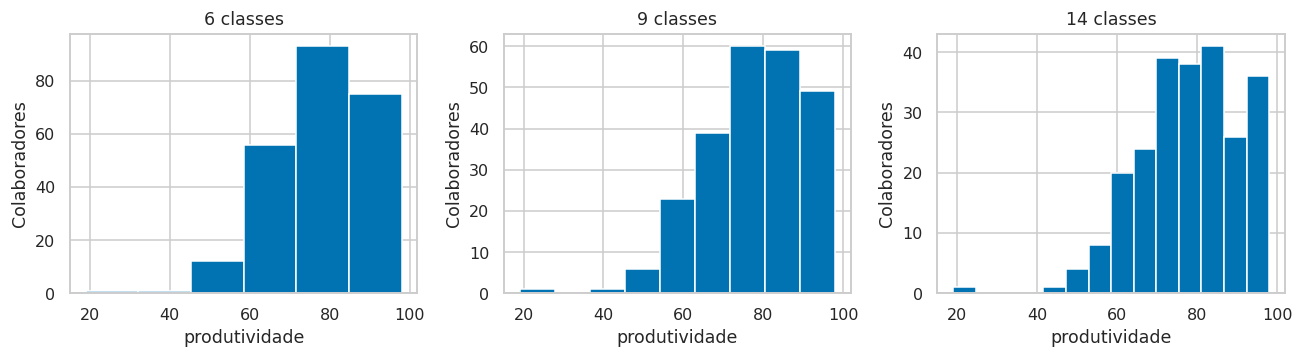

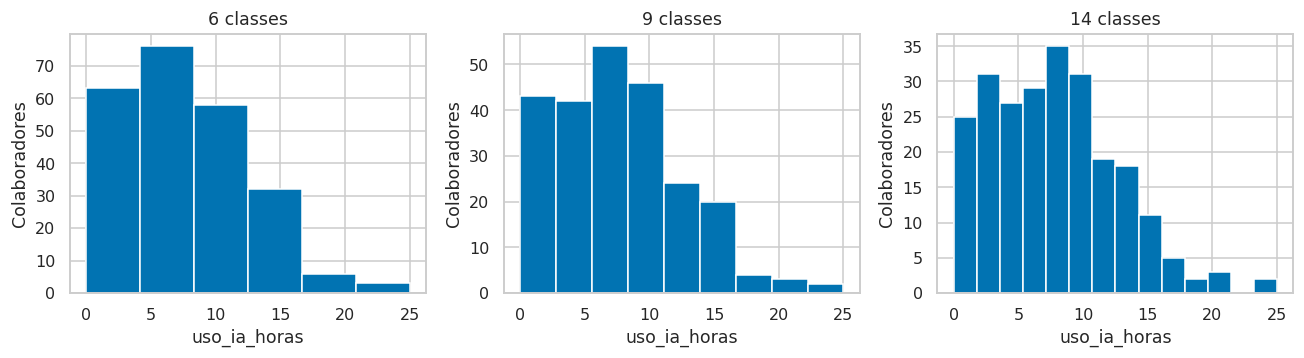

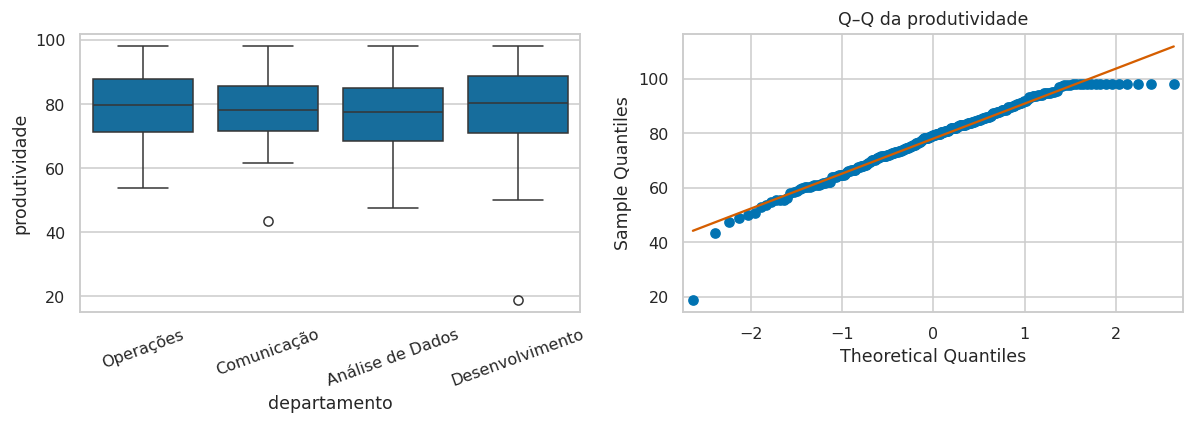

In [5]:
# Docente: describe, quantile, value_counts, histogramas e boxplot.
desc=dados[numericas].describe().T
desc['IQR']=desc['75%']-desc['25%']; desc['amplitude']=desc['max']-desc['min']
desc['assimetria']=dados[numericas].skew(); desc['variancia']=dados[numericas].var(ddof=1)
desc['limite_inf']=desc['25%']-1.5*desc.IQR; desc['limite_sup']=desc['75%']+1.5*desc.IQR
display(guardar('descritivas',desc))
freq=dados.departamento.value_counts().to_frame('n'); freq['percentagem']=freq.n/len(dados)*100
display(guardar('frequencias_departamento',freq))
extremos=[]
for v in numericas:
    mask=(dados[v]<desc.loc[v,'limite_inf']) | (dados[v]>desc.loc[v,'limite_sup'])
    for i in dados.index[mask]:
        extremos.append({'id':dados.loc[i,'id_colaborador'],'variavel':v,'valor':dados.loc[i,v],
                         'limite_inf':desc.loc[v,'limite_inf'],'limite_sup':desc.loc[v,'limite_sup'],
                         'decisao':'manter; sinal estatístico não demonstra erro'})
display(guardar('extremos_iqr',pd.DataFrame(extremos)))
dept=dados.groupby('departamento')[['produtividade','uso_ia_horas']].agg(['count','mean','std','median'])
display(guardar('departamentos',dept))
R['descritivas']=desc.to_dict(orient='index')
R['maximos']={v:dados.loc[dados[v].eq(dados[v].max()),['id_colaborador','uso_ia_horas','produtividade']].to_dict('records') for v in ['produtividade','uso_ia_horas']}
R['ic_media']=ic_media(dados.produtividade)
for v in ['produtividade','uso_ia_horas']:
    x=dados[v].dropna(); k=round(1+np.log2(len(x)))
    cont,lim=np.histogram(x,bins=k)
    tab=pd.DataFrame({'inferior':lim[:-1],'superior':lim[1:],'n':cont,'f':cont/len(x),'F':np.cumsum(cont)/len(x)})
    guardar('classes_'+v,tab)
    fig,ax=plt.subplots(1,3,figsize=(12,3.4))
    for a,b in zip(ax,[max(3,k-3),k,k+5]):
        a.hist(x,bins=b,edgecolor='white'); a.set(title=f'{b} classes',xlabel=v,ylabel='Colaboradores')
    figura('histogramas_'+v)
fig,ax=plt.subplots(1,2,figsize=(11,4))
sns.boxplot(data=dados,x='departamento',y='produtividade',ax=ax[0]); ax[0].tick_params(axis='x',rotation=20)
sm.qqplot(dados.produtividade.dropna(),line='s',ax=ax[1]); ax[1].set_title('Q–Q da produtividade')
figura('eda_produtividade')

## 2. Caracterização dos colaboradores

**2.1 — Produtividade média.** A média é 78,034, a mediana 79,350 e o desvio-padrão 12,837 pontos. Q1 = 70,225; Q3 = 87,450; AIQ = 17,225; amplitude = 79 (19 a 98). A média resume a localização, mas omite dispersão, assimetria e valores baixos extremos. Por isso apresentamos também mediana, quartis e gráficos.

**2.2 — Uso de IA.** A média é 7,718 horas semanais, a mediana 7,600 e o desvio-padrão 4,932. Q1 = 3,825; Q3 = 10,775. O intervalo observado é [0; 25]. C035 e C134 têm valores superiores à cerca de Tukey de 21,2 horas. Não os excluímos automaticamente.

**2.3 — Departamentos.** Os resultados descritivos são:

| Departamento | n produtividade | Produtividade média | Uso médio IA (h) |
|---|---:|---:|---:|
| Análise de Dados | 58 | 76,474 | 6,940 |
| Comunicação | 31 | 78,597 | 6,713 |
| Desenvolvimento | 85 | 78,029 | 8,982 |
| Operações | 64 | 79,180 | 7,225 |

Operações apresenta maior produtividade média; Desenvolvimento apresenta maior utilização média de IA. As médias de uso têm, respetivamente, n = 58, 30, 85 e 65, pelo que não se deve assumir denominadores iguais aos da produtividade.

**2.4 — Forma da distribuição.** A assimetria amostral da produtividade é −0,616, compatível com cauda à esquerda, e a média fica abaixo da mediana. Histogramas com diferentes classes, boxplot e QQ mostram os valores baixos e a acumulação em 98. A distribuição não é perfeitamente simétrica nem normal; uma única escolha de classes pode ocultar esta característica.

*Consultar a figura produzida na célula de análise correspondente.*

**2.5 — Máximos.** Não há um único máximo de produtividade: C014, C015, C024, C036, C039, C057, C062, C143, C163, C169, C178, C183 e C237 têm 98 pontos. C134 usa mais IA (25 horas) mas tem produtividade 71,6; não pertence àquele conjunto. O máximo de uma variável não determina o máximo da outra. Esta comparação ilustra dispersão individual, não substitui a análise global.



## 4. Associação IA–produtividade: Pearson e Spearman

**Pergunta e abordagem:** É plausível uma associação positiva; a intensidade e a dispersão devem ser medidas, sem antecipar causalidade.

{'n': 236, 'pearson': {'estatistica': 0.24086012685337183, 'p': 0.0001872212484690985}, 'spearman': {'estatistica': 0.26586718821830413, 'p': 3.51340771120675e-05}, 'covariancia': np.float64(15.201971871619177), 'ic_pearson': [np.float64(0.116750655266906), np.float64(0.35756271214692975)], 'p_perm_spearman': 0.0001}


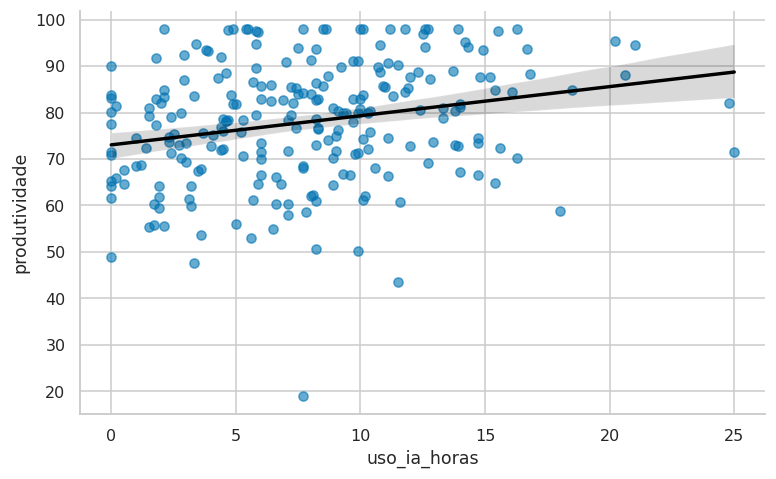

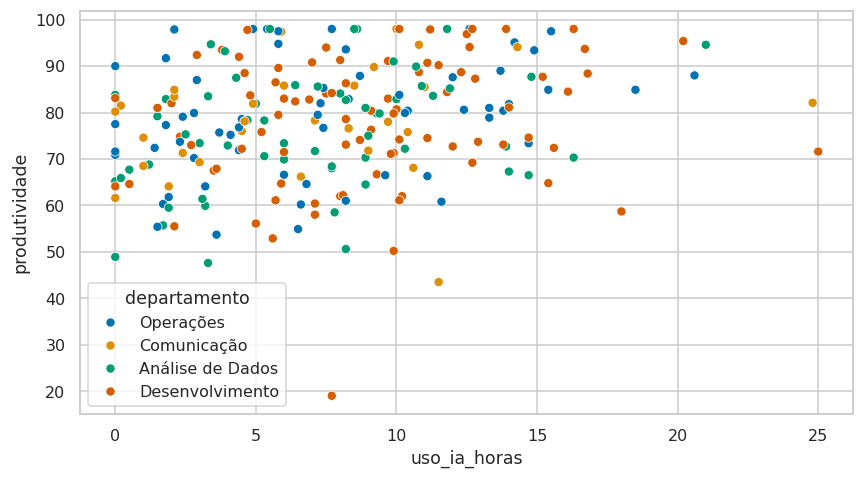

In [6]:
pares=dados.dropna(subset=['uso_ia_horas','produtividade']).copy()
x,y=pares.uso_ia_horas,pares.produtividade
pear=stats.pearsonr(x,y); spear=stats.spearmanr(x,y)
R['associacao']={'n':len(pares),'pearson':resultado(pear),'spearman':resultado(spear),'covariancia':x.cov(y)}
R['associacao']['ic_pearson']=list(pear.confidence_interval(.95))
# Permutação bilateral para a associação de postos; semente fixa, 9999 reamostragens.
rx,ry=stats.rankdata(x),stats.rankdata(y)
rx=(rx-rx.mean())/np.linalg.norm(rx-rx.mean()); ry=(ry-ry.mean())/np.linalg.norm(ry-ry.mean())
perm=np.array([rx@rng.permutation(ry) for _ in range(9999)])
R['associacao']['p_perm_spearman']=(1+int((abs(perm)>=abs(spear.statistic)).sum()))/10000
print(R['associacao'])
sns.lmplot(data=pares,x='uso_ia_horas',y='produtividade',height=4.5,aspect=1.6,ci=95,seed=SEED,
           scatter_kws={'alpha':.6},line_kws={'color':'black'})
figura('associacao_ia_produtividade')
fig,ax=plt.subplots(figsize=(8,4.5))
sns.scatterplot(data=pares,x='uso_ia_horas',y='produtividade',hue='departamento',ax=ax)
figura('associacao_departamentos')

## 3. Associação entre IA e produtividade

**3.1 — Representação.** O diagrama de dispersão sugere uma tendência crescente ligeira, com grande dispersão vertical. Cada ponto representa um par completo; a reta resume a tendência média. A banda gráfica de seaborn é obtida por bootstrap e não é um intervalo de previsão individual.

*Consultar a figura produzida na célula de análise correspondente.*

**3.2 — Quantificação e escolha.** Pearson avalia a associação linear entre duas medidas quantitativas: r = 0,240860, IC95% de Fisher [0,116751; 0,357563], p = 0,000187, n = 236. A covariância amostral é 15,201972 pontos×horas; depende das unidades e não serve de escala padronizada de intensidade. Como verificação de robustez, Spearman = 0,265867 (p = 0,0000351) indica associação monotónica também positiva. A permutação de Spearman, com 9 999 permutações e semente fixa, dá p = 0,0001. A inferência por permutação pressupõe permutabilidade sob a hipótese nula.

**3.3 — Intensidade.** A associação é fraca no sentido descritivo: r está próximo de 0,24 e r² = 0,058. Não usamos fronteiras universais entre fraco/moderado/forte; o essencial é que apenas 5,8% da variabilidade é explicada linearmente por IA isoladamente. Significância estatística não equivale a forte capacidade explicativa.

**3.4 — Necessidade versus tendência.** C014 tem 4,9 horas de IA e 98 pontos; C134 tem 25 horas e 71,6 pontos. Logo, mais utilização não implica necessariamente mais produtividade. Uma associação positiva admite muitos pares em sentido contrário.

**3.5 — Causalidade.** Não. Não houve atribuição aleatória de IA, observação antes/depois nem controlo de todos os fatores relevantes. Experiência, formação, tipo de tarefa e seleção de utilizadores podem gerar confundimento; produtividade pode também influenciar o uso. Estes dados transversais sintéticos sustentam descrições e associações condicionais, não efeitos causais.



## 5. Diferenças entre departamentos e intervalo de confiança

**Pergunta e abordagem:** As diferenças entre médias de departamentos podem refletir variação amostral. Formular H0 antes de ler o valor-p.

,departamento,n,media,sd,W,p_shapiro
0,Análise de Dados,58,76.474138,12.569604,0.977768,0.363537
1,Comunicação,31,78.596774,11.606650,0.961379,0.317196
2,Desenvolvimento,85,78.029412,13.972983,0.936566,0.000413
3,Operações,64,79.179688,12.197309,0.964576,0.063047


,A,B,diferenca_A_menos_B,t,gl,p_bruto,IC_simult_inf,IC_simult_sup,p_Holm
0,Análise de Dados,Comunicação,-2.122636,-0.798318,65.792560,0.427558,-9.355799,5.110526,1.0
1,Análise de Dados,Desenvolvimento,-1.555274,-0.694081,130.629677,0.488864,-7.558361,4.447813,1.0
2,Análise de Dados,Operações,-2.705550,-1.204115,118.027306,0.230954,-8.735056,3.323957,1.0
3,Comunicação,Desenvolvimento,0.567362,0.220136,63.736498,0.826469,-6.450960,7.585685,1.0
4,Comunicação,Operações,-0.582913,-0.225701,62.204170,0.822174,-7.621368,6.455541,1.0
5,Desenvolvimento,Operações,-1.150276,-0.535065,143.749523,0.593432,-6.901521,4.600969,1.0


{'welch': {'estatistica': 0.5033867178244167, 'p': 0.6807637442169532}, 'gl_welch': [3.0, np.float64(105.71698443314794)], 'classica': {'estatistica': 0.47207375205500596, 'p': 0.7020311140044999}, 'kruskal': {'estatistica': 1.367017880595776, 'p': 0.71328380321992}, 'levene': {'estatistica': 0.7510931473134905, 'p': 0.5226960056673154}, 'SQ_entre': np.float64(234.9501437828339), 'SQ_dentro': np.float64(38820.44094865414), 'eta2': np.float64(0.00601581848781772), 'omega2': np.float64(-0.006699111995868072)}
IC95 média: [np.float64(76.39434770182426), np.float64(79.67287918893204)]


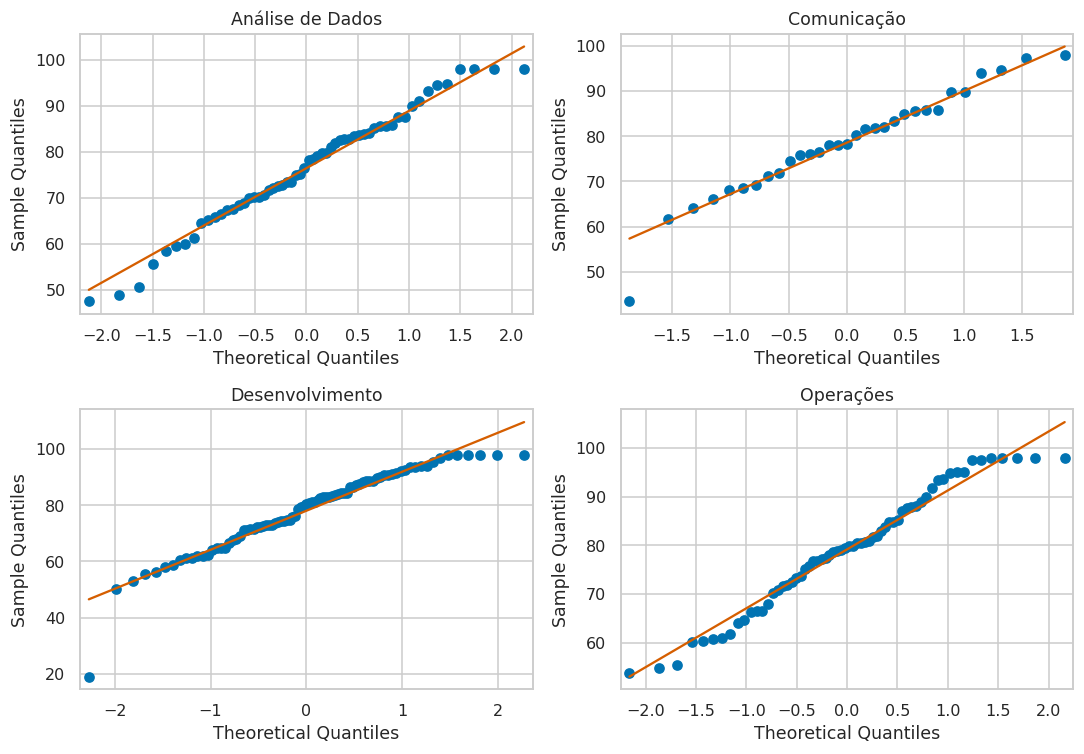

In [7]:
# Pergunta sobre médias: Welch é a análise principal, sem impor variâncias iguais.
# ANOVA clássica e Kruskal–Wallis são análises de sensibilidade, não seleção por menor p.
base_dep=dados.dropna(subset=['produtividade','departamento'])
nomes=sorted(base_dep.departamento.unique())
grupos=[base_dep.loc[base_dep.departamento.eq(n),'produtividade'].to_numpy() for n in nomes]
diag=pd.DataFrame([{'departamento':n,'n':len(g),'media':g.mean(),'sd':g.std(ddof=1),
                   'W':stats.shapiro(g).statistic,'p_shapiro':stats.shapiro(g).pvalue} for n,g in zip(nomes,grupos)])
display(guardar('diagnosticos_departamentos',diag))
welch=anova_oneway(grupos,use_var='unequal',welch_correction=True)
classica=stats.f_oneway(*grupos); kw=stats.kruskal(*grupos); lev=stats.levene(*grupos,center='median')
N=sum(map(len,grupos)); K=len(grupos); media=base_dep.produtividade.mean()
sq_entre=sum(len(g)*(g.mean()-media)**2 for g in grupos)
sq_dentro=sum(((g-g.mean())**2).sum() for g in grupos)
R['departamentos']={'welch':resultado(welch),'gl_welch':list(welch.df),'classica':resultado(classica),
 'kruskal':resultado(kw),'levene':resultado(lev),'SQ_entre':sq_entre,'SQ_dentro':sq_dentro,
 'eta2':sq_entre/(sq_entre+sq_dentro),
 'omega2':(sq_entre-(K-1)*sq_dentro/(N-K))/(sq_entre+sq_dentro+sq_dentro/(N-K))}
# Comparações Welch aos pares com Holm; IC simultâneos Bonferroni para os seis contrastes.
post=[]; ncontr=K*(K-1)//2
for i,j in itertools.combinations(range(K),2):
    a,b=grupos[i],grupos[j]; na,nb=len(a),len(b); va,vb=a.var(ddof=1),b.var(ddof=1)
    se=np.sqrt(va/na+vb/nb); df=(va/na+vb/nb)**2/((va/na)**2/(na-1)+(vb/nb)**2/(nb-1))
    delta=a.mean()-b.mean(); t=stats.ttest_ind(a,b,equal_var=False)
    margem=stats.t.ppf(1-ALPHA/(2*ncontr),df)*se
    post.append({'A':nomes[i],'B':nomes[j],'diferenca_A_menos_B':delta,'t':t.statistic,'gl':df,
                 'p_bruto':t.pvalue,'IC_simult_inf':delta-margem,'IC_simult_sup':delta+margem})
post=pd.DataFrame(post); post['p_Holm']=multipletests(post.p_bruto,method='holm')[1]
display(guardar('posthoc_welch_holm',post)); print(R['departamentos']); print('IC95 média:',R['ic_media'])
fig,axes=plt.subplots(2,2,figsize=(10,7))
for a,n,g in zip(axes.flat,nomes,grupos): sm.qqplot(g,line='s',ax=a); a.set_title(n)
figura('qq_departamentos')

## 4. Inferência entre departamentos e sobre a média

**4.1 — Diferenças descritivas.** As médias variam entre 76,474 e 79,180, uma amplitude de 2,706 pontos, inferior à dispersão dentro dos grupos (desvios-padrão entre aproximadamente 11,6 e 14,0). A diferença observada merece quantificação da incerteza, mas não basta para declarar departamentos diferentes.

**4.2 — Hipóteses.** H0: μ_Análise = μ_Comunicação = μ_Desenvolvimento = μ_Operações. H1: pelo menos uma média difere. A alternativa não diz que todas diferem, nem qual delas é maior.

**4.3 — Condições.** Confirmámos a unicidade dos IDs após limpeza, tamanhos dos grupos, faltas, boxplots e QQ por departamento. Independência é uma hipótese do desenho, não um resultado de Shapiro. Levene centrado na mediana: estatística 0,751, p = 0,523; não demonstra igualdade de variâncias. A normalidade não é estrita e há valores extremos. Escolhemos Welch como principal porque não exige variâncias comuns e admite tamanhos desiguais. A ANOVA clássica e Kruskal–Wallis são verificações complementares; Kruskal não testa diretamente igualdade de médias nem, sem condições adicionais, apenas medianas.

**4.4 — Resultado.** Welch: F(3; 105,717) = 0,503387, p = 0,680764. Sob H0 e os pressupostos do procedimento, um resultado tão ou mais extremo não é raro; não rejeitamos H0 a 5%. ANOVA clássica: F(3; 234) = 0,472074, p = 0,702031. Kruskal–Wallis: H = 1,367018, p = 0,713284. A concordância não elimina as limitações do desenho. Na decomposição clássica, SQ_entre = 234,950 e SQ_dentro = 38 820,441; η² = 0,00602. A estimativa de ω² é ligeiramente negativa (−0,00670), interpretável como aproximadamente zero, não como variância explicada negativa.

**4.5 — Alcance.** Não identificamos diferenças estatisticamente sustentadas. As comparações de Welch entre pares com Holm são exploratórias e não justificam um ranking inferencial; os intervalos simultâneos de Bonferroni constam do CSV. Não rejeitar igualdade não prova equivalência. Para equivalência seriam necessários margens substantivas pré-definidas e um procedimento próprio. A média mais elevada em Operações é apenas descritiva.

**4.6 — IC da média.** Com n = 238, usamos média ± t_(0,975;237)×s/√n: 78,0336 ± aproximadamente 1,6393, resultando em **[76,3943; 79,6729]**. Em repetições sob o modelo de amostragem, 95% dos intervalos construídos assim cobririam a média populacional. Não significa que 95% dos colaboradores tenham produtividade neste intervalo nem que se tenha estimado uma empresa real. O bootstrap percentil de 5 000 amostras dá [76,4100; 79,6543], uma sensibilidade próxima, não uma prova de validade externa.



## 6. Regressão simples e contas explícitas

**Pergunta e abordagem:** O modelo simples descreve a associação marginal. Distinguir resposta média, previsão individual e efeito causal.

In [8]:
# Adaptação Aula_4_Colab_Separado: smf.ols, SXX/SXY, intervalos e resíduos.
simples=smf.ols('produtividade ~ uso_ia_horas',data=pares).fit()
sxx=((x-x.mean())**2).sum(); sxy=((x-x.mean())*(y-y.mean())).sum()
b1=sxy/sxx; b0=y.mean()-b1*x.mean()
assert np.allclose([b0,b1],simples.params)
R['contas_simples']={'x_media':x.mean(),'y_media':y.mean(),'SXX':sxx,'SXY':sxy,'b0':b0,'b1':b1,
 'SQT':simples.centered_tss,'SQR_explicada':simples.ess,'SQE_residual':simples.ssr,
 'QME':simples.mse_resid,'diferenca_10_menos_5':5*b1,'IC_diferenca':list(5*simples.conf_int().loc['uso_ia_horas'])}
pred=simples.get_prediction(pd.DataFrame({'uso_ia_horas':[5,7,10]})).summary_frame()
pred.index=[5,7,10]; display(guardar('previsoes_simples',pred))
ex=pares.iloc[[0]]; R['exemplo_residuo']={'id':ex.id_colaborador.iloc[0],'observado':ex.produtividade.iloc[0],
 'estimado':float(simples.predict(ex).iloc[0]),'residuo':float(ex.produtividade.iloc[0]-simples.predict(ex).iloc[0])}
print(R['contas_simples']); print(R['exemplo_residuo'])

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
5,76.176095,0.931701,74.340502,78.011689,51.539870,100.812321
7,77.430662,0.821580,75.812022,79.049302,52.809651,102.051674
10,79.312512,0.891598,77.555927,81.069097,54.682047,103.942977


{'x_media': np.float64(7.767796610169492), 'y_media': np.float64(77.91228813559323), 'SXX': np.float64(5695.135254237288), 'SXY': np.float64(3572.4633898305083), 'b0': np.float64(73.03967883472836), 'b1': np.float64(0.6272833269714759), 'SQT': np.float64(38627.95436440678), 'SQR_explicada': np.float64(2240.946720656677), 'SQE_residual': np.float64(36387.007643750105), 'QME': np.float64(155.50003266559875), 'diferenca_10_menos_5': np.float64(3.1364166348573796), 'IC_diferenca': [1.5086830613636983, 4.764150208351056]}
{'id': 'C001', 'observado': np.float64(68.0), 'estimado': 77.8697604524087, 'residuo': -9.869760452408698}


## 5. Regressão linear simples

**5.1 — Modelo.** Ajustámos produtividade = β0 + β1×uso_ia_horas + ε por mínimos quadrados em 236 pares completos. Minimiza-se a soma dos resíduos ao quadrado, não a soma dos resíduos em valor absoluto.

**5.2 — Equação e contas.** A previsão é **ŷ = 73,039679 + 0,627283×IA**. Cada hora adicional está associada, em média, a mais 0,627 pontos no modelo marginal. O intercepto é a previsão quando IA = 0, não produtividade intrínseca nem efeito da ausência de IA. As contas são Sxx = 5 695,135254; Sxy = 3 572,463390; b1 = Sxy/Sxx; b0 = ȳ − b1×x̄, com x̄ = 7,767797 e ȳ = 77,912288. Estas médias diferem das univariadas porque a amostra é a de pares completos.

**5.3 — Cinco versus dez horas.** ŷ(5) = 76,1761; ŷ(10) = 79,3125; diferença = 5×0,627283 = **3,1364 pontos**, IC clássico95% [1,5087; 4,7642]. É uma diferença entre médias estimadas no modelo marginal, dentro do intervalo observado, sem controlar outros fatores. Não é o ganho causal de aumentar as horas de uma pessoa. Intervalos da resposta média e de previsão individual, distintos, estão em previsoes_simples.csv.

**5.4 — Variabilidade explicada.** SQT = 38 627,9544; SQR = 2 240,9467; SQE = 36 387,0076. R² = SQR/SQT = 1 − SQE/SQT = **0,058014**; R² ajustado = 0,053988. Restam cerca de 94,2% da variabilidade não explicados pelo modelo. Isto não atribui percentagens causais à IA.

**5.5 — Resíduo concreto.** C001 apresenta produtividade 68; o modelo prevê 77,8698. O resíduo e = y − ŷ = **−9,8698 pontos**: a produtividade observada fica quase dez pontos abaixo da ajustada. Um resíduo não é um erro de registo demonstrado.

**5.6 — Diagnósticos.** Shapiro nos resíduos: W = 0,971951, p = 0,000128, evidência contra normalidade estrita. Breusch–Pagan: p = 0,976; RESET: p = 0,387; não detetamos heteroscedasticidade ou curvatura por estes testes, mas eles não provam adequação. Os gráficos mostram dispersão elevada e uma cauda negativa influente. O R² reduzido e a omissão de fatores relevantes limitam explicação e previsão. Durbin–Watson ≈ 1,836 é apenas descritivo: a ordem dos IDs não é tempo. Erros robustos e bootstrap não corrigem fatores omitidos.



## 7. Regressão múltipla: seleção substantiva e amostra comum

**Pergunta e abordagem:** Experiência, formação e contexto profissional podem atenuar a associação da IA. Comparar os modelos nos mesmos casos.

In [9]:
# Excluir ID e indicadores contemporâneos de desempenho do modelo principal.
# Complexidade é ordinal: tendência linear por nível no principal, categórica na sensibilidade.
preditores=['uso_ia_horas','experiencia_anos','formacao_ia_horas','complexidade_tarefas','carga_trabalho_horas','departamento']
comum=dados.dropna(subset=['produtividade']+preditores).copy()
formula='produtividade ~ uso_ia_horas + experiencia_anos + formacao_ia_horas + complexidade_tarefas + carga_trabalho_horas + C(departamento)'
multiplo=smf.ols(formula,data=comum).fit()
simples_comum=smf.ols('produtividade ~ uso_ia_horas',data=comum).fit()
parcimonioso=smf.ols('produtividade ~ uso_ia_horas + experiencia_anos + formacao_ia_horas + complexidade_tarefas',data=comum).fit()
modelos={'simples':simples,'simples_comum':simples_comum,'multiplo':multiplo,'parcimonioso':parcimonioso}
comparacao=[]
for nome,m in modelos.items():
    robust=m.get_robustcov_results(cov_type='HC3',use_t=True)
    tab=pd.DataFrame({'b':m.params,'SE_classico':m.bse,'t_classico':m.tvalues,'p_classico':m.pvalues,
                      'IC_inf':m.conf_int()[0],'IC_sup':m.conf_int()[1],
                      'SE_HC3':robust.bse,'p_HC3':robust.pvalues,'IC_HC3_inf':robust.conf_int()[:,0],'IC_HC3_sup':robust.conf_int()[:,1]})
    guardar('coeficientes_'+nome,tab)
    comparacao.append({'modelo':nome,'n':m.nobs,'p_sem_intercepto':m.df_model,'R2':m.rsquared,'R2_aj':m.rsquared_adj,
                       'RMSE_ajuste':np.sqrt(np.mean(m.resid**2)),'AIC':m.aic,'BIC':m.bic,'F':m.fvalue,'p_F':m.f_pvalue})
    R[nome]={'coeficientes':tab.to_dict('index'),'n':int(m.nobs),'R2':m.rsquared,'R2_aj':m.rsquared_adj}
display(guardar('comparacao_modelos',pd.DataFrame(comparacao)))
R['F_parcial']=list(multiplo.compare_f_test(simples_comum))
R['teste_adicional_HC3']={'F':float(multiplo.get_robustcov_results(cov_type='HC3',use_t=True).f_test(np.eye(len(multiplo.params))[ [i for i,n in enumerate(multiplo.params.index) if n not in ['Intercept','uso_ia_horas']] ]).fvalue)}
print('F parcial clássico (F,p,gl adicionais):',R['F_parcial'])
display(pd.DataFrame({'variavel':multiplo.model.exog_names,'coeficiente':multiplo.params.to_numpy()}))

,modelo,n,p_sem_intercepto,R2,R2_aj,RMSE_ajuste,AIC,BIC,F,p_F
0,simples,236.0,1.0,0.058014,0.053988,12.417014,1862.738907,1869.666571,14.411230,1.872212e-04
1,simples_comum,233.0,1.0,0.060526,0.056459,12.428259,1839.532689,1846.434766,14.882211,1.484758e-04
2,multiplo,233.0,8.0,0.299219,0.274191,10.733933,1785.234449,1816.293795,11.955443,3.572354e-14
3,parcimonioso,233.0,4.0,0.279794,0.267159,10.881684,1783.605124,1800.860316,22.144057,1.850105e-15


F parcial clássico (F,p,gl adicionais): [np.float64(10.89955251073712), np.float64(7.96393167657726e-12), np.float64(7.0)]


,variavel,coeficiente
0,Intercept,50.906340
1,C(departamento)[T.Comunicação],2.440678
2,C(departamento)[T.Desenvolvimento],1.412579
3,C(departamento)[T.Operações],1.748344
4,uso_ia_horas,0.143558
5,experiencia_anos,1.609552
6,formacao_ia_horas,0.214993
7,complexidade_tarefas,-0.973965
8,carga_trabalho_horas,0.380856


## 8. Diagnósticos, influência e sensibilidade

**Pergunta e abordagem:** Procurar padrões, influência e incerteza; não apagar observações para obter significância.

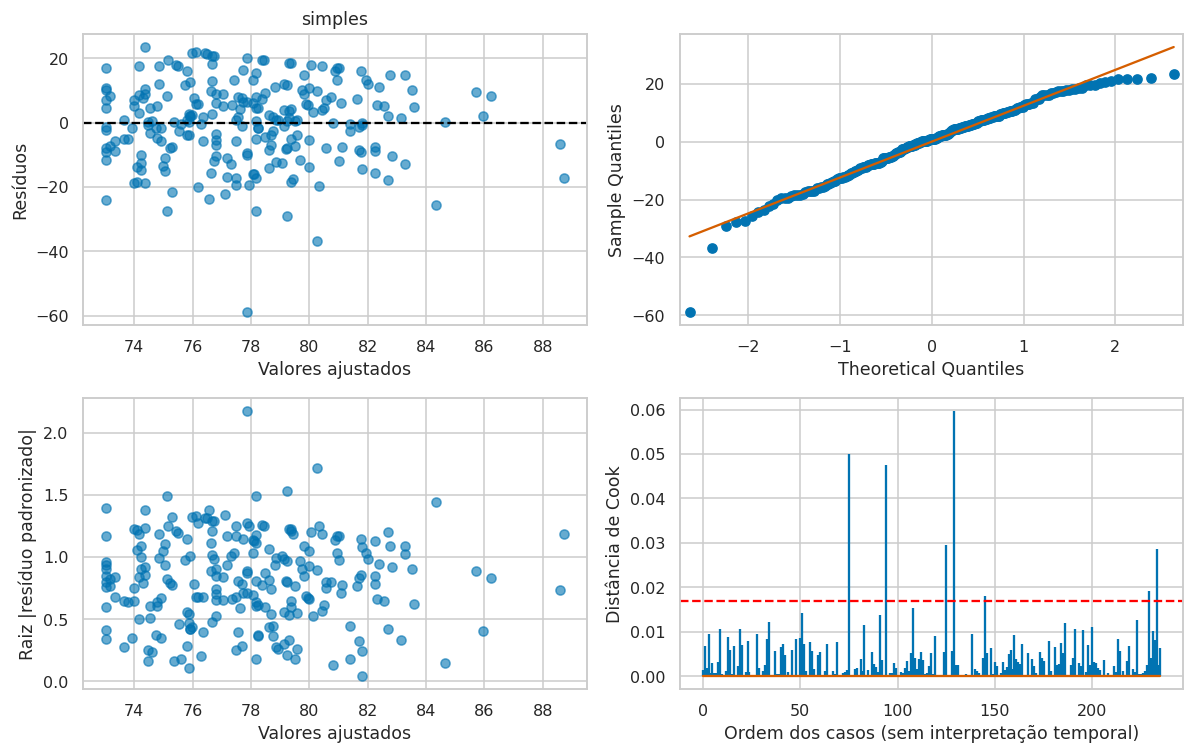

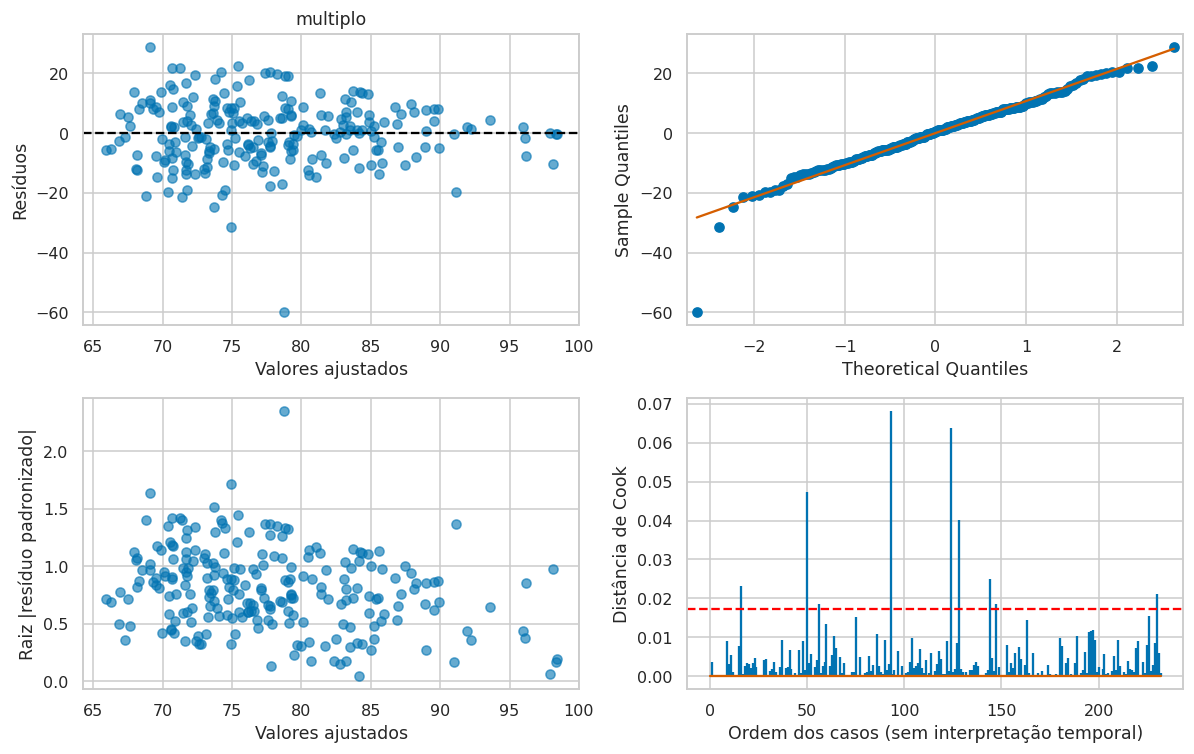

,modelo,Shapiro_W,p_Shapiro,BP_LM,p_BP,RESET_F,p_RESET,Durbin_Watson_descritivo
0,simples,0.971951,0.000128,0.000889,0.976213,0.752655,0.386529,1.836383
1,simples_comum,0.972580,0.000175,0.000495,0.982249,0.706997,0.401316,1.855464
2,multiplo,0.965771,0.000022,7.847342,0.448523,0.173980,0.677000,1.950647
3,parcimonioso,0.965677,0.000021,6.191682,0.185283,0.000040,0.994965,1.954277


,variavel,VIF
1,C(departamento)[T.Comunicação],1.356689
2,C(departamento)[T.Desenvolvimento],1.746438
3,C(departamento)[T.Operações],1.553247
4,uso_ia_horas,1.671264
5,experiencia_anos,1.143454
6,formacao_ia_horas,1.528121
7,complexidade_tarefas,1.043554
8,carga_trabalho_horas,1.049301


,analise,n,b_IA,IC_HC3_inf,IC_HC3_sup,p_HC3,R2_aj
0,complexidade_categorica,233.0,0.129587,-0.250126,0.509301,0.501922,0.278028
1,sem_Cook_sinalizados,224.0,0.081408,-0.214136,0.376952,0.587738,0.375625
2,sem_maior_uso_IA,232.0,0.172639,-0.196615,0.541894,0.357863,0.284773


,id_colaborador,uso_ia_horas,experiencia_anos,formacao_ia_horas,complexidade_tarefas,carga_trabalho_horas,departamento
0,C001,7.7,0.5,7.7,3.0,43.7,Operações
1,C002,1.7,3.5,1.4,2.0,34.6,Operações


,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,69.941795,1.866455,66.263738,73.619852,48.057342,91.826248
1,70.062826,2.133414,65.858697,74.266954,48.083838,92.041813


In [10]:
diagnosticos=[]
for nome,m in modelos.items():
    bp=het_breuschpagan(m.resid,m.model.exog)
    sh=stats.shapiro(m.resid); reset=linear_reset(m,power=2,use_f=True)
    diagnosticos.append({'modelo':nome,'Shapiro_W':sh.statistic,'p_Shapiro':sh.pvalue,'BP_LM':bp[0],'p_BP':bp[1],
                         'RESET_F':float(reset.fvalue),'p_RESET':float(reset.pvalue),
                         'Durbin_Watson_descritivo':sm.stats.durbin_watson(m.resid)})
    if nome in ['simples','multiplo']:
        infl=m.get_influence(); ids=pares.id_colaborador if nome=='simples' else comum.id_colaborador
        inf=pd.DataFrame({'id':ids.to_numpy(),'ajustado':m.fittedvalues.to_numpy(),'residuo':m.resid.to_numpy(),
                          'residuo_studentizado':infl.resid_studentized_external,'leverage':infl.hat_matrix_diag,
                          'Cook':infl.cooks_distance[0]})
        inf['sinal_Cook']=inf.Cook>4/m.nobs
        guardar('influencia_'+nome,inf)
        fig,ax=plt.subplots(2,2,figsize=(11,7))
        ax[0,0].scatter(m.fittedvalues,m.resid,alpha=.6); ax[0,0].axhline(0,color='black',ls='--')
        ax[0,0].set(xlabel='Valores ajustados',ylabel='Resíduos',title=nome)
        sm.qqplot(m.resid,line='s',ax=ax[0,1])
        ax[1,0].scatter(m.fittedvalues,np.sqrt(abs(infl.resid_studentized_internal)),alpha=.6)
        ax[1,0].set(xlabel='Valores ajustados',ylabel='Raiz |resíduo padronizado|')
        ax[1,1].stem(np.arange(len(inf)),inf.Cook,markerfmt=' '); ax[1,1].axhline(4/m.nobs,ls='--',color='red')
        ax[1,1].set(xlabel='Ordem dos casos (sem interpretação temporal)',ylabel='Distância de Cook')
        figura('diagnosticos_'+nome)
display(guardar('diagnosticos_modelos',pd.DataFrame(diagnosticos)))
R['diagnosticos']=diagnosticos
vif=pd.DataFrame({'variavel':multiplo.model.exog_names,
                 'VIF':[variance_inflation_factor(multiplo.model.exog,i) for i in range(multiplo.model.exog.shape[1])]})
display(guardar('vif',vif.loc[vif.variavel.ne('Intercept')]))
sens=[]
alt_formula=formula.replace('complexidade_tarefas','C(complexidade_tarefas)')
for nome,base,f in [('complexidade_categorica',comum,alt_formula),
                     ('sem_Cook_sinalizados',comum.loc[multiplo.get_influence().cooks_distance[0]<=4/multiplo.nobs],formula),
                     ('sem_maior_uso_IA',comum.loc[comum.uso_ia_horas<comum.uso_ia_horas.max()],formula)]:
    m=smf.ols(f,data=base).fit(); h=m.get_robustcov_results(cov_type='HC3',use_t=True); j=m.params.index.get_loc('uso_ia_horas')
    sens.append({'analise':nome,'n':m.nobs,'b_IA':m.params['uso_ia_horas'],'IC_HC3_inf':h.conf_int()[j,0],
                 'IC_HC3_sup':h.conf_int()[j,1],'p_HC3':h.pvalues[j],'R2_aj':m.rsquared_adj})
display(guardar('sensibilidade',pd.DataFrame(sens)))
R['sensibilidade']=sens
novos=comum.iloc[[0,1]].copy()
display(guardar('perfis_previsao_multipla',novos[['id_colaborador']+preditores]))
display(guardar('previsoes_multiplas',multiplo.get_prediction(novos).summary_frame()))

## 9. Validação cruzada complementar: previsão fora do ajuste

**Pergunta e abordagem:** Uma melhoria de ajuste pode não se manter em dados não usados para estimar. Usar partições iguais para comparar.

In [11]:
# Não confundir R² de ajuste com desempenho em casos novos. Mesmas divisões nos dois modelos.
from sklearn.model_selection import KFold
cv=KFold(n_splits=5,shuffle=True,random_state=SEED)
cv_linhas=[]
for fold,(it,iv) in enumerate(cv.split(comum),1):
    tr,te=comum.iloc[it],comum.iloc[iv]
    for nome,f in [('simples','produtividade ~ uso_ia_horas'),('multiplo',formula)]:
        m=smf.ols(f,data=tr).fit(); erro=te.produtividade-m.predict(te)
        cv_linhas.append({'fold':fold,'modelo':nome,'n_teste':len(te),'RMSE':np.sqrt(np.mean(erro**2)),
                          'MAE':np.mean(abs(erro))})
display(guardar('validacao_cruzada',pd.DataFrame(cv_linhas)))
R['cv']=pd.DataFrame(cv_linhas).groupby('modelo')[['RMSE','MAE']].mean().to_dict('index')

,fold,modelo,n_teste,RMSE,MAE
0,1,simples,47,11.249014,8.743832
1,1,multiplo,47,10.908056,9.047600
2,2,simples,47,16.639994,12.928836
3,2,multiplo,47,15.843098,11.753451
4,3,simples,47,10.786670,8.556547
5,3,multiplo,47,9.592956,7.299363
6,4,simples,46,10.711483,8.732813
7,4,multiplo,46,7.368467,5.886774
8,5,simples,46,12.265163,10.494615
9,5,multiplo,46,10.496986,9.082323


## 6. Regressão múltipla

**6.1 — Seleção.** Experiência, formação em IA, complexidade, carga de trabalho e departamento são candidatos substantivos. Evitamos incluir qualidade, tarefas concluídas e tempo médio por tarefa no modelo explicativo principal: são indicadores contemporâneos de desempenho e podem introduzir circularidade, sobreajustamento ou ambiguidade temporal. O dicionário não autoriza reconstruir a produtividade a partir deles. As associações com esses indicadores são apenas exercícios exploratórios.

**6.2 — Construção.** O modelo usa IA, experiência, formação, complexidade, carga e três indicadores de departamento, com Análise de Dados como referência. São oito coeficientes explicativos mais intercepto, em 233 casos completos. A escolha é substantiva, não uma seleção automática pelo menor valor-p. A alternativa parcimoniosa retém IA, experiência, formação e complexidade; a alternativa com complexidade categórica verifica a suposição de intervalos iguais.

**6.3 — Equação.**

ŷ = 50,906340 + 0,143558×IA + 1,609552×experiência + 0,214993×formação − 0,973965×complexidade + 0,380856×carga + 2,440678×I(Comunicação) + 1,412579×I(Desenvolvimento) + 1,748344×I(Operações).

I(categoria) vale 1 quando o colaborador pertence a essa categoria e 0 caso contrário. Mantendo os restantes termos constantes, uma hora adicional de IA associa-se a **0,1436 pontos**, IC95% HC3 [−0,2299; 0,5171], p = 0,4496. O intervalo admite associações pequenas negativas, nulas e positivas; não prova efeito zero. A diferença condicional entre 5 e 10 horas é 0,7178 pontos, com IC robusto [−1,1497; 2,5853]. Não confundir esta comparação com a marginal de 3,1364.

**6.4 — Alteração do coeficiente.** Para eliminar a mudança de amostra como explicação, reajustámos o simples nos mesmos 233 casos: b_IA = 0,639091. No múltiplo é 0,143558, uma redução de aproximadamente 77,5%. O valor simples original era 0,627283. A atenuação é compatível com associação partilhada com as covariáveis, especialmente experiência; não identifica um mecanismo causal nem demonstra que uma única variável explique toda a redução.

**6.5 — Comparação justa.**

| Modelo nos mesmos 233 casos | Parâmetros explicativos | R² | R² ajustado | AIC | BIC |
|---|---:|---:|---:|---:|---:|
| Simples | 1 | 0,0605 | 0,0565 | 1839,533 | 1846,435 |
| Múltiplo principal | 8 | 0,2992 | 0,2742 | 1785,234 | 1816,294 |
| Parcimonioso | 4 | 0,2798 | 0,2672 | 1783,605 | 1800,860 |

O teste F parcial de acrescentar os sete termos ao simples dá F = 10,8996, p = 7,96×10⁻¹². O múltiplo melhora substancialmente o ajustamento em relação ao simples, mesmo penalizando complexidade. Porém, AIC e BIC favorecem o parcimonioso relativamente ao principal, pelo que não alegamos que adicionar sempre variáveis é melhor. Na validação cruzada de cinco partições comuns, o RMSE médio é 10,842 no múltiplo e 12,330 no simples; MAE 8,614 versus 9,891. É evidência preditiva interna complementar, não validação numa população externa. A variabilidade entre partições está no CSV.

**6.6 — Diagnóstico e robustez.** O maior VIF é 1,746 (indicador de Desenvolvimento); o da IA é 1,671: não há indicação de colinearidade grave por este diagnóstico. Shapiro dos resíduos do múltiplo dá p = 0,0000216; Breusch–Pagan p = 0,449; RESET p = 0,677. Usamos IC/p robustos HC3 para a interpretação principal dos coeficientes, mas reconhecemos a cauda negativa e os limites da resposta. Nenhuma previsão ajustada desta amostra saiu de [0;100], o que não garante limites para novos perfis. O bootstrap de 3 000 reamostragens de linhas dá IC de IA [−0,2305;0,4840].

Tratando complexidade como categórica, b_IA = 0,1296 (p HC3 = 0,502). Excluindo apenas em sensibilidade os nove casos com Cook > 4/n, b_IA = 0,0814 (n = 224; p = 0,588). Excluindo apenas C134, b_IA = 0,1726 (n = 232; p = 0,358). Os resultados não fornecem evidência clara de associação ajustada em nenhuma destas variantes. O principal mantém todos os casos completos; as exclusões não são uma limpeza oportunista.

*Consultar a figura produzida na célula de análise correspondente.*

**6.7 — Modelo escolhido.** Entre simples e múltiplo, o múltiplo responde melhor à questão de como a associação muda perante fatores individuais e profissionais. O simples continua útil para descrever a associação marginal. O parcimonioso oferece quase a mesma explicação com menos parâmetros e melhores AIC/BIC; é uma alternativa relevante se o objetivo privilegiar simplicidade. A escolha do principal preserva o ajuste substantivo por carga e departamento e não equivale a considerá-lo um modelo causal ou definitivamente verdadeiro.



## 10. Síntese de resultados principais e ficheiro de continuidade

**Pergunta e abordagem:** Interpretar estimativas, intervalos, diagnósticos e limites em conjunto.

In [12]:
def converter(v):
    if isinstance(v,np.generic): return v.item()
    if isinstance(v,np.ndarray): return v.tolist()
    raise TypeError(type(v).__name__)
(OUT/'resultados.json').write_text(json.dumps(R,ensure_ascii=False,indent=2,default=converter),encoding='utf-8')
assert hashlib.sha256(FICHEIRO.read_bytes()).hexdigest()==R['ficheiro_sha256']
assert np.isclose(simples.centered_tss,simples.ess+simples.ssr)
assert int(multiplo.nobs)==int(simples_comum.nobs)
print('Análise principal concluída. Resultados guardados em',OUT)

Análise principal concluída. Resultados guardados em /content/resultados


## 7. Conclusão e recomendação

**7.1 — Afirmação inicial.** Há uma tendência média positiva fraca na análise marginal; a afirmação é excessiva se significar que cada colaborador que usa mais IA é mais produtivo, que a associação é forte ou que a IA causa o aumento.

**7.2 — Após ajuste.** A estimativa positiva diminui muito e a incerteza passa a incluir zero. Os dados não fornecem evidência estatística clara de associação linear independente de IA com produtividade no modelo adotado. A ausência dessa evidência não demonstra ausência de qualquer benefício em qualquer tarefa ou população.

**7.3 — Resultado saliente.** O contraste mais marcante é a passagem de b_IA = 0,639 para 0,144 nos mesmos casos, enquanto o R² aumenta de 6,1% para 29,9%. O melhor ajustamento decorre da informação conjunta dos fatores e não de um reforço da contribuição independente da IA. Chamamos-lhe saliente, sem inventar uma surpresa pessoal ou uma previsão anterior não documentada.

**7.4 — Limitações.** Primeiro, os dados são sintéticos e transversais, sem desenho causal ou representatividade demonstrada. Segundo, há possíveis fatores omitidos, faltas de mecanismo desconhecido, resposta limitada e resíduos não normais; as análises de sensibilidade não eliminam estas limitações. A inferência e a validação interna não garantem desempenho numa empresa real.

**7.5 — Decisão.** Não recomendaríamos obrigatoriedade universal com base nestes resultados. Seria adequado estudar um piloto com atribuição aleatória ou desenho longitudinal controlado, critérios de produtividade e qualidade definidos previamente, medição de custos e efeitos por tarefa, acompanhamento de formação e avaliação de impactos adversos. Uma política deve apoiar-se em evidência causal e em benefício prático, não apenas num valor-p de correlação.

## Complemento pedagógico e reprodutibilidade

Os exercícios adicionais dos materiais são tratados no catálogo de perguntas e no notebook: distribuições de frequências e classes, correlações alternativas, testes de médias e proporções, qui-quadrado, regressões e classificação multinomial. São exercícios exploratórios; não alteram retrospetivamente a questão principal. Limiares como produtividade ≥80, média de referência 70 e formação ≥10 horas são escolhas didáticas, não normas empresariais fornecidas.

A classificação multinomial distingue produtividade <70, [70;85[ e ≥85. Apesar de um teste LR significativo no treino (p = 2,47×10⁻¹⁷), a accuracy no teste é 42,25%, abaixo dos 45,07% da previsão constante da classe mais frequente. A balanced accuracy é 40,21% e AUC macro 0,625. Este contraste demonstra por que significância global não basta para afirmar utilidade preditiva. O objetivo principal conserva produtividade contínua; a discretização perde informação.

O código adapta pandas, scipy e statsmodels dos guiões e notebooks da docente. Registámos mudanças de cabeçalho, variáveis, referência dos departamentos, casos completos, intervalos robustos, multiplicidade e separação treino/teste em METODOLOGIA.md. As contas de OLS e Welch foram verificadas por implementação independente, além de identidades R² = r² e F = t² no modelo simples. As validações confirmam que nenhum valor numérico foi alterado. O SHA-256 da fonte e as versões das bibliotecas constam dos resultados. Os autores devem executar e compreender o notebook e rever as interpretações antes da defesa oral; o texto não substitui esse domínio.


## 11. Perguntas alternativas de associação e regressão (Aulas 1–4)

**Pergunta e abordagem:** Exercícios exploratórios das Aulas1–4: as analogias de variáveis não são equivalências substantivas.

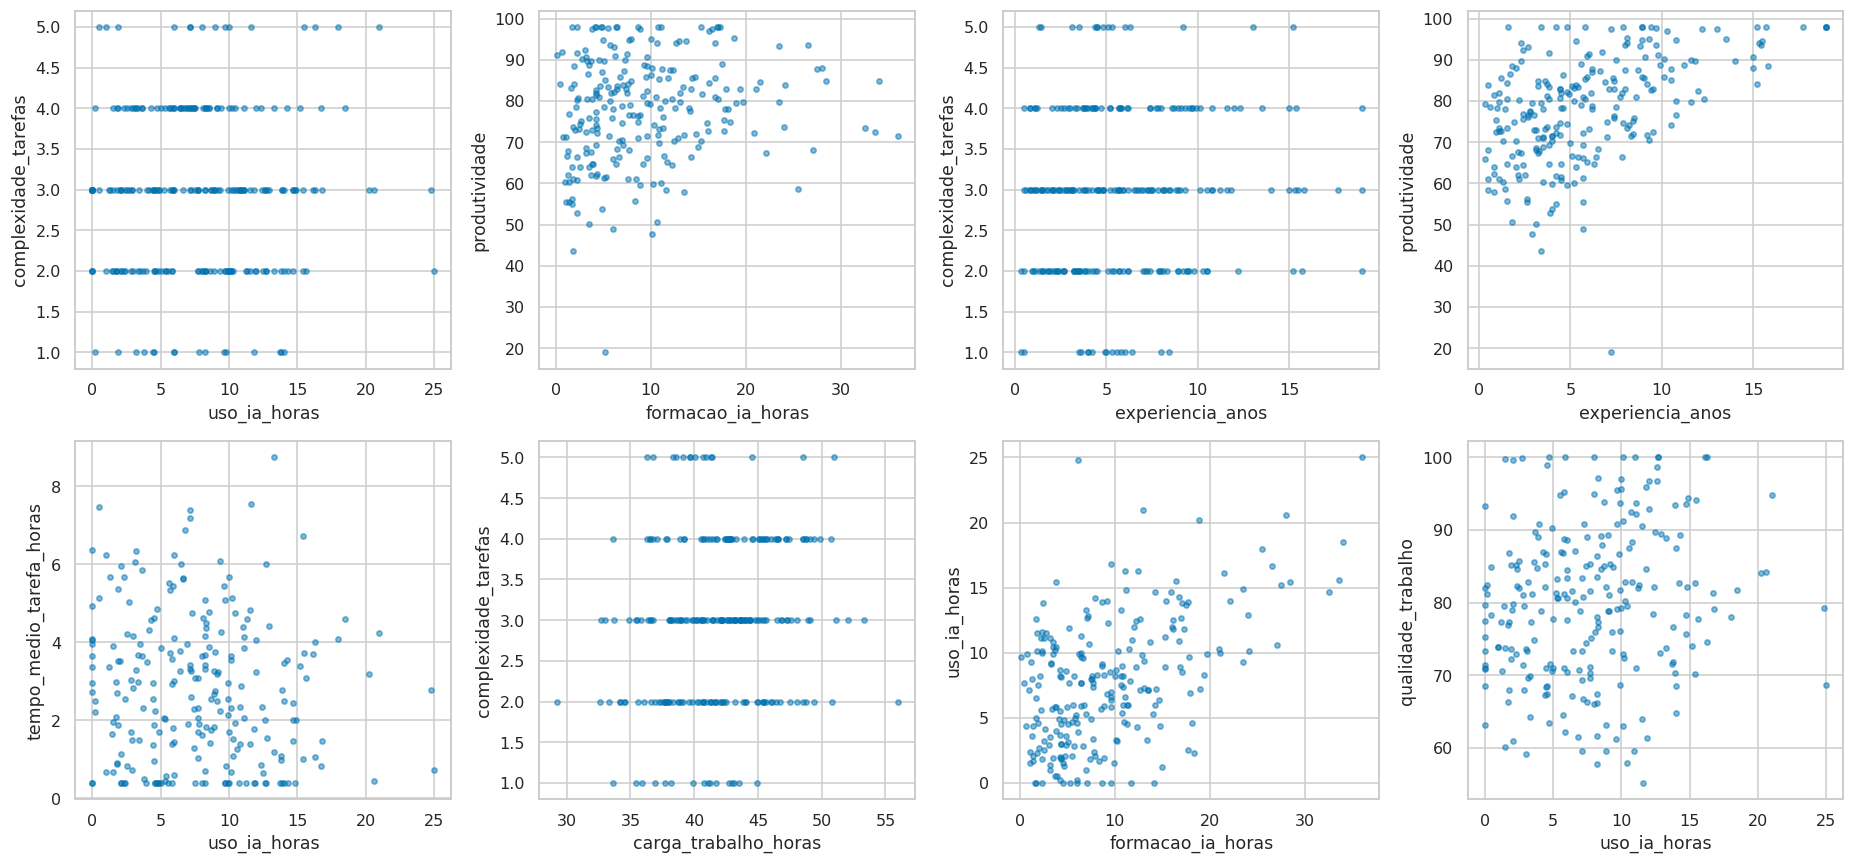

,X,Y,n,r,p_r,rho,p_rho,b0,b1,IC_b1_inf,IC_b1_sup,p_b1_HC3,R2,p_Shapiro,p_BP,p_rho_Holm
0,uso_ia_horas,complexidade_tarefas,237,0.033516,6.076807e-01,0.011456,8.607316e-01,2.896222,0.006887,-0.019580,0.033355,6.086787e-01,0.001123,2.031181e-09,0.575308,8.607316e-01
1,formacao_ia_horas,produtividade,237,0.146546,2.405064e-02,0.165217,1.084749e-02,75.452182,0.267906,0.050710,0.485102,1.584519e-02,0.021476,2.126049e-04,0.054228,4.338997e-02
2,experiencia_anos,complexidade_tarefas,238,0.093219,1.516693e-01,0.089301,1.697026e-01,2.814985,0.023722,-0.005847,0.053292,1.153264e-01,0.008690,2.933181e-07,0.414718,4.219763e-01
3,experiencia_anos,produtividade,237,0.498928,2.541169e-16,0.506978,7.001170e-17,68.628045,1.604953,1.345876,1.864029,7.354150e-27,0.248929,2.014408e-05,0.144718,5.600936e-16
4,uso_ia_horas,tempo_medio_tarefa_horas,237,-0.097470,1.346110e-01,-0.095990,1.406588e-01,3.079498,-0.036631,-0.083913,0.010651,1.282787e-01,0.009500,2.322227e-06,0.604513,4.219763e-01
5,carga_trabalho_horas,complexidade_tarefas,239,0.160766,1.282591e-02,0.171405,7.915728e-03,1.375763,0.037657,0.008752,0.066563,1.088769e-02,0.025846,1.279954e-04,0.252379,3.957864e-02
6,formacao_ia_horas,uso_ia_horas,237,0.512912,2.647977e-17,0.414560,2.931805e-11,4.364848,0.360097,0.284977,0.435217,3.742552e-18,0.263078,5.065704e-03,0.815269,2.052264e-10
7,uso_ia_horas,qualidade_trabalho,238,0.158950,1.409304e-02,0.182212,4.804184e-03,77.266990,0.342655,0.082491,0.602818,1.005939e-02,0.025265,1.415291e-01,0.148986,2.882511e-02


In [13]:
# Mapeamento: sono→produtividade; estudo→formação IA; café/telemóvel→uso IA;
# stress→complexidade; exercício→experiência. É analogia didática, não equivalência conceptual.
relacoes=[('uso_ia_horas','complexidade_tarefas'),('formacao_ia_horas','produtividade'),
          ('experiencia_anos','complexidade_tarefas'),('experiencia_anos','produtividade'),
          ('uso_ia_horas','tempo_medio_tarefa_horas'),('carga_trabalho_horas','complexidade_tarefas'),
          ('formacao_ia_horas','uso_ia_horas'),('uso_ia_horas','qualidade_trabalho')]
alt=[]
fig,axes=plt.subplots(2,4,figsize=(17,8))
for a,(vx,vy) in zip(axes.flat,relacoes):
    b=dados.dropna(subset=[vx,vy]); r=stats.pearsonr(b[vx],b[vy]); s=stats.spearmanr(b[vx],b[vy])
    m=smf.ols(f'{vy} ~ {vx}',data=b).fit(); h=m.get_robustcov_results(cov_type='HC3',use_t=True)
    alt.append({'X':vx,'Y':vy,'n':len(b),'r':r.statistic,'p_r':r.pvalue,'rho':s.statistic,'p_rho':s.pvalue,
      'b0':m.params.iloc[0],'b1':m.params.iloc[1],'IC_b1_inf':h.conf_int()[1,0],'IC_b1_sup':h.conf_int()[1,1],
      'p_b1_HC3':h.pvalues[1],'R2':m.rsquared,'p_Shapiro':stats.shapiro(m.resid).pvalue,
      'p_BP':het_breuschpagan(m.resid,m.model.exog)[1]})
    a.scatter(b[vx],b[vy],alpha=.5,s=12); a.set(xlabel=vx,ylabel=vy)
figura('associacoes_suplementares')
alt=pd.DataFrame(alt); alt['p_rho_Holm']=multipletests(alt.p_rho,method='holm')[1]
display(guardar('associacoes_suplementares',alt))

## 12. Uma média e dois grupos: referências didáticas explicitadas

**Pergunta e abordagem:** Referências70/80 pontos e10/40 horas são didáticas. A direção da hipótese não é escolhida depois do valor-p.

In [14]:
# 70 pontos é referência pedagógica, não meta empresarial validada. H1: média>70.
prod=dados.produtividade.dropna()
uma=stats.ttest_1samp(prod,70,alternative='greater')
R['uma_amostra']={**resultado(uma),'n':len(prod),'gl':len(prod)-1,'referencia':70,'media':prod.mean(),
                  'd':(prod.mean()-70)/prod.std(ddof=1),'IC95':ic_media(prod)}
# Dois departamentos escolhidos por contexto, não pelo resultado: Desenvolvimento e Operações.
a=dados.loc[dados.departamento.eq('Desenvolvimento'),'produtividade'].dropna()
b=dados.loc[dados.departamento.eq('Operações'),'produtividade'].dropna()
tw=stats.ttest_ind(a,b,equal_var=False); ts=stats.ttest_ind(a,b,equal_var=True); mw=stats.mannwhitneyu(a,b,alternative='two-sided')
sp=np.sqrt(((len(a)-1)*a.var()+(len(b)-1)*b.var())/(len(a)+len(b)-2))
R['dois_grupos']={'A':'Desenvolvimento','B':'Operações','n_A':len(a),'n_B':len(b),
 'media_A':a.mean(),'media_B':b.mean(),'mediana_A':a.median(),'mediana_B':b.median(),
 'Welch':resultado(tw),'Student_sensibilidade':resultado(ts),'MW_sensibilidade':resultado(mw),
 'IC95_diferenca':list(tw.confidence_interval()),'Cohen_d':(a.mean()-b.mean())/sp,
 'prob_superioridade_A':mw.statistic/(len(a)*len(b)),
 'Levene':resultado(stats.levene(a,b,center='median'))}
print('Uma amostra:',R['uma_amostra']); print('Dois grupos:',R['dois_grupos'])
# Adaptações de grupos binários dos exercícios: formação >=10h e produtividade >=80.
# Limiares convencionais escolhidos para treino, sem validade externa; NaN nunca vira Não.
comparacoes=[]
for agrupador,limiar,resp in [('formacao_ia_horas',10,'produtividade'),('formacao_ia_horas',10,'uso_ia_horas'),
                             ('produtividade',80,'uso_ia_horas'),('produtividade',80,'experiencia_anos'),
                             ('formacao_ia_horas',10,'complexidade_tarefas'),('carga_trabalho_horas',40,'formacao_ia_horas')]:
    c=dados.dropna(subset=[agrupador,resp]); g1=c.loc[c[agrupador]>=limiar,resp]; g0=c.loc[c[agrupador]<limiar,resp]
    t=stats.ttest_ind(g1,g0,equal_var=False); u=stats.mannwhitneyu(g1,g0,alternative='two-sided')
    comparacoes.append({'grupo':agrupador,'limiar':limiar,'resposta':resp,'n_acima':len(g1),'n_abaixo':len(g0),
       'media_acima':g1.mean(),'media_abaixo':g0.mean(),'diferenca':g1.mean()-g0.mean(),
       't_Welch':t.statistic,'p_Welch':t.pvalue,'U':u.statistic,'p_MW':u.pvalue})
comparacoes=pd.DataFrame(comparacoes)
comparacoes['p_Welch_Holm']=multipletests(comparacoes.p_Welch,method='holm')[1]
comparacoes['p_MW_Holm']=multipletests(comparacoes.p_MW,method='holm')[1]
display(guardar('comparacoes_didaticas',comparacoes))

Uma amostra: {'estatistica': 9.65457336000722, 'p': 4.1129272070831693e-19, 'n': 238, 'gl': 237, 'referencia': 70, 'media': np.float64(78.03361344537815), 'd': np.float64(0.6258130401264212), 'IC95': [np.float64(76.39434770182426), np.float64(79.67287918893204)]}
Dois grupos: {'A': 'Desenvolvimento', 'B': 'Operações', 'n_A': 85, 'n_B': 64, 'media_A': np.float64(78.02941176470588), 'media_B': np.float64(79.1796875), 'mediana_A': 80.4, 'mediana_B': 79.7, 'Welch': {'estatistica': -0.5350646277211918, 'p': 0.5934319037101434}, 'Student_sensibilidade': {'estatistica': -0.524906470802298, 'p': 0.6004389512921717}, 'MW_sensibilidade': {'estatistica': 2669.0, 'p': 0.8464285828995173}, 'IC95_diferenca': [np.float64(-5.399556644275817), np.float64(3.099005173687585)], 'Cohen_d': np.float64(-0.08687115804076435), 'prob_superioridade_A': np.float64(0.490625), 'Levene': {'estatistica': 0.916396659785338, 'p': 0.33999460757752153}}


,grupo,limiar,resposta,n_acima,n_abaixo,media_acima,media_abaixo,diferenca,t_Welch,p_Welch,U,p_MW,p_Welch_Holm,p_MW_Holm
0,formacao_ia_horas,10,produtividade,92,145,79.785870,76.815172,2.970697,1.816675,7.064075e-02,7454.5,1.274239e-01,2.119223e-01,3.822718e-01
1,formacao_ia_horas,10,uso_ia_horas,91,146,10.216484,6.188356,4.028127,6.450834,1.078321e-09,9760.0,1.264670e-09,5.391604e-09,6.323350e-09
2,produtividade,80,uso_ia_horas,110,126,9.048182,6.650000,2.398182,3.816228,1.756963e-04,8909.0,1.555910e-04,7.027853e-04,6.223642e-04
3,produtividade,80,experiencia_anos,112,125,7.769643,4.140800,3.628843,7.605306,1.653564e-12,10586.5,1.003997e-11,9.921383e-12,6.023983e-11
4,formacao_ia_horas,10,complexidade_tarefas,91,147,2.934066,2.979592,-0.045526,-0.326154,7.447109e-01,6520.5,7.347401e-01,7.447109e-01,7.347401e-01
5,carga_trabalho_horas,40,formacao_ia_horas,162,77,9.635185,8.731169,0.904016,0.943886,3.467027e-01,6700.0,3.544410e-01,6.934055e-01,7.088821e-01


## 13. Proporções, independência e ajustamento (guias visuais)

**Pergunta e abordagem:** Verificar denominadores e frequências esperadas. Uma diferença de proporções exige um intervalo próprio.

In [15]:
# Evento didático: produtividade >=80; não constitui classificação validada.
cat=dados.dropna(subset=['produtividade']).copy(); cat['prod_ge80']=cat.produtividade>=80
k=int(cat.prod_ge80.sum()); n=len(cat)
z,p=proportions_ztest(k,n,value=.5,prop_var=.5)
R['proporcao']={'sucessos':k,'n':n,'p_hat':k/n,'z':z,'p_z':p,'p_binomial':stats.binomtest(k,n,.5).pvalue,
                'IC_Wilson':list(proportion_confint(k,n,method='wilson'))}
tab=pd.crosstab(cat.departamento,cat.prod_ge80)
chi,p,gl,esp=stats.chi2_contingency(tab,correction=False)
guardar('contingencia_departamento_prod80',tab)
guardar('contingencia_esperadas',pd.DataFrame(esp,index=tab.index,columns=tab.columns))
R['qui_independencia']={'chi2':chi,'p':p,'gl':gl,'min_esperada':esp.min(),'V_Cramer':np.sqrt(chi/(n*min(tab.shape[0]-1,tab.shape[1]-1)))}
cont=dados.departamento.value_counts().sort_index(); ajust=stats.chisquare(cont,np.repeat(len(dados)/4,4))
R['qui_ajustamento']={**resultado(ajust),'gl':3,'observadas':cont.to_dict(),'esperada_por_departamento':len(dados)/4}
ks=[]; ns=[]
for dep in ['Desenvolvimento','Operações']:
    g=cat.loc[cat.departamento.eq(dep),'prod_ge80']; ks.append(int(g.sum())); ns.append(len(g))
z,p=proportions_ztest(ks,ns)
tabela2=np.array([[ks[i],ns[i]-ks[i]] for i in range(2)])
fisher=stats.fisher_exact(tabela2)
R['duas_proporcoes']={'departamentos':['Desenvolvimento','Operações'],'sucessos':ks,'n':ns,
 'diferenca':ks[0]/ns[0]-ks[1]/ns[1],'z':z,'p':p,
 'IC_Newcombe':list(confint_proportions_2indep(ks[0],ns[0],ks[1],ns[1],method='newcomb')),
 'Fisher_OR':fisher.statistic,'Fisher_p':fisher.pvalue}
print(R['proporcao']); print(R['qui_independencia']); print(R['qui_ajustamento']); print(R['duas_proporcoes'])
# Sem produtividade antes/depois nem três ocasiões: t emparelhado, Wilcoxon emparelhado,
# ANOVA repetida e Friedman não podem responder ao efeito de introduzir IA nesta base.
R['metodos_emparelhados']='Não estimáveis: uma observação transversal por colaborador; não existem momentos/condições comparáveis repetidos.'

{'sucessos': 112, 'n': 238, 'p_hat': 0.47058823529411764, 'z': np.float64(-0.9074852129730303), 'p_z': np.float64(0.3641502655959048), 'p_binomial': np.float64(0.39946475091167405), 'IC_Wilson': [0.4081465285041725, 0.5339643069651921]}
{'chi2': np.float64(1.1987793149796064), 'p': np.float64(0.7532970972251146), 'gl': 3, 'min_esperada': np.float64(14.588235294117647), 'V_Cramer': np.float64(0.07097103548677851)}
{'estatistica': 25.1, 'p': 1.4714698064780232e-05, 'gl': 3, 'observadas': {'Análise de Dados': 58, 'Comunicação': 31, 'Desenvolvimento': 85, 'Operações': 66}, 'esperada_por_departamento': 60.0}
{'departamentos': ['Desenvolvimento', 'Operações'], 'sucessos': [43, 30], 'n': [85, 64], 'diferenca': 0.03713235294117645, 'z': np.float64(0.4488247809540745), 'p': np.float64(0.6535580607980775), 'IC_Newcombe': [np.float64(-0.12220584557450198), np.float64(0.19347271049977338)], 'Fisher_OR': np.float64(1.1603174603174604), 'Fisher_p': np.float64(0.7410278240751254)}


## 14. Aula 7: classes, treino/teste e modelo multinomial

**Pergunta e abordagem:** Fixar classes, separar treino/teste e comparar com baseline; significância LR não assegura bom desempenho.

,precision,recall,f1-score,support
Baixa (<70),0.277778,0.277778,0.277778,18.000000
Média (70–<85),0.432432,0.500000,0.463768,32.000000
Elevada (>=85),0.562500,0.428571,0.486486,21.000000
accuracy,0.422535,0.422535,0.422535,0.422535
macro avg,0.424237,0.402116,0.409344,71.000000
weighted avg,0.431695,0.422535,0.423335,71.000000


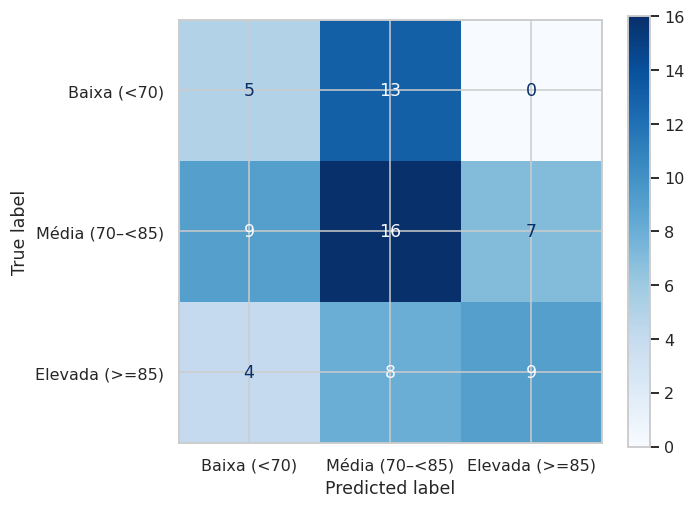

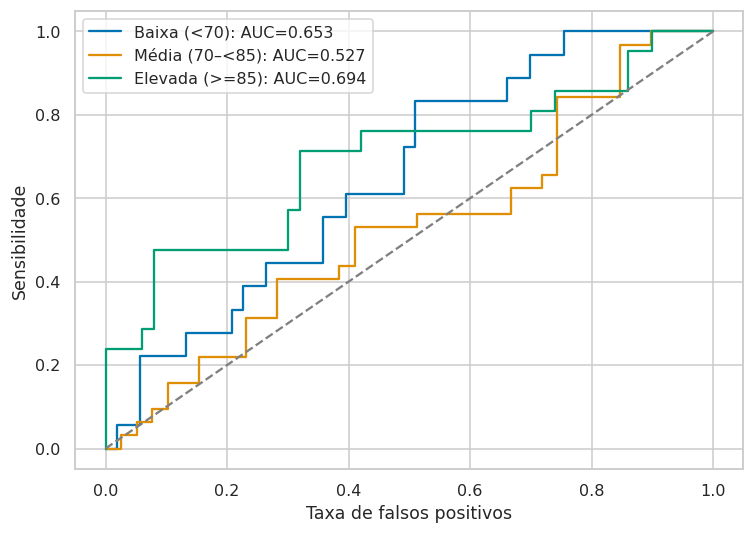

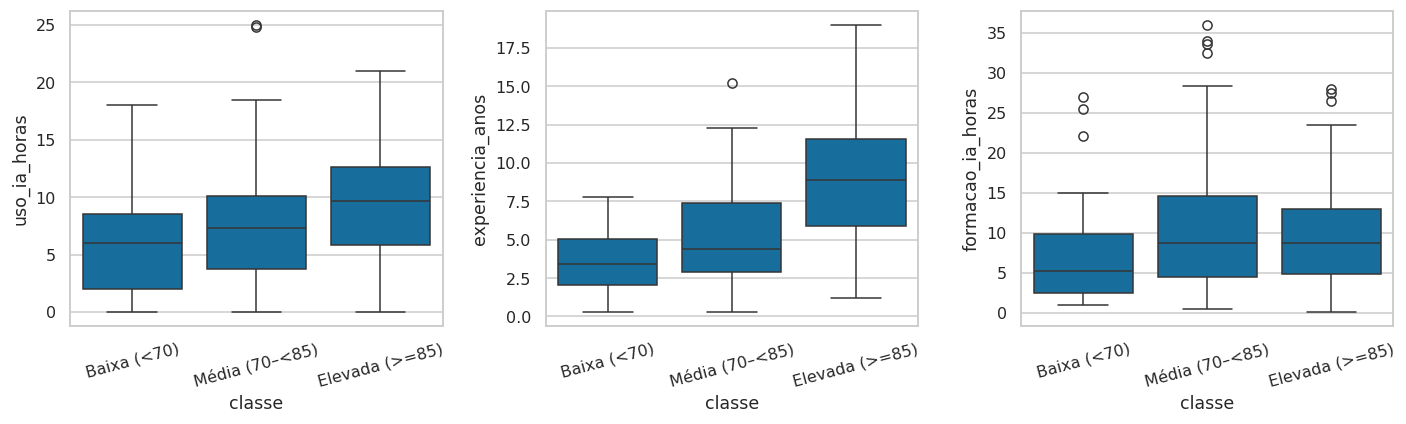

,count,min,median,max
classe,,,,
Baixa (<70),59,19.0,62.0,69.9
Média (70–<85),106,70.2,78.3,84.9
Elevada (>=85),69,85.2,92.0,98.0


{'n': 234, 'n_treino': 163, 'n_teste': 71, 'classes': {'Baixa (<70)': 59, 'Média (70–<85)': 106, 'Elevada (>=85)': 69}, 'treino_classes': {1: 74, 2: 48, 0: 41}, 'teste_classes': {1: 32, 2: 21, 0: 18}, 'convergiu': True, 'LR': np.float64(90.42913479723927), 'p_LR': np.float64(2.4677090839792438e-17), 'gl_LR': 6.0, 'llf': np.float64(-128.49179518465706), 'llnull': np.float64(-173.7063625832767), 'pseudo_R2': np.float64(0.26029309880312124), 'AIC': np.float64(272.98359036931413), 'accuracy': 0.4225352112676056, 'balanced_accuracy': np.float64(0.4021164021164021), 'baseline_accuracy': 0.4507042253521127, 'baseline_bacc': np.float64(0.3333333333333333), 'logloss': 1.0942261753936087, 'AUC_macro': np.float64(0.6248563787714732), 'CV_accuracy': [0.5454545454545454, 0.5757575757575758, 0.6666666666666666, 0.71875, 0.5625], 'CV_bacc': [0.525, 0.5555555555555555, 0.6472222222222221, 0.6925925925925926, 0.5740740740740741], 'perfil_id': 'C149', 'perfil': {'uso_ia_horas': 2.9, 'experiencia_anos': 

In [16]:
# Adaptação fundamentada: limites fixos evitam separar empates com rank(method=first)
# e não são calculados no teste. São apenas categorias didáticas, não metas da empresa.
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
    accuracy_score, balanced_accuracy_score, log_loss, roc_curve, roc_auc_score)
cols=['uso_ia_horas','experiencia_anos','formacao_ia_horas']
base_cl=dados.dropna(subset=['produtividade']+cols).copy()
rotulos=['Baixa (<70)','Média (70–<85)','Elevada (>=85)']
base_cl['classe']=pd.cut(base_cl.produtividade,[-np.inf,70,85,np.inf],labels=rotulos,right=False)
X=base_cl[cols]; yc=base_cl.classe.cat.codes
Xt,Xv,yt,yv=train_test_split(X,yc,test_size=.3,random_state=SEED,stratify=yc)
mn=sm.MNLogit(yt,sm.add_constant(Xt)).fit(method='newton',maxiter=200,disp=False)
assert mn.mle_retvals['converged'], 'Não convergiu: não interpretar coeficientes.'
assert np.isfinite(mn.params.to_numpy()).all()
guardar('multinomial_coeficientes',mn.params); guardar('multinomial_OR',np.exp(mn.params))
guardar('multinomial_p',mn.pvalues); guardar('multinomial_IC_beta',mn.conf_int()); guardar('multinomial_IC_OR',np.exp(mn.conf_int()))
prob=np.asarray(mn.predict(sm.add_constant(Xv))); prev=prob.argmax(axis=1)
assert np.allclose(prob.sum(axis=1),1)
cm=confusion_matrix(yv,prev,labels=[0,1,2]); guardar('multinomial_confusao',pd.DataFrame(cm,index=rotulos,columns=rotulos))
rep=pd.DataFrame(classification_report(yv,prev,labels=[0,1,2],target_names=rotulos,output_dict=True,zero_division=0)).T
display(guardar('multinomial_metricas',rep))
major=int(yt.value_counts().idxmax()); baseline=np.repeat(major,len(yv))
pipe=make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000))
# CV apenas no treino: o teste permanece reservado à avaliação final.
cv_cl=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
cv_acc=cross_val_score(pipe,Xt,yt,cv=cv_cl,scoring='accuracy')
cv_bacc=cross_val_score(pipe,Xt,yt,cv=cv_cl,scoring='balanced_accuracy')
perfil=Xv.iloc[[0]]; pp=mn.predict(sm.add_constant(perfil,has_constant='add'))
R['multinomial']={'n':len(base_cl),'n_treino':len(Xt),'n_teste':len(Xv),
 'classes':base_cl.classe.value_counts(sort=False).to_dict(),'treino_classes':yt.value_counts().to_dict(),
 'teste_classes':yv.value_counts().to_dict(),'convergiu':bool(mn.mle_retvals['converged']),
 'LR':mn.llr,'p_LR':mn.llr_pvalue,'gl_LR':mn.df_model,'llf':mn.llf,'llnull':mn.llnull,'pseudo_R2':mn.prsquared,'AIC':mn.aic,
 'accuracy':accuracy_score(yv,prev),'balanced_accuracy':balanced_accuracy_score(yv,prev),
 'baseline_accuracy':accuracy_score(yv,baseline),'baseline_bacc':balanced_accuracy_score(yv,baseline),
 'logloss':log_loss(yv,prob,labels=[0,1,2]),'AUC_macro':roc_auc_score(yv,prob,multi_class='ovr',average='macro'),
 'CV_accuracy':cv_acc.tolist(),'CV_bacc':cv_bacc.tolist(),'perfil_id':base_cl.loc[perfil.index[0],'id_colaborador'],
 'perfil':perfil.iloc[0].to_dict(),'perfil_prob':np.asarray(pp).tolist(),
 'confusao':cm.tolist(),'coeficientes':mn.params.to_dict(),'OR':np.exp(mn.params).to_dict()}
ConfusionMatrixDisplay(cm,display_labels=rotulos).plot(cmap='Blues'); figura('multinomial_confusao')
fig,ax=plt.subplots(figsize=(7,5)); ybin=label_binarize(yv,classes=[0,1,2])
for j,rot in enumerate(rotulos):
    fpr,tpr,_=roc_curve(ybin[:,j],prob[:,j]); ax.plot(fpr,tpr,label=f'{rot}: AUC={roc_auc_score(ybin[:,j],prob[:,j]):.3f}')
ax.plot([0,1],[0,1],'--',color='gray'); ax.set(xlabel='Taxa de falsos positivos',ylabel='Sensibilidade'); ax.legend()
figura('multinomial_ROC')
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,v in zip(axes,cols): sns.boxplot(data=base_cl,x='classe',y=v,ax=ax); ax.tick_params(axis='x',rotation=15)
figura('multinomial_preditores')
display(guardar('multinomial_distribuicao',base_cl.groupby('classe',observed=True).produtividade.agg(['count','min','median','max'])))
guardar('multinomial_correlacoes_treino',Xt.corr())
print(R['multinomial'])
(OUT/'resultados.json').write_text(json.dumps(R,ensure_ascii=False,indent=2,default=converter),encoding='utf-8')
print('Suplemento concluído: resultados reais, sem dados inventados.')

## 15. Verificação independente de contas, bootstrap e limites

**Pergunta e abordagem:** Confirmar contas por fórmulas independentes e avaliar robustez por reamostragem.

In [17]:
# Executar após analise.py e suplemento.py. Bootstrap de pares preserva associação X–Y.
validacoes=[]
def verificar(nome,condicao):
    assert bool(condicao), nome
    validacoes.append({'verificacao':nome,'resultado':'OK'})
verificar('241 linhas originais e 240 IDs',len(brutos)==241 and brutos.id_colaborador.nunique()==240)
verificar('Uma linha removida, 3 células uniformizadas',len(alteracoes)==4 and len(dados)==240)
verificar('Nenhum valor numérico alterado',dados[numericas].equals(brutos.loc[dados.index,numericas]))
verificar('Mesmos índices nas regressões comparadas',list(multiplo.model.data.row_labels)==list(simples_comum.model.data.row_labels))
verificar('OLS manual = statsmodels',np.allclose(np.linalg.lstsq(multiplo.model.exog,multiplo.model.endog,rcond=None)[0],multiplo.params))
verificar('R2 simples = Pearson ao quadrado',np.isclose(simples.rsquared,pear.statistic**2))
verificar('F clássico simples = t²',np.isclose(simples.fvalue,simples.tvalues['uso_ia_horas']**2))
# Welch completo: A/[1+2(k-2)B/(k²-1)], B=sum((1-w_i/W)²/(n_i-1)).
ni=np.array([len(g) for g in grupos]); mi=np.array([g.mean() for g in grupos]); vi=np.array([g.var(ddof=1) for g in grupos])
wi=ni/vi; W=wi.sum(); mw=(wi*mi).sum()/W; B=(((1-wi/W)**2)/(ni-1)).sum()
Fw=(wi*(mi-mw)**2).sum()/(K-1)/(1+2*(K-2)*B/(K*K-1)); dfw=(K*K-1)/(3*B)
verificar('Welch manual = biblioteca',np.isclose(Fw,welch.statistic) and np.isclose(dfw,welch.df_denom))
R['contas_Welch']={'pesos':wi.tolist(),'media_ponderada':mw,'B':B,'F':Fw,'gl2':dfw}
boot=np.random.default_rng(2026); mat=multiplo.model.exog; yy=multiplo.model.endog
j=multiplo.params.index.get_loc('uso_ia_horas'); betas=[]
for _ in range(3000):
    ix=boot.integers(0,len(yy),len(yy)); betas.append(np.linalg.lstsq(mat[ix],yy[ix],rcond=None)[0][j])
zprod=dados.produtividade.dropna().to_numpy()
medias=boot.choice(zprod,(5000,len(zprod)),replace=True).mean(axis=1)
R['bootstrap']={'B_coef':3000,'IC_percentil_b_IA':np.quantile(betas,[.025,.975]).tolist(),
                 'B_media':5000,'IC_percentil_media':np.quantile(medias,[.025,.975]).tolist(),
                 'semente':2026,'metodo':'reamostragem de linhas independentes; intervalos percentis'}
# Limitação: 13 casos empatados em98 sugerem possível teto, mas não demonstram censura.
R['limites_resposta']={'n_98':int(dados.produtividade.eq(98).sum()),'minimo':dados.loc[dados.produtividade.idxmin()].to_dict(),
                     'previsoes_multiplas_fora_0_100':int(((multiplo.fittedvalues<0)|(multiplo.fittedvalues>100)).sum())}
guardar('matriz_correlacao_explicativas',comum[[c for c in preditores if c!='departamento']].corr())
guardar('casos_excluidos_modelo_multiplo',dados.loc[~dados.index.isin(comum.index)])
R['casos_por_analise']={'base_limpa':len(dados),'media_produtividade':dados.produtividade.count(),
                       'media_uso':dados.uso_ia_horas.count(),'associacao_simples':len(pares),
                       'regressao_multipla_comum':len(comum),'classificacao':len(base_cl)}
test_hc3=multiplo.get_robustcov_results(cov_type='HC3',use_t=True).f_test(
    np.eye(len(multiplo.params))[[i for i,n in enumerate(multiplo.params.index) if n not in ['Intercept','uso_ia_horas']]])
R['teste_adicional_HC3']={'F':float(test_hc3.fvalue),'p':float(test_hc3.pvalue),'gl_num':float(test_hc3.df_num),'gl_den':float(test_hc3.df_denom)}
guardar('validacoes',pd.DataFrame(validacoes)); print(pd.DataFrame(validacoes).to_string(index=False))
print('Bootstrap:',R['bootstrap'])
import importlib.metadata as metadata
versoes={p:metadata.version(p) for p in ['numpy','pandas','scipy','statsmodels','matplotlib','seaborn','scikit-learn','openpyxl']}
(OUT/'versoes.json').write_text(json.dumps(versoes,indent=2),encoding='utf-8')
(OUT/'resultados.json').write_text(json.dumps(R,ensure_ascii=False,indent=2,default=converter),encoding='utf-8')

                                verificacao resultado
             241 linhas originais e 240 IDs        OK
Uma linha removida, 3 células uniformizadas        OK
             Nenhum valor numérico alterado        OK
   Mesmos índices nas regressões comparadas        OK
                   OLS manual = statsmodels        OK
           R2 simples = Pearson ao quadrado        OK
                    F clássico simples = t²        OK
                  Welch manual = biblioteca        OK
Bootstrap: {'B_coef': 3000, 'IC_percentil_b_IA': [-0.23049785874136045, 0.4840241421355694], 'B_media': 5000, 'IC_percentil_media': [76.41002100840339, 79.65433823529412], 'semente': 2026, 'metodo': 'reamostragem de linhas independentes; intervalos percentis'}


25505

## 16. Cobertura dos desafios: outros grupos, Tukey e perfis exploratórios

**Pergunta e abordagem:** Exercícios adicionais de cobertura. Clustering é exploratório e não demonstra perfis naturais.

,resposta,n,F_Welch,gl1,gl2,p_Welch,H_Kruskal,p_Kruskal
0,formacao_ia_horas,239,2.685802,3.0,108.751815,0.050145,15.080357,0.001749
1,uso_ia_horas,238,3.086035,3.0,99.253725,0.030713,9.723102,0.021073


,A,B,diferenca,p_Tukey,IC_inf,IC_sup
0,Análise de Dados,Comunicação,-2.122636,0.880528,-9.537744,5.292471
1,Análise de Dados,Desenvolvimento,-1.555274,0.893469,-7.231528,4.120981
2,Análise de Dados,Operações,-2.705550,0.653495,-8.747724,3.336625
3,Comunicação,Desenvolvimento,0.567362,0.996721,-6.425516,7.560241
4,Comunicação,Operações,-0.582913,0.996864,-7.875948,6.710121
5,Desenvolvimento,Operações,-1.150276,0.949241,-6.666107,4.365556


,modelo,D_Lilliefors,p_tabelado
0,simples,0.054371,0.116181
1,multiplo,0.035450,0.726205


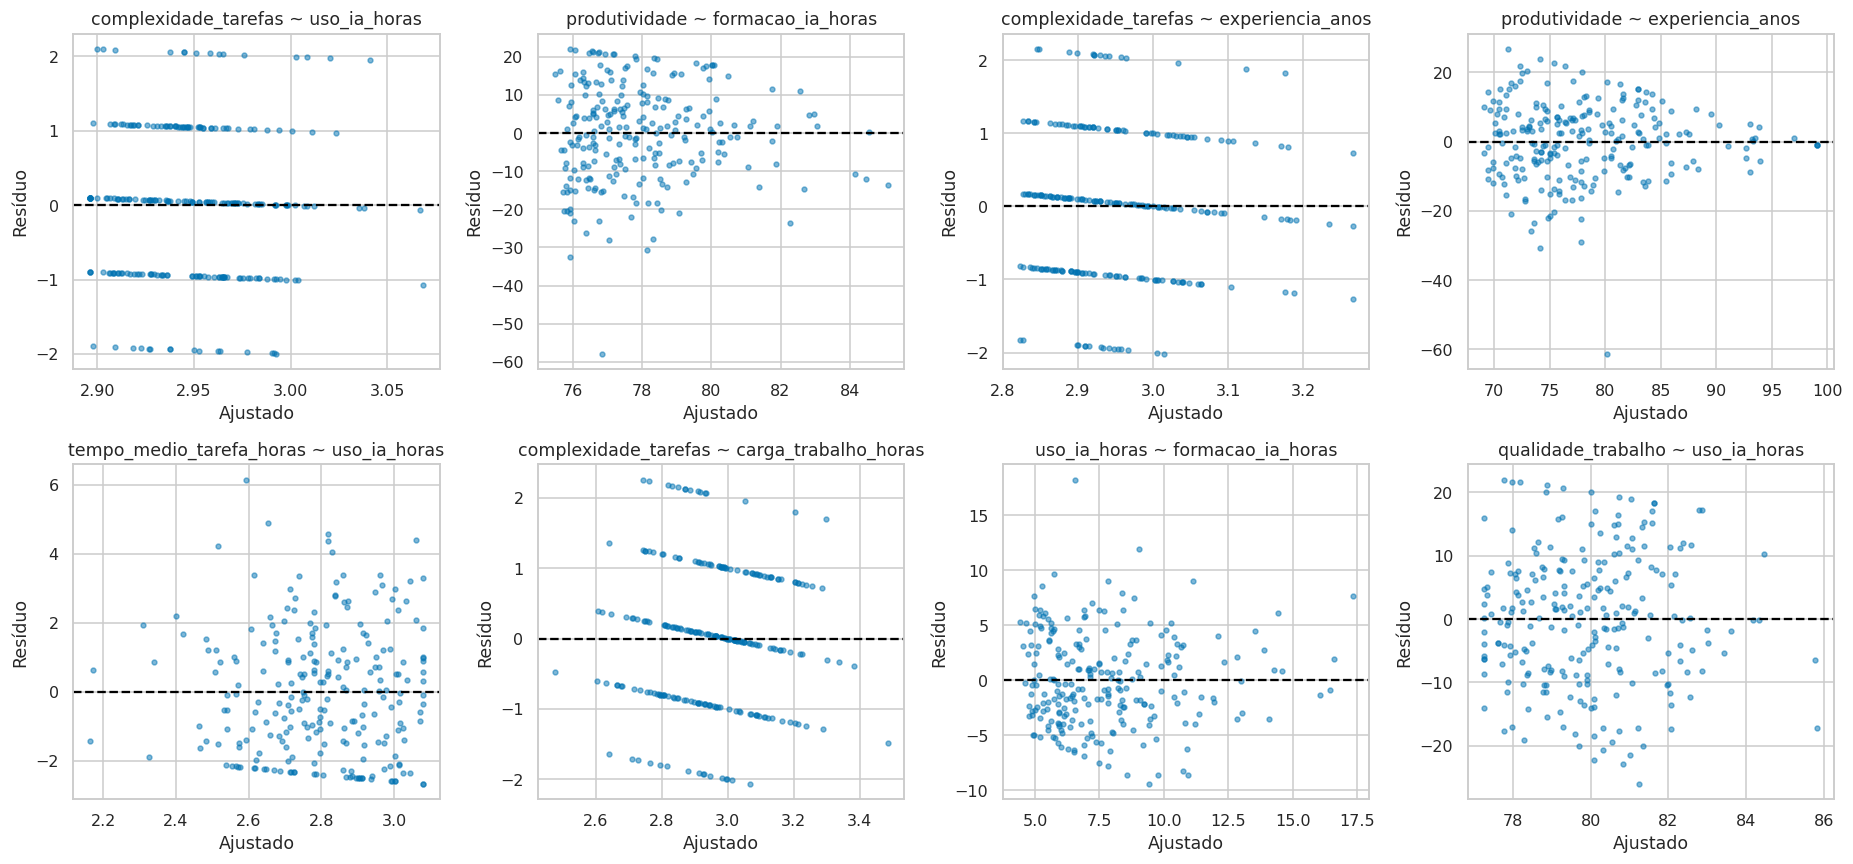

,k,silhueta
0,2,0.338696
1,3,0.360697
2,4,0.283349
3,5,0.298654
4,6,0.304390


uso_ia_horas            experiencia_anos            formacao_ia_horas  \
              count       mean            count       mean             count   
perfil                                                                         
1               125   4.609600              125   3.648800               125   
2                68   9.532353               68  10.526471                68   
3                43  13.941860               43   4.781395                43   

                   
             mean  
perfil             
1        6.380000  
2        7.873529  
3       20.039535

26265

In [18]:
# Execução após as células anteriores; referências didáticas, não novas hipóteses confirmatórias.
extras=[]
for resposta in ['formacao_ia_horas','uso_ia_horas']:
    bb=dados.dropna(subset=['departamento',resposta])
    gg=[g[resposta].to_numpy() for _,g in bb.groupby('departamento')]
    ww=anova_oneway(gg,use_var='unequal',welch_correction=True)
    kk=stats.kruskal(*gg)
    extras.append({'resposta':resposta,'n':len(bb),'F_Welch':ww.statistic,'gl1':ww.df[0],
        'gl2':ww.df[1],'p_Welch':ww.pvalue,'H_Kruskal':kk.statistic,'p_Kruskal':kk.pvalue})
    guardar('departamentos_'+resposta,bb.groupby('departamento')[resposta].agg(['count','mean','std','median']))
display(guardar('anovas_suplementares',pd.DataFrame(extras)))
# Tukey como aplicação do guião Aula3, sob variâncias comuns; Welch/Holm mantém-se principal.
nomes=sorted(dados.departamento.unique())
gg=[dados.loc[dados.departamento.eq(g),'produtividade'].dropna().to_numpy() for g in nomes]
tk=stats.tukey_hsd(*gg); ict=tk.confidence_interval()
tabela_tukey=[]
for i,j in itertools.combinations(range(4),2):
    tabela_tukey.append({'A':nomes[i],'B':nomes[j],'diferenca':tk.statistic[i,j],
        'p_Tukey':tk.pvalue[i,j],'IC_inf':ict.low[i,j],'IC_sup':ict.high[i,j]})
display(guardar('tukey_sensibilidade',pd.DataFrame(tabela_tukey)))
# Lilliefors contempla parâmetros estimados; não substituir por KS de referência fixa.
normalidade=[]
for nome in ['simples','multiplo']:
    mm=modelos[nome]; d,p=lilliefors(mm.resid,dist='norm',pvalmethod='table')
    normalidade.append({'modelo':nome,'D_Lilliefors':d,'p_tabelado':p})
display(guardar('lilliefors_sensibilidade',pd.DataFrame(normalidade)))
# Diagramas residuais dos exercícios alternativos permitem responder ao guião Aula4 p57.
fig,axes=plt.subplots(2,4,figsize=(17,8))
for ax,(vx,vy) in zip(axes.flat,relacoes):
    bb=dados.dropna(subset=[vx,vy]); mm=smf.ols(f'{vy} ~ {vx}',data=bb).fit()
    ax.scatter(mm.fittedvalues,mm.resid,s=10,alpha=.5); ax.axhline(0,color='black',ls='--')
    ax.set(title=f'{vy} ~ {vx}',xlabel='Ajustado',ylabel='Resíduo')
figura('residuos_suplementares')
# Aula1 menciona perfis/clustering: exercício descritivo separado da classificação supervisionada.
# Padronizar impede que uma variável domine só pelas suas unidades. Não incluir a resposta.
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
cb=dados.dropna(subset=['uso_ia_horas','experiencia_anos','formacao_ia_horas']).copy()
cc=['uso_ia_horas','experiencia_anos','formacao_ia_horas']
sc=StandardScaler(); zz=sc.fit_transform(cb[cc]); ajustes={}; ss=[]
for kcl in range(2,7):
    km=KMeans(n_clusters=kcl,n_init=20,random_state=SEED).fit(zz)
    ajustes[kcl]=km; ss.append({'k':kcl,'silhueta':silhouette_score(zz,km.labels_)})
st=pd.DataFrame(ss); melhor=int(st.loc[st.silhueta.idxmax(),'k'])
cb['perfil']=ajustes[melhor].labels_+1
display(guardar('clustering_silhueta',st))
display(guardar('clustering_perfis',cb.groupby('perfil')[cc].agg(['count','mean'])))
guardar('clustering_casos',cb[['id_colaborador','perfil']])
R['clustering']={'n':len(cb),'k':melhor,'silhueta':float(st.silhueta.max()),
 'nota':'k escolhido exploratoriamente em2..6; não demonstra grupos naturais nem estabilidade externa'}
R['anovas_suplementares']=extras
(OUT/'resultados.json').write_text(json.dumps(R,ensure_ascii=False,indent=2,default=converter),encoding='utf-8')

# MEIA_G01 — fórmulas, decisões e proveniência

## Desenho e estratégia

Estudo transversal de dados inteiramente sintéticos. A unidade é o colaborador e a resposta é a pontuação de produtividade (0–100), tratada como quantitativa de intervalo por conveniência do exercício. O dicionário esclarece que não é calculada diretamente das outras colunas. Independência é uma hipótese do desenho, não um resultado de Shapiro, Levene ou Durbin–Watson. Não existe amostragem documentada de uma população real; intervalos e testes são exercícios inferenciais condicionais ao modelo hipotético gerador dos dados.

A investigação principal avalia associação bruta e ajustada, sem procurar demonstrar antecipadamente um benefício da IA. Adota α=0,05 e intervalos de 95%. Testes bilaterais salvo hipóteses pedagógicas direcionais explicitadas. As comparações entre departamentos são uma família de seis contrastes: valores-p de Holm e intervalos simultâneos de Bonferroni. Não se escolhe o procedimento com menor valor-p. Resultados suplementares são exploratórios, não novas provas independentes da hipótese principal. Não se aplica uma correção global indiscriminada a diagnósticos, estimativas e hipóteses distintas; as famílias exploratórias são identificadas no código.

O modelo múltiplo principal inclui uso de IA, experiência, formação, complexidade, carga de trabalho e departamento. São características com justificação substantiva para associação com produtividade e utilização de IA. A ordem temporal entre elas não está estabelecida: não constituem um conjunto de ajustamento causal validado. Excluem-se ID e indicadores contemporâneos de desempenho (qualidade, tarefas, tempo por tarefa) do principal para evitar redundância e interpretações circulares. Estes últimos podem ser descritos no EDA. Não se usa seleção automática por valores-p. Complexidade é ordinal; o principal admite diferença constante por nível, confrontada com codificação categórica.

## Fórmulas de descrição e associação

- Frequência relativa: $f_j=n_j/n$; acumulada: $F_j=\sum_{h\le j}f_h$ (apenas com ordem substantiva, não acumular departamentos).
- Média: $\bar x=\sum_i x_i/n$; variância amostral: $s^2=\sum_i(x_i-\bar x)^2/(n-1)$; desvio-padrão $s=\sqrt{s^2}$; erro-padrão da média $SE=s/\sqrt n$.
- Mediana: quantil 0,5. Quartis obtidos por interpolação linear (pandas); $IQR=Q_3-Q_1$. Sinais de valores extremos fora de $[Q_1-1,5IQR,Q_3+1,5IQR]$. Isto não é uma regra de exclusão.
- Sturges, conforme aula extra: $k=\operatorname{round}(1+\log_2 n)$; amplitude $A=x_{max}-x_{min}$; largura $h=A/k$. Intervalos fechados à esquerda e abertos à direita, exceto último, que inclui o máximo. Comparar $k-3,k,k+5$ classes para avaliar estabilidade visual. Frequências devem somar n.
- Covariância: $s_{xy}=\sum_i(x_i-\bar x)(y_i-\bar y)/(n-1)$.
- Pearson: $r=S_{xy}/\sqrt{S_{xx}S_{yy}}$. Quantifica relação linear; a descrição não exige normalidade. O teste clássico $t=r\sqrt{(n-2)/(1-r^2)}$ exige condições inferenciais adicionais. IC de Fisher: $\tanh[\operatorname{atanh}(r)\pm1,96/\sqrt{n-3}]$.
- Spearman: Pearson dos postos médios. A fórmula $1-6\sum d_i^2/[n(n^2-1)]$ sem correção não se aplica diretamente com empates. O suplemento usa também permutação bilateral de postos: $p=(1+\#\{|r_s^*|\ge|r_s|\})/(B+1)$, B=9999. A permutação testa independência sob permutabilidade; não é um teste geral de qualquer dependência.
- Convenção descritiva dos infográficos específicos: |r|<0,2 muito fraca, 0,2–<0,4 fraca, 0,4–<0,6 moderada, 0,6–<0,8 forte, ≥0,8 muito forte. São rótulos heurísticos, não fronteiras universais nem medidas de causalidade.

## Inferência sobre médias e distribuições

IC da média com σ desconhecido: $\bar x\pm t_{n-1;0,975}s/\sqrt n$, também para n≥30. Interpretação frequencista: 95% dos intervalos construídos pelo procedimento em repetições adequadas conteriam a média hipotética; não 95% dos colaboradores nem uma probabilidade posterior de 95% para o parâmetro fixo.

Teste de uma média: $t=(\bar x-\mu_0)/(s/\sqrt n)$, gl=n−1. No exercício suplementar μ0=70 é referência didática; H0: μ≤70 contra H1: μ>70, calculado na fronteira μ=70.

Welch para dois grupos: $t=(\bar x_1-\bar x_2)/\sqrt{s_1^2/n_1+s_2^2/n_2}$; $\nu=(s_1^2/n_1+s_2^2/n_2)^2/[(s_1^2/n_1)^2/(n_1-1)+(s_2^2/n_2)^2/(n_2-1)]$. IC diferença: estimativa ± $t_{\nu;0,975}SE$. Student usa $s_p^2=[(n_1-1)s_1^2+(n_2-1)s_2^2]/(n_1+n_2-2)$ e gl=n1+n2−2, assumindo variâncias comuns. Cohen d=(média1−média2)/sp é descritivo e depende desta normalização; não converte significância em relevância prática.

ANOVA clássica: $SQ_{entre}=\sum_j n_j(\bar y_j-\bar y)^2$, $SQ_{dentro}=\sum_j\sum_i(y_{ij}-\bar y_j)^2$, $F=[SQ_{entre}/(k-1)]/[SQ_{dentro}/(N-k)]$. H0: todas as médias iguais; H1: pelo menos uma difere. $\eta^2=SQ_{entre}/SQ_{total}$; $\omega^2=[SQ_{entre}-(k-1)QM_{dentro}]/[SQ_{total}+QM_{dentro}]$. Estimativas negativas de ω² são possíveis; reportar como aproximadamente zero, preservando o valor calculado.

Welch global: $w_j=n_j/s_j^2$, $W=\sum_j w_j$, $\bar y_w=\sum_jw_j\bar y_j/W$, $B=\sum_j(1-w_j/W)^2/(n_j-1)$. Então $F_W=\{\sum_j w_j(\bar y_j-\bar y_w)^2/(k-1)\}/\{1+2(k-2)B/(k^2-1)\}$, gl1=k−1 e gl2=(k²−1)/(3B). A correção do denominador é necessária. Welch tolera variâncias distintas, não resolve dependência ou erros graves. Usado como principal pela pergunta sobre médias e grupos de dimensões diferentes; normalidade imperfeita exige sensibilidade, não troca mecânica de estimando.

Holm: ordenar m valores-p, comparar $p_{(j)}$ com α/(m−j+1), mantendo monotonicidade nos p ajustados. IC simultâneo conservador Bonferroni: diferença ± $t_{\nu;1-\alpha/(2m)}SE$. Os pós-hoc apresentados após global não significativo são exploratórios para quantificar incerteza, não uma procura seletiva de pares.

Levene/Brown–Forsythe: fazer ANOVA de $z_{ij}=|y_{ij}-\tilde y_j|$, com mediana por grupo. H0: variâncias iguais. Não rejeitar não prova igualdade.

Mann–Whitney: $U_1=R_1-n_1(n_1+1)/2$, $U_2=n_1n_2-U_1$. SciPy reporta U do primeiro grupo; não necessariamente min(U1,U2). $U_1/(n_1n_2)$ estima P(A>B)+0,5P(A=B). Aproximação com correção de empates. H0 de distribuições iguais; interpretação como deslocamento de medianas exige formas compatíveis.

Kruskal–Wallis: $H=[12/(N(N+1))]\sum_jR_j^2/n_j-3(N+1)$, dividido pela correção de empates $1-\sum(t^3-t)/(N^3-N)$. Comparar com χ²(k−1). Pode detetar diferenças de distribuição; não afirmar automaticamente diferenças de medianas.

## Regressão e diagnósticos

Modelo: $Y_i=\beta_0+\sum_{j=1}^p\beta_jX_{ij}+\epsilon_i$, $E(\epsilon|X)=0$. OLS minimiza $SQE=\sum(y_i-\hat y_i)^2$. Solução formal $\hat\beta=(X'X)^{-1}X'y$ quando posto completo; no código, operações numericamente estáveis por bibliotecas e verificação com lstsq, sem inversão explícita.

Simples: $b_1=S_{xy}/S_{xx}$; $b_0=\bar y-b_1\bar x$. Resíduo $e_i=y_i-\hat y_i$. $SQT=\sum(y_i-\bar y)^2=SQR+SQE$, sendo SQR explicada e SQE residual, conforme notação da Aula4. $s^2=SQE/(n-p-1)$; $R^2=1-SQE/SQT$; $R^2_{aj}=1-(1-R^2)(n-1)/(n-p-1)$.

Inferência clássica: $t_j=b_j/SE(b_j)$, IC $b_j\pm t_{n-p-1;0,975}SE(b_j)$. F global=$[SQR/p]/[SQE/(n-p-1)]$. F parcial de modelos encaixados na MESMA amostra: $[(SQE_R-SQE_U)/(p_U-p_R)]/[SQE_U/(n-p_U-1)]$. AIC=−2logL+2q, BIC=−2logL+qlogn, q número de coeficientes na implementação OLS; comparar a mesma resposta/amostra. R² maior não demonstra causalidade nem previsão externa melhor.

HC3: $\widehat{Var}(b)=(X'X)^{-1}X'\operatorname{diag}[e_i^2/(1-h_{ii})^2]X(X'X)^{-1}$. Mantém os coeficientes, muda a incerteza. Usamos aproximação t com gl residual. É robusta à heteroscedasticidade, não corrige não linearidade, confusão, dependência nem garante IC exatos sob não normalidade. Bootstrap de pares (3000 ajustes; semente2026) complementa o IC do coeficiente IA; IC percentil [q0,025,q0,975]. Bootstrap da média com5000 amostras. Ambos pressupõem linhas independentes e podem herdar limitações da amostra.

Previsão simples em x0: $\hat y_0=b_0+b_1x_0$. $SE_{média}=s\sqrt{1/n+(x_0-\bar x)^2/S_{xx}}$; $SE_{novo}=s\sqrt{1+1/n+(x_0-\bar x)^2/S_{xx}}$. Intervalos usam o quantil t. No múltiplo: $SE_{média}=s\sqrt{x_0'(X'X)^{-1}x_0}$ e termo adicional1 para novo indivíduo. Os intervalos individuais clássicos são aproximados face aos desvios de normalidade; não os tratar como cobertura empiricamente validada. Não truncar intervalos em0/100 sem explicar mudança do procedimento.

VIFj=1/(1−Rj²): regressão auxiliar com intercepto. Limiares5/10 são heurísticos. Dummies de departamento analisadas por coluna; não equivalem a GVIF do fator completo. Shapiro–Wilk: $W=(\sum_i a_ix_{(i)})^2/\sum_i(x_i-\bar x)^2$, pesos derivados dos quantis normais; complemento do Q–Q. Nos resíduos, p é diagnóstico aproximado, pois resíduos não são erros independentes observados. BP (versão robusta de Koenker padrão): LM=nR² da regressão auxiliar de resíduos quadráticos, comparado com χ²(p). RESET acrescenta potência quadrática dos ajustados e testa contribuição; não prova forma correta se não rejeitar.

Leverage: diagonal de $H=X(X'X)^{-1}X'$. Cook: $D_i=e_i^2h_{ii}/[q s^2(1-h_{ii})^2]$, q=p+1. 4/n é sinal de investigação, não eliminação. Durbin–Watson=$\sum_{i=2}^n(e_i-e_{i-1})^2/\sum_i e_i^2$ apenas descritivo numa ordem de IDs sem tempo. Validação cruzada5-fold usa mesmos folds e casos nos modelos: RMSE=$\sqrt{\sum e_i^2/n}$, MAE=$\sum|e_i|/n$. Médias de folds não são IC e cinco folds não estabelecem superioridade universal.

## Proporções, categorias e classificação

Proporção $\hat p=x/n$; teste z sob H0:p=p0: $z=(\hat p-p_0)/\sqrt{p_0(1-p_0)/n}$. IC Wilson: centro $(\hat p+z^2/(2n))/(1+z^2/n)$ e semi-amplitude $z\sqrt{\hat p(1-\hat p)/n+z^2/(4n^2)}/(1+z^2/n)$. Binomial exato complementa aproximação. Comparação de duas proporções: z usa proporção combinada $(x_1+x_2)/(n_1+n_2)$; IC diferença usa Newcombe com Wilson, não a simples apresentação de dois IC individuais.

χ² independência=$\sum(O_{ij}-E_{ij})^2/E_{ij}$, $E_{ij}=n_{i+}n_{+j}/n$, gl=(r−1)(c−1); V de Cramér=$\sqrt{\chi^2/[n\min(r-1,c-1)]}$. Ajustamento: mesma soma com Ej=npj0 e gl=k−1 se probabilidades especificadas, reduzindo gl se parâmetros estimados. Fisher2×2 usa distribuição hipergeométrica com margens fixas; OR=ad/(bc), não uma razão de probabilidades. Não necessita frequências pequenas para ser válido; o exemplo comparativo não é motivado por falha das frequências esperadas.

Multinomial: categorias didáticas <70,70–<85,≥85 (não metas validadas); para j=1,2, $\log[P(Y=j|x)/P(Y=0|x)]=\beta_{0j}+\sum_l\beta_{lj}x_l$. $P_j=\exp(\eta_j)/\sum_h\exp(\eta_h)$, η0=0; OR=expβ, IC_OR=exp(ICβ). LR=2(logLmodelo−logLnulo), gl6 neste modelo. Pseudo-R² McFadden=1−logLmodelo/logLnulo, diferente de variância explicada. Independência, ausência de separação, linearidade dos log-rácios e hipótese IIA são limitações; por haver ordem natural, um modelo ordinal é alternativa futura. Não foi validada IIA apenas porque o ajuste convergiu.

Accuracy=acertos/n; precisão=VP/(VP+FP); recall=VP/(VP+FN); F1=2PR/(P+R); balanced accuracy=média de recalls; macro=média igual por classe. Log-loss=$-\sum_i\log P(Y_i)/n$. ROC OvR usa TPR=VP/(VP+FN), FPR=FP/(FP+VN); AUC mede discriminação, não calibração. Holdout30% estratificado, semente42; CV5-fold só no treino e scaler dentro do pipeline. MNLogit sem regularização e pipeline regularizado são modelos diferentes: a CV é complemento, não estimativa exata do desempenho daquele ajuste MNLogit.

## Métodos que os dados não permitem aplicar à pergunta causal

t emparelhado: $t=\bar d/(s_d/\sqrt n)$; Wilcoxon: postos das diferenças absolutas não nulas, sinal e simetria das diferenças; ANOVA repetida: F=QMcondição/QMerro com esfericidade ou correções; Friedman: $Q=12\sum_jR_j^2/[nk(k+1)]-3n(k+1)$ com correção de empates. Nenhum permite comparar produtividade antes/depois de IA nesta base, pois essas medições não existem. Qualidade e produtividade, apesar da escala0–100, são construtos diferentes, não duas ocasiões da mesma variável. Não fabricar momentos nem emparelhar arbitrariamente colaboradores.

## Proveniência e alterações ao material

| Fonte | Reutilização / decisão |
|---|---|
| Aulas1–3, guiões TXT | pandas.read_excel, info, describe, isna, duplicated, drop_duplicates, value_counts, quantile, hist, scatter; header0 adaptado ao TP; auditoria antes/depois acrescentada |
| Aula3, guião | t.interval, ttest_1samp, ttest_ind(equal_var=False), mannwhitneyu, f_oneway, shapiro, levene; hipóteses e variáveis adaptadas |
| Aula4 notebook e slides; Aula5 | smf.ols, params/bse/tvalues/pvalues/conf_int, previsão summary_frame, resíduos, Q–Q, BP, VIF, amostra comum e F parcial; acrescentados HC3, influência, bootstrap e CV |
| Aula7 notebook | MNLogit, OR/IC/LR, split estratificado, confusão, métricas, ROC, pipeline/CV; limites fixos substituem rank(first)/qcut para não separar empates nem definir classes com teste |
| Infográfico ANOVA Welch | Corrigido denominador da estatística; ver fórmula completa acima e anova_oneway |
| Infográfico duas proporções | proportion_confint(counts,nobs) dá IC separados, não IC diferença; substituído por confint_proportions_2indep |
| Guia normalidade | Não usar KS comum com média/desvio estimados como se referência fosse fixa; usar Shapiro e Q–Q; Lilliefors seria alternativa |
| Guias IC e inferência | t com σ desconhecido também n≥30; p alto não prova H0; evitar seleção mecânica de método por Shapiro/Levene |
| Spearman / Mann–Whitney / Kruskal | Postos médios com empates; U do primeiro grupo; distinguir distribuições de medianas |
| Fisher | IC padrão de Table2x2 não é automaticamente exato; não o rotular como Fisher exato |
| Levene | Não é requisito do t emparelhado; normalidade relevante é das diferenças |
| Resultados ilustrativos dos PNG | Não transcrever números dos exemplos como calculados no TP; todos os resultados desta entrega são executados |
| Paginação PDFs | Referências usam página física; rodapés apresentam totais inconsistentes em vários PDFs |

Referências adicionais consultadas em03/11/2026: [statsmodels ANOVA/Welch](https://www.statsmodels.org/stable/generated/statsmodels.stats.oneway.anova_oneway.html), [IC de diferença de proporções](https://www.statsmodels.org/v0.12.2/generated/statsmodels.stats.proportion.confint_proportions_2indep.html), [Lilliefors](https://www.statsmodels.org/v0.11.1/generated/statsmodels.stats.diagnostic.lilliefors.html). As versões efetivamente executadas constam de resultados/versoes.json. Os ficheiros de origem e SHA256 constam de fontes_extraidas/inventario.json.


## Descarregar resultados no Colab
Opcional: a célula seguinte compacta os CSV, gráficos e metadados. O notebook deve ser guardado
em Ficheiro → Guardar e pode ser descarregado em formato .ipynb. O relatório e o catálogo de perguntas
são entregues também como documentos autónomos.

In [19]:
import shutil
arquivo_resultados=shutil.make_archive(str(BASE/'MEIA_G01_resultados'),'zip',OUT)
print('Resultados compactados:',arquivo_resultados)
# Para descarregar no Colab, descomente:
# from google.colab import files
# files.download(arquivo_resultados)

Resultados compactados: /content/MEIA_G01_resultados.zip


# MEIA_G01 — Catálogo de perguntas e respostas dos materiais

Este complemento adapta a base «semana caótica» ao contexto IA/produtividade. Não afirma que sono seja produtividade,
café seja IA ou stress seja complexidade: preserva o tipo de pergunta e explicita a nova variável. Os números dos slides
não foram copiados como resultados deste TP. As perguntas repetidas remetem para uma resposta temática comum,
mantendo-se o inventário das ocorrências e as páginas físicas. «Questões?» no fim de uma aula é um convite à discussão,
não um exercício com resultado; não entra no inventário. As fórmulas estão em METODOLOGIA.md e no notebook.

As 40 perguntas do enunciado têm respostas individualizadas nas secções 1.1–7.5 do relatório e do notebook.
Os testes suplementares são pedagógicos/exploratórios, sem pré-registo nem validade externa garantida.




## A — Dados, população, unidade e preparação

Uma linha válida representa um colaborador; as colunas representam atributos, não necessariamente preditores.
O ID identifica e não quantifica uma característica. Temos 241 registos/240 pessoas/11 colunas, passando a 240 após
remover a duplicação exata de C084. População real e plano amostral não são documentados. Descrever esta base não é
inferir automaticamente para empresas reais. O dicionário determina unidades e escalas; complexidade é ordinal,
departamento nominal, tarefas uma contagem e produtividade a resposta quantitativa limitada.

No Colab: criar/abrir MEIA_G01, executar a célula de leitura e carregar o Excel. pandas.read_excel usa folha Dados,
header=0 neste ficheiro; header=3 dos guiões perderia observações e nomes corretos. Inspecionar info/head/describe antes
de corrigir. Há 8 faltas em 8 IDs, em experiência 1, formação 1, uso 2, complexidade 1, tempo 1, produtividade 2.
drop_duplicates remove só a linha repetida; replace uniformiza 3 grafias de departamento. Não preencher faltas ou extremos
sem justificação. A amostra varia 238 para cada média, 236 para associação e 233 para regressões comparáveis.
O log de limpeza contém linha original, ID, campo, antes/depois e motivo. Ver relatório 1.1–1.6.




## B — Centro, dispersão, frequências, gráficos e valores extremos

Adaptação de «quanto dormem?» para «quanto usam IA e qual a produtividade?». IA: média 7,7185 h,
mediana 7,6 h, s = 4,9317 h, Q1=3,825 h, Q3=10,775 h, AIQ 6,95 h, amplitude 25 h. Produtividade: média 78,0336,
mediana 79,35, s = 12,8371, Q1=70,225, Q3=87,45, AIQ 17,225, amplitude 79. A média não descreve toda a distribuição;
a mediana resiste mais a extremos. Não confundir desvio-padrão dos indivíduos com erro-padrão da média.

Os departamentos têm 85/66/58/31 colaboradores (Desenvolvimento/Operações/Análise/Comunicação), ou 35,417%/27,5%/
24,167%/12,917%. Não acumular frequências nominais: a ordem é arbitrária. Histograma mostra forma, concentração e
caudas; boxplot mostra quartis e sinalizações, não prova normalidade nem grupos naturais. A produtividade tem cauda à
esquerda (assimetria−0,616); IA tem cauda à direita (0,588). C035/C134 destacam-se em IA e C097/C129 na produtividade.
Não apagar uma observação só porque ultrapassa 1,5 AIQ. O máximo de produtividade é98 em 13 IDs, não uma única pessoa.
Ver relatório 2 e resultados/extremos_iqr.csv; o quadro abaixo permite verificar todas as medidas.

| index | count | mean | std | min | 25% | 50% | 75% | max | IQR | amplitude | assimetria | variancia | limite_inf | limite_sup |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| experiencia_anos | 239 | 5.8456 | 3.9836 | 0.3 | 2.95 | 5 | 8.1 | 19 | 5.15 | 18.7 | 1.0504 | 15.869 | -4.775 | 15.825 |
| formacao_ia_horas | 239 | 9.3439 | 7.0059 | 0.1 | 4.2 | 7.6 | 12.8 | 36 | 8.6 | 35.9 | 1.2858 | 49.083 | -8.7 | 25.7 |
| uso_ia_horas | 238 | 7.7185 | 4.9317 | 0 | 3.825 | 7.6 | 10.775 | 25 | 6.95 | 25 | 0.58812 | 24.321 | -6.6 | 21.2 |
| complexidade_tarefas | 239 | 2.954 | 1.0136 | 1 | 2 | 3 | 4 | 5 | 2 | 4 | 0.068293 | 1.0273 | -1 | 7 |
| carga_trabalho_horas | 240 | 41.895 | 4.3239 | 29.2 | 38.875 | 41.9 | 44.825 | 56 | 5.95 | 26.8 | 0.12378 | 18.696 | 29.95 | 53.75 |
| tarefas_concluidas | 240 | 30.788 | 7.1582 | 12 | 26 | 30.5 | 36 | 49 | 10 | 37 | 0.10195 | 51.239 | 11 | 51 |
| tempo_medio_tarefa_horas | 239 | 2.7856 | 1.8556 | 0.4 | 1.165 | 2.59 | 3.995 | 8.74 | 2.83 | 8.34 | 0.53285 | 3.4431 | -3.08 | 8.24 |
| qualidade_trabalho | 240 | 79.936 | 10.597 | 55.2 | 71.575 | 80.15 | 87 | 100 | 15.425 | 44.8 | 0.0016872 | 112.3 | 48.437 | 110.14 |
| produtividade | 238 | 78.034 | 12.837 | 19 | 70.225 | 79.35 | 87.45 | 98 | 17.225 | 79 | -0.61629 | 164.79 | 44.387 | 113.29 |




## C — Classes e escolhas do histograma

Para n=238, Sturges dá 1+log₂(238)≈8,895; arredondamos para 9 classes,
tal como o guião. Uso IA: A=25−0=25; h=25/9=2,7778 h. Produtividade: A=98−19=79; h=79/9=8,7778 pontos.
Python calcula arestas e frequências; o investigador escolhe a regra e interpreta. bins=9 pede 9 intervalos, não 9 observações.
As arestas usam [a, b[, exceto o último intervalo que inclui o máximo; não contar limites duas vezes.

Comparamos 6,9e14 classes. Poucas classes alisam detalhes e podem ocultar extremos; muitas criam irregularidade visual
que não prova subpopulações. A maior classe do uso é[5,5556;8,3333[, com 54 pessoas;77,73% usam menos de 11,1111 h.
A cauda acima de 16,6667 h tem 9 casos. As formas globais e extremos devem persistir na comparação, sem escolher a
imagem que melhor apoie uma conclusão. Regras alternativas: Scott h=3,5 s/n^(1/3); Freedman–Diaconis h=2 AIQ/n^(1/3).
São guias, não uma decisão universal. As tabelas somam 238 e a frequência relativa soma 1.


### Uso semanal de IA

| index | inferior | superior | n | f | F |
| --- | --- | --- | --- | --- | --- |
| 0 | 0 | 2.7778 | 43 | 0.18067 | 0.18067 |
| 1 | 2.7778 | 5.5556 | 42 | 0.17647 | 0.35714 |
| 2 | 5.5556 | 8.3333 | 54 | 0.22689 | 0.58403 |
| 3 | 8.3333 | 11.111 | 46 | 0.19328 | 0.77731 |
| 4 | 11.111 | 13.889 | 24 | 0.10084 | 0.87815 |
| 5 | 13.889 | 16.667 | 20 | 0.084034 | 0.96218 |
| 6 | 16.667 | 19.444 | 4 | 0.016807 | 0.97899 |
| 7 | 19.444 | 22.222 | 3 | 0.012605 | 0.9916 |
| 8 | 22.222 | 25 | 2 | 0.0084034 | 1 |

### Produtividade

| index | inferior | superior | n | f | F |
| --- | --- | --- | --- | --- | --- |
| 0 | 19 | 27.778 | 1 | 0.0042017 | 0.0042017 |
| 1 | 27.778 | 36.556 | 0 | 0 | 0.0042017 |
| 2 | 36.556 | 45.333 | 1 | 0.0042017 | 0.0084034 |
| 3 | 45.333 | 54.111 | 6 | 0.02521 | 0.033613 |
| 4 | 54.111 | 62.889 | 23 | 0.096639 | 0.13025 |
| 5 | 62.889 | 71.667 | 39 | 0.16387 | 0.29412 |
| 6 | 71.667 | 80.444 | 60 | 0.2521 | 0.54622 |
| 7 | 80.444 | 89.222 | 59 | 0.2479 | 0.79412 |
| 8 | 89.222 | 98 | 49 | 0.20588 | 1 |




## D — Associação, Pearson, Spearman e covariância

O par café/sono ou telemóvel/sono adapta-se à pergunta IA/produtividade.
Com 236 pares completos, Pearson r=0,24086, p=0,000187; IC 95%[0,11675;0,35756]. Covariância=15,20197 pontos×h.
Spearman usa postos médios e dáρ=0,26587, p=0,0000351; permutação bilateral 9999 dáp=0,0001. Ambos sugerem associação
positiva fraca; diferem porque Pearson usa distâncias e Spearman usa ordenação. A presença de faltas requer exclusão
dos mesmos pares, não duas exclusões independentes que desalinhem pessoas. nan_policy='omit' faz esse tratamento.
Um NaN sem tratamento não significa ausência de associação.

Os gráficos revelam dispersão e extremos. Pearson não descreve toda a possível dependência; r≈0 não excluiria relação
não linear. C014(4,9 h;98) e C134(25 h;71,6) refutam a leitura determinista. O valor-p não mede força nem causalidade.
Nas regressões de sensibilidade, remover C134 não recupera evidência clara para IA ajustada. As outras perguntas de
associação e regressão têm resultados no blocoK; não escolher entre Pearson/Spearman pelo menor valor-p.




## E — IC, hipóteses, decisão e generalização

A estimativa pontual da média da produtividade é78,0336. O IC t = 95% é[76,3943;79,6729],
com n = 238, gl 237, s = 12,8371 e SE≈0,8321. O IC tem interpretação de cobertura em repetições do procedimento,
não probabilidade de 95% para um parâmetro fixo nem intervalo de 95% dos indivíduos. Bootstrap 5000:[76,4100;79,6543].

Adaptação do exercício «média de produtividade superior a 5» para referência didática 70: H0:μ≤70, H1:μ>70;
t=9,65457, gl 237, p=4,11 ×10⁻¹⁹, d=0,6258. Rejeita-se a fronteira 70 sob os pressupostos, sem a transformar em meta
empresarial. Para «inferior a 7 h» do guião, a estrutura éH 0:μ≥μ0 versusH 1:μ<μ0; se a referência adaptada for 70 pontos,
a mesma estatística positiva produz p unilateral inferior praticamente 1, logo não há evidência de μ<70.
A direção deve ser definida pela pergunta, não escolhida depois do cálculo.

ErroTipoI: rejeitar uma H0 verdadeira; α limita a frequência nominal sob o modelo. ErroTipoII: não rejeitar quando uma
alternativa é verdadeira; potência=1−β. p>0,05 não demonstra igualdade. Métodos paramétricos modelam parâmetros e
distribuições; não paramétricos continuam a exigir condições (independência, permutabilidade, formas em certas leituras).
A escolha depende da pergunta, escala, desenho, grupos, n e distribuição. Inferência válida na base sintética não
assegura generalização real. Em IA, separar treino/teste avalia um aspeto preditivo, não resolve causalidade.




## F — Dois grupos e grupos binários adaptados

«Trabalha/não trabalha» adapta-se, para a comparação principal de dois grupos, a Desenvolvimento/Operações.
Médias 78,0294 versus 79,1797(n = 85/64), medianas 80,4 versus 79,7. Welch t=−0,5351, p=0,5934;
diferença−1,1503, IC 95%[−5,3996;3,0990]; d=−0,0869. Student sob variâncias comuns: t=−0,5249, p=0,6004.
Mann–Whitney U=2669, p=0,8464; P(A>B)+0,5 P(empate) estimada=0,490625. Não há evidência clara de diferença,
sem concluir equivalência. Mann–Whitney não é, em geral, apenas um teste de medianas. Boxplots e dispersões
complementam os valores-p. Levene entre estes grupos: p=0,340, não uma prova de variâncias iguais.

Outras adaptações preservam a estrutura dos desafios:
- Sesta→formação≥10 h: comparar produtividade, uso de IA ou complexidade entre os dois grupos.
- Sobreviveu→produtividade≥80: comparar uso de IA ou experiência; esta categorização usa a resposta e é apenas descritiva.
- Trabalha→carga≥40 h: comparar formação. Os limites 10/80/40 são didáticos e não exigências da base.

As seis comparações são corrigidas por Holm dentro da família. A tabela contém médias, diferenças, estatísticas e
valores-p brutos/corrigidos. Encontramos maiores uso de IA no grupo com formação≥10, uso e experiência no grupo
produtividade≥80; não encontramos evidência nas outras comparações a 5% após Holm. Nenhuma prova efeito causal.


| index | grupo | limiar | resposta | n_acima | n_abaixo | media_acima | media_abaixo | diferenca | t_Welch | p_Welch | U | p_MW | p_Welch_Holm | p_MW_Holm |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 0 | formacao_ia_horas | 10 | produtividade | 92 | 145 | 79.786 | 76.815 | 2.9707 | 1.8167 | 0.070641 | 7454.5 | 0.12742 | 0.21192 | 0.38227 |
| 1 | formacao_ia_horas | 10 | uso_ia_horas | 91 | 146 | 10.216 | 6.1884 | 4.0281 | 6.4508 | 1.0783e-09 | 9760 | 1.2647e-09 | 5.3916e-09 | 6.3233e-09 |
| 2 | produtividade | 80 | uso_ia_horas | 110 | 126 | 9.0482 | 6.65 | 2.3982 | 3.8162 | 0.0001757 | 8909 | 0.00015559 | 0.00070279 | 0.00062236 |
| 3 | produtividade | 80 | experiencia_anos | 112 | 125 | 7.7696 | 4.1408 | 3.6288 | 7.6053 | 1.6536e-12 | 10586 | 1.004e-11 | 9.9214e-12 | 6.024e-11 |
| 4 | formacao_ia_horas | 10 | complexidade_tarefas | 91 | 147 | 2.9341 | 2.9796 | -0.045526 | -0.32615 | 0.74471 | 6520.5 | 0.73474 | 0.74471 | 0.73474 |
| 5 | carga_trabalho_horas | 40 | formacao_ia_horas | 162 | 77 | 9.6352 | 8.7312 | 0.90402 | 0.94389 | 0.3467 | 6700 | 0.35444 | 0.69341 | 0.70888 |




## G — Mais de dois grupos, pressupostos e comparações múltiplas

«Modos de estudo» adapta-se a departamentos; resposta principal produtividade.
H0: quatro médias iguais; H1: pelo menos uma diferente. Welch F(3;105,717)=0,5034, p=0,6808;
ANOVA clássica F(3;234)=0,4721, p=0,7020; Kruskal H=1,3670, p=0,7133. η²≈0,0060.
Não identificamos diferença; o máximo descritivo em Operações não é um vencedor estatístico.
Independência decorre do desenho; examinar QQ/Shapiro por grupo, Levene e extremos. Levene p=0,523 não garante
homogeneidade. Welch evita exigir variâncias iguais; Kruskal compara distribuições/postos sob a sua hipótese.
Seis testes sem correção aumentariam falsos positivos. ANOVA não identifica pares; Welch/Holm é complemento
exploratório e Tukey, abaixo, é sensibilidade com variâncias comuns. Não inferir equivalência por não rejeitar.

«Horas de estudo por modo» adapta-se também a formação por departamento; «utilização por departamento» é outra
resposta possível. Estas ANOVAs suplementares mantêm os próprios denominadores e não substituem a análise principal.


| index | resposta | n | F_Welch | gl1 | gl2 | p_Welch | H_Kruskal | p_Kruskal |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 0 | formacao_ia_horas | 239 | 2.6858 | 3 | 108.75 | 0.050145 | 15.08 | 0.0017492 |
| 1 | uso_ia_horas | 238 | 3.086 | 3 | 99.254 | 0.030713 | 9.7231 | 0.021073 |

Formação por departamento: Welch p=0,050145, portanto não rejeitamos igualdade de médias a 5%, sem arredondar
para 0,05 para mudar a decisão. Kruskal p=0,001749 deteta diferenças na distribuição dos postos; não testa a mesma
hipótese sobre médias. Uso de IA: Welch p=0,030713 e Kruskal p=0,021073 dão evidência exploratória de diferenças.
Se as duas perguntas sobre médias forem consideradas uma família com Holm, ambos os valores ajustados excedem
0,05 (mínimo 0,061426). Não confundir estas explorações com a conclusão sobre produtividade, nem escolher o teste
mais favorável depois de observar os resultados.


### Tukey (sensibilidade)

| index | A | B | diferenca | p_Tukey | IC_inf | IC_sup |
| --- | --- | --- | --- | --- | --- | --- |
| 0 | Análise de Dados | Comunicação | -2.1226 | 0.88053 | -9.5377 | 5.2925 |
| 1 | Análise de Dados | Desenvolvimento | -1.5553 | 0.89347 | -7.2315 | 4.121 |
| 2 | Análise de Dados | Operações | -2.7055 | 0.6535 | -8.7477 | 3.3366 |
| 3 | Comunicação | Desenvolvimento | 0.56736 | 0.99672 | -6.4255 | 7.5602 |
| 4 | Comunicação | Operações | -0.58291 | 0.99686 | -7.8759 | 6.7101 |
| 5 | Desenvolvimento | Operações | -1.1503 | 0.94924 | -6.6661 | 4.3656 |




## H — Regressão simples: as 12 perguntas da Aula 4/p 57

1. Pergunta: como se associa o uso semanal de IA à produtividade?
2. X=uso_ia_horas; Y=produtividade. A escolha resulta da questão, não é intercambiável para previsão.
3. O diagrama sugere tendência positiva ligeira; grande dispersão e extremos impedem uma leitura determinista.
4. Equação: ŷ=73,039679+0,627283 X, n = 236.
5. Declive:0,627 pontos por hora na média marginal; intercepto previsão em 0 h, sem interpretação causal.
6. TesteH 0:β1=0; t²=F=14,41123, p=0,000187; evidência linear sob o modelo.
7. IC clássico 95% do declive:[0,301737;0,952830]. A incerteza refere-se ao coeficiente, não a 95%das pessoas.
8. R²=0,058014: explica 5,8%;94,2%ficam por explicar. R² não mede causalidade nem desempenho externo.
9. Resíduos dispersos com cauda negativa; C097 exige atenção, não eliminação automática. Ver figura de diagnóstico.
10. Shapiro p=0,000128 rejeita normalidade estrita; QQ permite observar onde a aproximação falha.
11. BP p=0,976 não deteta heteroscedasticidade, sem provar variância constante.
12. Resposta: associação positiva fraca, utilidade explicativa limitada e ausência de conclusão causal.

OLS minimizaΣ(y−ŷ)²; b1=Sxy/Sxx, b0=ȳ−b1 x̄. Sxx 5695,1353; Sxy 3572,4634. Erro-padrão mede incerteza do
coeficiente; dividirb 1 porSE obtémt. SQT=SQR+SQE; no simples com intercepto, R²=r². Relação significativa pode explicar
pouco. As restantes parcelas podem refletir fatores omitidos, variabilidade individual e especificação inadequada,
não uma percentagem causal atribuível a um fator particular.

Para 5 h e 10 h, previsões 76,1761/79,3125; diferença 3,1364. C001:68 observado, 77,8698 previsto, resíduo−9,8698.
IC da média é mais estreito que IP individual, pois IP inclui variabilidade residual de uma nova observação.
A incerteza aumenta longe de x̄ através de(x0−x̄)²/Sxx. Não extrapolar indiscriminadamente nem assumir normalidade
perfeita dos resíduos. As alternativas de X/Y dos desafios estão no blocoK com equações e diagnósticos.

| index | mean | mean_se | mean_ci_lower | mean_ci_upper | obs_ci_lower | obs_ci_upper |
| --- | --- | --- | --- | --- | --- | --- |
| 5 | 76.176 | 0.9317 | 74.341 | 78.012 | 51.54 | 100.81 |
| 7 | 77.431 | 0.82158 | 75.812 | 79.049 | 52.81 | 102.05 |
| 10 | 79.313 | 0.8916 | 77.556 | 81.069 | 54.682 | 103.94 |




## I — Regressão múltipla, desafio Aula 4/p 98 e Aula 5

A pergunta agora é condicional: a IA associa-se à produtividade mantendo constantes experiência, formação,
complexidade, carga e departamento? A equação completa está no relatório 6.3; β̂=(XᵀX)⁻¹Xᵀy quando invertível,
usando métodos numéricos estáveis na biblioteca. Há 8 termos explicativos e intercepto, n = 233. Cada coeficiente
é uma associação condicional nas unidades próprias. Indicadores comparam departamentos com Análise de Dados.

Teste global clássico F=11,9554, p=3,57 ×10⁻¹⁴ testa todos os 8 declives zero, não cada um isoladamente. O coeficiente de
IA é0,143558, IC HC3[−0,229937;0,517054], p=0,4496. Experiência tem 1,60955 pontos/ano, IC HC3[1,30779;1,91131];
carga 0,38086 pontos/h, IC[0,06260;0,69911]. Formação 0,21499, p=0,06355 e complexidade−0,97397, p=0,20421;
os sinais não dispensam incerteza. Não interpretar um teste individual como contribuição causal exclusiva.

R²=0,29922; ajustado 0,27419. O ajustado penaliza parâmetros; não se deve comparar o R² simples com n = 236 ao múltiplo
com n = 233 sem repetir o simples na amostra comum. A comparação justa e Fparcial constam do relatório 6.5.
VIF=1/(1−Rj²), usando a matriz com constante; máximo 1,746, sem indicação de colinearidade grave.
Correlação entre explicativas pode inflacionar variâncias e tornar coeficientes instáveis; VIF baixo não prova causalidade.

Resíduos devem estar aproximadamente centrados e sem estrutura sistemática; QQ mostra cauda negativa,
Shapiro p=0,0000216; BPp=0,449; RESETp=0,677. HC3 e bootstrap apoiam a avaliação da incerteza, não corrigem todos
os problemas. Durbin–Watson não testa independência temporal de uma ordem arbitrária de IDs. Usamos análise de
influência, não remoção automática. O desafio de novo modelo é respondido pelo principal e pela alternativa
parcimoniosa de 4 preditores (R²aj0,26716, AIC 1783,605), com melhor AIC/BIC mas menor R².

O exercício de novo perfil da Aula 5 é adaptado a perfis existentes, evitando inserir stress=6 na escala complexidade 1–5.
C001:(IA 7,7; exp 0,5; form 7,7; complexidade 3; carga 43,7; Operações):ŷ69,9418, ICmédia[66,2637;73,6199], IP[48,0573;91,8262].
C002:(1,7;3,5;1,4;2;34,6; Operações):ŷ70,0628, ICmédia[65,8587;74,2670], IP[48,0838;92,0418].
São intervalos clássicos condicionais ao modelo, com normalidade imperfeita; IP mais largo inclui novo erro individual.
Fornecer todas as colunas à célula get_prediction. Não concluir que aumentar formação causa a variação prevista.
Comparar perfis que mudam vários fatores não isola efeito de um só.




## J — Proporções, qui-quadrado, Fisher e métodos emparelhados

Evento pedagógico: produtividade≥80. São 112/238=47,06%, IC Wilson 95%[40,81%;53,40%].
H0: p=0,5 bilateral; z=−0,9075, p=0,3642; binomial exato p=0,3995. Não há evidência de proporção diferente de 50%.
Desenvolvimento 43/85 versusOperações 30/64: diferença 3,713 pontos percentuais, IC Newcombe[−12,221;19,347]pp;
z=0,4488, p=0,6536. Fisher exato para a tabela 2 ×2: OR=1,1603, p=0,7410. Não confundir OR com diferença de riscos.

Departamento×evento:χ²=1,1988, gl 3, p=0,7533, VdeCramér 0,0710; mínima frequência esperada 14,588>5.
Não identificamos associação categórica. Contagens observadas/esperadas constam dos CSV. Teste de ajustamento
à distribuição didática uniforme dos quatro departamentos: esperadas 60 cada,χ²=25,1, gl 3, p=0,0000147.
Rejeita-se uniformidade; isso descreve composição, não desigualdade de desempenho. A referência uniforme é artificial.

Testes t emparelhado, Wilcoxon emparelhado, ANOVA de medidas repetidas e Friedman não podem estimar
mudança de produtividade antes/depois: existe só uma observação por pessoa. Qualidade/produtividade não são duas
ocasiões da mesma variável. Para os aplicar seria necessário recolher a mesma resposta em momentos/condições
comparáveis nos mesmos IDs; analisar diferenças, normalidade das diferenças (t), simetria para Wilcoxon e, conforme
o caso, esfericidade/correções. Não inventar pares. Levene não é requisito de um t emparelhado.

Os fluxogramas são guias: conhecerσnão é o mesmo que estimarσpor s; t continua adequado com σdesconhecido
mesmo se n≥30. KS com parâmetros normais estimados exige correção de Lilliefors; os diagnósticos complementares
estão no CSV. Os p tabelados podem ter limites numéricos. Todos estes testes mantêm hipóteses de desenho.




## K — Desafios de associações e regressões alternativas — Aulas 1–4

As adaptações são: telemóvel/stress→IA/complexidade; estudo/produtividade→formação/produtividade;
exercício/stress→experiência/complexidade; sono/produtividade→experiência/produtividade;
café/sono→IA/tempo médio por tarefa; trabalho/stress→carga/complexidade;
séries/caos→formação/usoIA (nova pergunta, sem equivalência conceptual); telemóvel/produtividade→IA/qualidade.
A pergunta central IA/produtividade já está no blocoD. Nas perguntas sobre grupos binários usa-se o blocoF.

Cada linha da tabela define a pergunta «X associa-se aY?», a equação ŷ=b0+b1 X, n, Pearson/Spearman, ICrobusto do
declive, R² e diagnósticos. Para complexidade ordinal, Spearman é a leitura principal; OLS serve apenas de exercício
numérico, sem supor por isso uma resposta contínua verdadeiramente intervalar. A família das 8 correlações Spearman
usa Holm. Formação/produtividade, experiência/produtividade, carga/complexidade, formação/uso e IA/qualidade
mantêm pHolm<0,05; as outras não. Destaca-se experiência/produtividade (r≈0,499), mais forte do que IA/produtividade.
Gráficos de dispersão e resíduos estão nas saídas. Dispersão larga, níveis discretos e não normalidade em vários modelos
limitam interpretações. pBP>0,05 não garante homoscedasticidade. Estas relações são exploratórias, sem causalidade.


### Associação e multiplicidade

| X | Y | n | r | rho | p_rho_Holm |
| --- | --- | --- | --- | --- | --- |
| uso_ia_horas | complexidade_tarefas | 237 | 0.033516 | 0.011456 | 0.86073 |
| formacao_ia_horas | produtividade | 237 | 0.14655 | 0.16522 | 0.04339 |
| experiencia_anos | complexidade_tarefas | 238 | 0.093219 | 0.089301 | 0.42198 |
| experiencia_anos | produtividade | 237 | 0.49893 | 0.50698 | 5.6009e-16 |
| uso_ia_horas | tempo_medio_tarefa_horas | 237 | -0.09747 | -0.09599 | 0.42198 |
| carga_trabalho_horas | complexidade_tarefas | 239 | 0.16077 | 0.1714 | 0.039579 |
| formacao_ia_horas | uso_ia_horas | 237 | 0.51291 | 0.41456 | 2.0523e-10 |
| uso_ia_horas | qualidade_trabalho | 238 | 0.15895 | 0.18221 | 0.028825 |

### Equações, incerteza e diagnósticos

| X | Y | b0 | b1 | IC_b1_inf | IC_b1_sup | R2 | p_Shapiro | p_BP |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| uso_ia_horas | complexidade_tarefas | 2.8962 | 0.0068873 | -0.01958 | 0.033355 | 0.0011233 | 2.0312e-09 | 0.57531 |
| formacao_ia_horas | produtividade | 75.452 | 0.26791 | 0.05071 | 0.4851 | 0.021476 | 0.0002126 | 0.054228 |
| experiencia_anos | complexidade_tarefas | 2.815 | 0.023722 | -0.0058468 | 0.053292 | 0.0086897 | 2.9332e-07 | 0.41472 |
| experiencia_anos | produtividade | 68.628 | 1.605 | 1.3459 | 1.864 | 0.24893 | 2.0144e-05 | 0.14472 |
| uso_ia_horas | tempo_medio_tarefa_horas | 3.0795 | -0.036631 | -0.083913 | 0.010651 | 0.0095004 | 2.3222e-06 | 0.60451 |
| carga_trabalho_horas | complexidade_tarefas | 1.3758 | 0.037657 | 0.0087523 | 0.066563 | 0.025846 | 0.000128 | 0.25238 |
| formacao_ia_horas | uso_ia_horas | 4.3648 | 0.3601 | 0.28498 | 0.43522 | 0.26308 | 0.0050657 | 0.81527 |
| uso_ia_horas | qualidade_trabalho | 77.267 | 0.34265 | 0.082491 | 0.60282 | 0.025265 | 0.14153 | 0.14899 |




## L — Aula 7 —17 perguntas de classificação multinomial

**1. Bibliotecas/dados.** pandas/numpy/scipy/statsmodels e sklearn; dados limpos do TP, 234 casos completos em
produtividade, IA, experiência, formação. Não usar IDs como preditores.

**2. Classes.** Baixa:<70; Média:[70;85[; Elevada:≥85. Limiares didáticos fixos; conservar empates e não usar o teste para
estimar quantis. A resposta contínua permanece principal: discretizar perde informação.

**3. Equilíbrio.**59/106/69 casos. A classe mais frequente éMédia. Treino:41/74/48; teste:18/32/21.
Usar sempreMédia dá 32/71=45,07%accuracy no teste; balanced accuracy 1/3.

**4. Preditores por classe.** Os gráficos mostram sobreposição dos grupos; experiência tende a ser mais elevada nas
classes superiores. Distribuições completas constam de multinomial_distribuicao.csv e multinomial_preditores.png.
Sobreposição impede separação perfeita evidente, mas convergência por si não valida todos os pressupostos.

**5. Modelo.** Log[P(Y=j)/P(Y=Baixa)]=β0 j+β1 jIA+β2 jexperiência+β3 jformação, j=Média/Elevada.
Softmax converte os preditores lineares em probabilidades positivas que somam 1. A referência éBaixa.

**6. Separação.**Treino 163/teste 71, estratificado 30%, semente 42. Ajustar no treino, prever no teste; CVapenas no treino.
Não ajustar scaler no conjunto inteiro. O teste não escolheu variáveis, limiares ou parâmetros.

**7. Ajuste.**MNLogit sem regularização convergiu. ParaMédia: const−1,49291; IA−0,101879; exp 0,294654; form 0,185267.
ParaElevada: const−4,32649; IA 0,036880; exp 0,574069; form 0,109419. Coeficientes são log-odds, não pontos percentuais.

**8. OR/IC.**IA: Média/BaixaOR 0,9031, IC[0,8143;1,0017]; Elevada/BaixaOR 1,0376, IC[0,9239;1,1652].
Experiência: OR 1,3427[1,1261;1,6009] e 1,7755[1,4520;2,1710]. Formação: OR 1,2035[1,0969;1,3205]
e 1,1156[1,0056;1,2377]. São multiplicadores de odds relativas por unidade, controlando restantes preditores.
Não transformar OR 1,7755 em aumento de 77,55 pontos percentuais na probabilidade.

**9. Significância global.**LR 90,4291, gl 6, p=2,47 ×10⁻¹⁷; llf−128,4918; llnull−173,7064;
pseudoR²McFadden0,26029; AIC 272,9836. PseudoR²não é fração da variância explicada como no OLS.

**10. Probabilidades.**C149:(IA 2,9; exp 6,2; form 4,9):[0,22425;0,57769;0,19806] paraBaixa/Média/Elevada;
classificaçãoMédia por argmax. A probabilidade não é certeza individual nem está demonstrada a calibração.

**11. Matriz de confusão.**Linhas reais, colunas previstas: [[5,13,0],[9,16,7],[4,8,9]].
Acertos 5+16+9=30 de 71. Treze casosBaixa foram classificadosMédia; isto tem significado distinto de um acerto.

**12. Métricas.**Accuracy 0,42254; balanced accuracy 0,40212; macroF 1≈0,40934; logloss 1,09423.
Precisão/recall/F = 1 por classe estão na tabela abaixo. Balanced accuracy dá o mesmo peso ao recall de cada classe;
accuracy pondera implicitamente pela frequência, o que pode ocultar a classe menos frequente.

**13. Baseline.**Não supera a accuracy da classe constante(0,45070), embora melhore balanced accuracy(0,33333).
Logo não declarar sucesso preditivo só peloLR significativo. A métrica relevante depende dos custos dos erros.

**14. ROC.**OvR por classe usa probabilidades, não só rótulos; AUCmacro 0,62486.Discriminação modesta, não calibração.

**15. Estabilidade.**CV 5 no treino com pipeline padronizado e regressão logística regularizada:
accuracy[0,5455;0,5758;0,6667;0,7188;0,5625]. Variação visível e desempenho de teste inferior.
Esse pipeline regularizado é diferente doMNLogit; a CVnão é uma estimativa exata do desempenho do mesmo ajuste.
Não escolher a melhor partição nem reportar apenas treino. Pequena amostra implica incerteza considerável.

**16. Limitações.**Dados sintéticos, classes ordenadas/discretização, independência, linearidade doslog-odds,
colinearidade, separação, convergência, IIA. A pertinência daIIAnão foi demonstrada; modelo ordinal seria alternativa
a estudar se o objetivo fosse classificação. Não afirmar todos os pressupostos verificados apenas por convergir.

**17. Síntese.**Entregar coeficientes/OR/IC, LR, matriz, métricas, ROC, CV e limitações. O modelo não justifica política
empresarial nem previsão fiável generalizada. O notebook contém as células e gráficos executados; a entrega à
docente compete aos autores, não foi enviada automaticamente.


| index | precision | recall | f1-score | support |
| --- | --- | --- | --- | --- |
| Baixa (<70) | 0.27778 | 0.27778 | 0.27778 | 18 |
| Média (70–<85) | 0.43243 | 0.5 | 0.46377 | 32 |
| Elevada (>=85) | 0.5625 | 0.42857 | 0.48649 | 21 |
| accuracy | 0.42254 | 0.42254 | 0.42254 | 0.42254 |
| macro avg | 0.42424 | 0.40212 | 0.40934 | 71 |
| weighted avg | 0.43169 | 0.42254 | 0.42334 | 71 |




## M — Perfis de rotina: adaptação da pergunta sobre clustering

A Aula 1 menciona grupos de rotina. Explorámos perfis de IA/experiência/formação em 236 casos completos,
padronizando cada coluna porz=(x−média)/s. K-means minimiza a soma das distâncias quadráticas aos centros;
não usa produtividade nem rótulos de desempenho. Entre k=2..6, escolhemos exploratoriamente a maior silhueta:
k=3, silhueta=0.3607. Silhueta=(b−a)/max(a, b), com a distância média intragrupo e b ao grupo vizinho.
As médias originais por perfil e a avaliação de k constam dos CSV. Os números dos perfis são arbitrários.
Isto descreve uma partição algorítmica, não demonstra grupos naturais, estabilidade fora da amostra ou causalidade.
Classificação prevê classes conhecidas; clustering procura agrupamentos sem resposta supervisionada.




## N — Índice integral dos guiões de código

**Aula 1, pergunta 1. O que são dados e como os podemos inspecionar?** → Resposta adaptada: blocoA.

**Aula 1, pergunta 2. Qual é a unidade estatística e que variáveis existem?** → Resposta adaptada: blocoA.

**Aula 1, pergunta 3. Quais são as variáveis quantitativas e categóricas?** → Resposta adaptada: blocoA.

**Aula 1, pergunta 4. Quantos valores em falta e duplicados existem?** → Resposta adaptada: blocoA.

**Aula 1, pergunta 5. Como apresentar uma distribuição de frequências?** → Resposta adaptada: blocoB.

**Aula 1, pergunta 6. Como visualizar as horas de sono?** → Resposta adaptada: blocoC.

**Aula 2, pergunta 1. Como importar a base de dados?** → Resposta adaptada: blocoA.

**Aula 2, pergunta 2. Quantos valores em falta existem?** → Resposta adaptada: blocoA.

**Aula 2, pergunta 3. Há linhas duplicadas?** → Resposta adaptada: blocoA.

**Aula 2, pergunta 4. Quais são as linhas repetidas?** → Resposta adaptada: blocoA.

**Aula 2, pergunta 5. Como eliminar duplicados?** → Resposta adaptada: blocoA.

**Aula 2, pergunta 6. Como descrever as horas de sono?** → Resposta adaptada: blocoB.

**Aula 2, pergunta 7. Como calcular o intervalo interquartil?** → Resposta adaptada: blocoB.

**Aula 2, pergunta 8. Como observar a distribuição das horas de sono?** → Resposta adaptada: blocoC.

**Aula 2, pergunta 9. Qual é a relação entre cafés e sono?** → Resposta adaptada: blocoD.

**Aula 2, pergunta 10. Qual é a correlação de Pearson?** → Resposta adaptada: blocoD.

**Aula 2, pergunta 11. Qual é a covariância?** → Resposta adaptada: blocoD.

**Aula 2, pergunta 12. Por que razão Spearman precisa de tratar valores em falta?** → Resposta adaptada: blocoD.

**Aula 2, pergunta 13. Qual é a correlação de Spearman após excluir pares incompletos?** → Resposta adaptada: blocoD.

**Aula 3, pergunta 1. Como carregar e preparar os dados?** → Resposta adaptada: blocoA.

**Aula 3, pergunta 2. Como retirar duplicados e uniformizar categorias?** → Resposta adaptada: blocoA.

**Aula 3, pergunta 3. Qual é a descrição amostral do sono?** → Resposta adaptada: blocoB.

**Aula 3, pergunta 4. Como construir um intervalo de confiança para a média?** → Resposta adaptada: blocoE.

**Aula 3, pergunta 5. Como testar se a média de sono é 7 horas?** → Resposta adaptada: blocoE.

**Aula 3, pergunta 6. Como comparar o sono entre trabalhadores e não trabalhadores?** → Resposta adaptada: blocoF.

**Aula 3, pergunta 7. Como representar os dois grupos?** → Resposta adaptada: blocoF.

**Aula 3, pergunta 8. Como aplicar o teste t de Welch?** → Resposta adaptada: blocoF.

**Aula 3, pergunta 9. Como comparar com Mann–Whitney?** → Resposta adaptada: blocoF.

**Aula 3, pergunta 10. Como descrever as horas de estudo por modo?** → Resposta adaptada: blocoG.

**Aula 3, pergunta 11. Como visualizar as diferenças entre modos?** → Resposta adaptada: blocoG.

**Aula 3, pergunta 12. Como aplicar ANOVA?** → Resposta adaptada: blocoG.

**Aula 3, pergunta 13. Como verificar pressupostos e comparar grupos?** → Resposta adaptada: blocoG.

Aula_4_Colab_Separado.ipynb: preparação→A; regressão simples/IC/previsões→H; múltipla/comparação/VIF/resíduos→I.
Aula 7: todas as 17 perguntas e a pergunta secundária da classe de referência estão respondidas no blocoL.




## O — Perguntas nos slides, incluindo repetições

As quebras de linha da extração podem unir cabeçalhos ao texto. A página física permite consultar o original; a remissão identifica o bloco com a adaptação, os valores e os limites. Exercícios sem ponto de interrogação também estão cobertos: classes(p 23)→C; Aula 4/p 56–57→H/K; Aula 4/p 98→I; Aula 5/p 56→I.

| fonte | pagina_fisica | pergunta_ocorrencia | resposta_bloco |
| --- | --- | --- | --- |
| AULA_1.pdf | 9 | O que torna uma semana caótica? | A/B/D/F/K/L/M |
| AULA_1.pdf | 10 | Que perguntas podemos fazer a estes dados? | A |
| AULA_1.pdf | 11 | O que gostaríamos de descobrir? | A/B/D/F/K/L/M |
| AULA_1.pdf | 11 | ▶ Quanto dormem, em geral, estas pessoas? | A/B/D/F/K/L/M |
| AULA_1.pdf | 11 | ▶ Quem bebe mais café dorme menos? | A/B/D/F/K/L/M |
| AULA_1.pdf | 11 | ▶ Mais tempo no telemóvel significa menor produtividade? | A/B/D/F/K/L/M |
| AULA_1.pdf | 11 | ▶ Quem trabalha apresenta maior stress? | A/B/D/F/K/L/M |
| AULA_1.pdf | 11 | ▶ Fazer uma sesta parece ajudar a produtividade? | A/B/D/F/K/L/M |
| AULA_1.pdf | 11 | ▶ Quem vê mais séries dorme menos? | A/B/D/F/K/L/M |
| AULA_1.pdf | 11 | ▶ Quem consegue “sobreviver” melhor à semana? | A/B/D/F/K/L/M |
| AULA_1.pdf | 12 | Primeira decisão: descrever ou inferir? | A |
| AULA_1.pdf | 12 | Como se distribuem as horas de sono dos 80 participantes? | A |
| AULA_1.pdf | 12 | O que poderíamos concluir sobre uma população mais ampla? | A |
| AULA_1.pdf | 14 | Onde entra a Estatística na Inteligência Artificial? | A/B/D/F/K/L/M |
| AULA_1.pdf | 15 | Quanto dormem estas pessoas? Análise descritiva | A/B/D/F/K/L/M |
| AULA_1.pdf | 15 | Café e sono estão relacionados? Associação / correlação | A/B/D/F/K/L/M |
| AULA_1.pdf | 15 | O que explica a produtividade? Regressão | A/B/D/F/K/L/M |
| AULA_1.pdf | 15 | Quem irá sobreviver à semana? Classificação | A/B/D/F/K/L/M |
| AULA_1.pdf | 15 | Existem diferentes perfis de rotina? Clustering | A/B/D/F/K/L/M |
| AULA_1.pdf | 16 | O que representam as linhas e as colunas? | A |
| AULA_1.pdf | 17 | Todas as colunas são variáveis para analisar? | A |
| AULA_1.pdf | 18 | Que tipo de informação temos? | A |
| AULA_1.pdf | 18 | Nominais Ordinais Discretas Contínuas Porque interessa? | A |
| AULA_1.pdf | 19 | E na nossa semana caótica? | A |
| AULA_1.pdf | 20 | Quanto dormem estas pessoas? | B |
| AULA_1.pdf | 20 | O que queremos conhecer? | B |
| AULA_1.pdf | 20 | Qual é o seu valor típico? | B |
| AULA_1.pdf | 20 | Quanto variam as horas de sono? | B |
| AULA_1.pdf | 20 | Como se distribuem? | B |
| AULA_1.pdf | 20 | Existem valores invulgares? | B |
| AULA_1.pdf | 21 | Centro Onde? | B |
| AULA_1.pdf | 21 | Variabilidade Quanto varia? | B |
| AULA_1.pdf | 21 | Distribuição Que forma? | B |
| AULA_1.pdf | 21 | Outliers O que destoa? | B |
| AULA_1.pdf | 22 | Qual é um valor representativo? | B |
| AULA_1.pdf | 22 | Qual destas medidas representa melhor os dados que estamos a observar? | B |
| AULA_1.pdf | 23 | O centro conta a história toda? | B |
| AULA_1.pdf | 23 | Podem ter exatamente a mesma média e apresentar comportamentos muito diferentes. Porquê? | B |
| AULA_1.pdf | 24 | Quanto variam os dados? | B |
| AULA_1.pdf | 25 | ▶ Os valores estão concentrados numa região? | B |
| AULA_1.pdf | 25 | ▶ A distribuição é aproximadamente simétrica? | B |
| AULA_1.pdf | 25 | ▶ Existe assimetria? | B |
| AULA_1.pdf | 25 | ▶ Existem diferentes concentrações ou grupos? | B |
| AULA_1.pdf | 25 | ▶ Existem valores extremos? | B |
| AULA_1.pdf | 26 | Histograma — quando é útil? | B |
| AULA_1.pdf | 27 | Boxplot — quando é útil? | B |
| AULA_1.pdf | 28 | Apagamos esta observação? | B |
| AULA_1.pdf | 30 | O que fizemos até aqui? | B |
| AULA_1.pdf | 30 | Quanto dormem estas pessoas? | B |
| AULA_1.pdf | 31 | Quanto dormem estas pessoas? | D |
| AULA_1.pdf | 31 | Quem bebe mais café dorme menos? | D |
| AULA_1.pdf | 32 | Mais café está associado a menos sono? | D |
| AULA_1.pdf | 32 | E como podemos responder a esta perguntautilizando Python? | D |
| aula_2.pdf | 2 | Como vamos trabalhar? | A |
| aula_2.pdf | 5 | 3. Como colocamos a base de dados no Colab? | A |
| aula_2.pdf | 5 | Escolher ficheiros→semana_caotica.xlsx O que fizemos? | A |
| aula_2.pdf | 6 | 4. Como abrimos os dados? | A |
| aula_2.pdf | 6 | dados.head() O que significa? | A |
| aula_2.pdf | 7 | 5. Podemos começar imediatamente a analisar? | A |
| aula_2.pdf | 8 | 6. Existem valores em falta? | A |
| aula_2.pdf | 8 | Pergunta:Existem células sem informação? | A |
| aula_2.pdf | 9 | 7. Existem observações duplicadas? | A |
| aula_2.pdf | 9 | Pergunta:Alguma linha aparece repetida? | A |
| aula_2.pdf | 10 | 8. Qual é a observação duplicada? | A |
| aula_2.pdf | 10 | Pergunta:Quais são as linhas envolvidas? | A |
| aula_2.pdf | 12 | 10. As categorias estão bem registadas? | A |
| aula_2.pdf | 12 | Pergunta:Existem categorias escritas de formas diferentes? | A |
| aula_2.pdf | 12 | Porque é importante? | A |
| aula_2.pdf | 13 | dados["modo_estudo"].value_counts() O que fizemos? | A |
| aula_2.pdf | 14 | Quanto dormem estas pessoas? | B |
| aula_2.pdf | 15 | 13. Como resumimos as horas de sono? | B |
| aula_2.pdf | 15 | Pergunta:Qual é o centro e qual é a variabilidade? | B |
| aula_2.pdf | 16 | 14. Quanto variam os 50% centrais? | B |
| aula_2.pdf | 17 | 15. Como é a distribuição das horas de sono? | B |
| aula_2.pdf | 17 | Pergunta:Como se distribuem as horas de sono? | B |
| aula_2.pdf | 17 | Porquê um histograma? | B |
| aula_2.pdf | 18 | 16. Resultado: distribuição das horas de sono O que observamos? | B |
| aula_2.pdf | 20 | Quanto dormem estas pessoas? | D |
| aula_2.pdf | 20 | Quem bebe mais cafés tende a dormir menos horas? | D |
| aula_2.pdf | 22 | Pergunta:O gráfico sugere alguma relação? | D |
| aula_2.pdf | 23 | 21. Resultado: cafés por dia e horas de sono O que observamos? | D |
| aula_2.pdf | 26 | Pergunta:Qual é a intensidade da associação linear? | D |
| aula_2.pdf | 27 | Será que esta observação está a influenciar a correlação de Pearson? | D |
| aula_2.pdf | 28 | Porque aparece agora? | D |
| aula_2.pdf | 29 | Porque não obtivemos um número? | D |
| aula_2.pdf | 32 | 30. O que nos diz Spearman? | D |
| aula_2.pdf | 32 | A magnitude indica umaassociação monotónica negativa moderada. E o p-valor? | D |
| aula_2.pdf | 33 | Porque são diferentes? | D |
| aula_2.pdf | 34 | Quem bebe mais cafés tende a dormir menos horas? | D |
| aula_2.pdf | 35 | 33. O que esta pergunta nos obrigou a aprender? | D |
| aula_2.pdf | 35 | “Quem bebe mais cafés tende a dormir menos horas?” | D |
| aula_2.pdf | 36 | 1. Quem passa mais tempo no telemóvel tende a dormir menos? | K |
| aula_2.pdf | 36 | 2. Quem estuda mais horas tende a apresentar maior produtividade? | K |
| aula_2.pdf | 36 | 3. Mais exercício está associado a menor nível de stress? | K |
| aula_2.pdf | 36 | 4. Mais horas de sono estão associadas a maior produtividade? | K |
| aula_2.pdf | 37 | ▶Qual é a direção da associação? | K |
| aula_2.pdf | 37 | ▶Qual parece ser a sua intensidade? | K |
| aula_2.pdf | 37 | ▶O gráfico é coerente com o coeficiente? | K |
| aula_2.pdf | 37 | ▶Existem observações que merecem atenção? | K |
| aula_2.pdf | 37 | ▶Pearson e Spearman conduzem à mesma leitura? | K |
| aula_2.pdf | 38 | Quanto dormem estas pessoas? | D |
| aula_2.pdf | 38 | Quem bebe mais cafés tende a dormir menos horas? | D |
| aula2_divisao de classes.pdf | 2 | Como se distribuem as horas de sono? | C |
| aula2_divisao de classes.pdf | 4 | Como podemos escolher o número de classes? | C |
| aula2_divisao de classes.pdf | 5 | 4. Porque não escolher simplesmente um número qualquer? | C |
| aula2_divisao de classes.pdf | 10 | 9. Qual é a amplitude total dos dados? | C |
| aula2_divisao de classes.pdf | 13 | O Python decide por nós? | C |
| aula2_divisao de classes.pdf | 14 | 13. O que é uma classe? | C |
| aula2_divisao de classes.pdf | 17 | O que significabins=k? | C |
| aula2_divisao de classes.pdf | 18 | 17. Quem fez o quê? | C |
| aula2_divisao de classes.pdf | 19 | 18. E se utilizarmos outro número de classes? | C |
| aula2_divisao de classes.pdf | 20 | 19. O que devemos observar? | C |
| aula2_divisao de classes.pdf | 20 | ▶Onde se concentra a maioria das observações? | C |
| aula2_divisao de classes.pdf | 20 | ▶A distribuição parece simétrica ou assimétrica? | C |
| aula2_divisao de classes.pdf | 20 | ▶Existem regiões com poucas observações? | C |
| aula2_divisao de classes.pdf | 20 | ▶Existem valores afastados? | C |
| aula2_divisao de classes.pdf | 20 | ▶Alguma escolha de classes esconde informação? | C |
| aula2_divisao de classes.pdf | 20 | ▶Alguma escolha cria demasiado “ruído”? | C |
| aula2_divisao de classes.pdf | 21 | 20. Existem outras regras? | C |
| aula_3.pdf | 2 | ▶Quantas horas dormem os participantes? | E |
| aula_3.pdf | 2 | ▶Quem bebe mais café tende a dormir menos? | E |
| aula_3.pdf | 2 | ▶Que padrões encontramos nos dados? | E |
| aula_3.pdf | 2 | Mas podemos generalizar aquilo que observámos? | E |
| aula_3.pdf | 4 | E onde entra a Inteligência Artificial? | E |
| aula_3.pdf | 4 | O resultado generaliza? | E |
| aula_3.pdf | 4 | O modelo generaliza? | E |
| aula_3.pdf | 5 | Quantas horas dorme, em média, a população? | E |
| aula_3.pdf | 5 | Como utilizar a média da amostra para obter informação sobre a média da população? | E |
| aula_3.pdf | 7 | Estimativa pontual ou por intervalo? | E |
| aula_3.pdf | 8 | O que significa 95% de confiança? | E |
| aula_3.pdf | 9 | Quantas horas dorme, em média, a população? | E |
| aula_3.pdf | 10 | Existe evidência de que a população dorme, em média, menos de 7 horas? | E |
| aula_3.pdf | 11 | A população dorme, em média, menos de 7 horas? | E |
| aula_3.pdf | 12 | Como tomamos a decisão? | E |
| aula_3.pdf | 13 | O que significa um método paramétrico? | E |
| aula_3.pdf | 14 | E um método não paramétrico? | E |
| aula_3.pdf | 14 | Então qual escolhemos? | E |
| aula_3.pdf | 15 | ▶Que pergunta queremos responder? | E |
| aula_3.pdf | 15 | ▶Que tipo de variável temos? | E |
| aula_3.pdf | 15 | ▶Quantos grupos estamos a comparar? | E |
| aula_3.pdf | 15 | ▶As observações são independentes? | E |
| aula_3.pdf | 15 | ▶Como se distribuem os dados? | E |
| aula_3.pdf | 15 | ▶Existem valores extremos? | E |
| aula_3.pdf | 15 | ▶Qual é a dimensão das amostras? | E |
| aula_3.pdf | 15 | ▶Que pressupostos exige o método? | E |
| aula_3.pdf | 16 | Dormimos, em média, menos de 7 horas? | E |
| aula_3.pdf | 17 | Podemos tomar a decisão errada? | E |
| aula_3.pdf | 18 | Erro Tipo I O que aconteceu? | E |
| aula_3.pdf | 19 | Erro Tipo II O que aconteceu? | E |
| aula_3.pdf | 20 | Porque é que isto interessa em IA? | E |
| aula_3.pdf | 21 | Podemos comparar duas amostras? | F |
| aula_3.pdf | 21 | Quem trabalha dorme de forma diferente de quem não trabalha? | F |
| aula_3.pdf | 22 | Quem trabalha dorme de forma diferente? | F |
| aula_3.pdf | 22 | resultado da variabilidade amostral? | F |
| aula_3.pdf | 23 | Como comparamos os dois grupos? | F |
| aula_3.pdf | 23 | “as médias parecem diferentes?” | F |
| aula_3.pdf | 23 | “existe evidência de uma diferença na população?” | F |
| aula_3.pdf | 24 | Quem trabalha dorme de forma diferente? | F |
| aula_3.pdf | 25 | E se a abordagem paramétrica não for adequada? | F |
| aula_3.pdf | 25 | Quando pode ser útil? | F |
| aula_3.pdf | 26 | Mann–Whitney: e neste caso? | F |
| aula_3.pdf | 27 | Testetou Mann–Whitney? | F |
| aula_3.pdf | 28 | E se tivermos mais de dois grupos? | G |
| aula_3.pdf | 28 | As horas de estudo diferem consoante o modo de estudo? | G |
| aula_3.pdf | 29 | As horas de estudo diferem entre os grupos? | G |
| aula_3.pdf | 29 | Estas diferenças existem também para além da amostra? | G |
| aula_3.pdf | 30 | Porque não fazemos três testest? | G |
| aula_3.pdf | 31 | ANOVA: qual é a ideia? | G |
| aula_3.pdf | 32 | As horas de estudo diferem entre os modos de estudo? | G |
| aula_3.pdf | 33 | A ANOVA respondeu a tudo? | G |
| aula_3.pdf | 33 | “Existe pelo menos uma diferença?” | G |
| aula_3.pdf | 33 | “Entre que grupos existe essa diferença?” | G |
| aula_3.pdf | 34 | Até aqui, o que aprendemos? | G |
| aula_3.pdf | 34 | Qual é a média populacional? Intervalo de confiança | G |
| aula_3.pdf | 34 | Dormimos menos de 7 horas? Testetpara uma amostra | G |
| aula_3.pdf | 34 | Dois grupos apresentam diferenças? Welch / Mann–Whitney | G |
| aula_3.pdf | 34 | Três grupos apresentam diferenças? ANOVA | G |
| aula_3.pdf | 36 | Que outras perguntas podemos fazer? | E/F/G |
| aula_3.pdf | 36 | 1.A produtividade média é superior a 5 pontos? | E/F/G |
| aula_3.pdf | 36 | 2.Quem faz sesta dorme, em média, um número de horas diferente de quem não faz sesta? | E/F/G |
| aula_3.pdf | 36 | 3.Quem trabalha estuda, em média, um número de horas diferente de quem não trabalha? | E/F/G |
| aula_3.pdf | 36 | 4.A produtividade difere consoante o modo de estudo: Sozinho, Grupo ou Misto? | E/F/G |
| aula_3.pdf | 36 | Que método escolheriam para responder a cada pergunta? | E/F/G |
| aula_3.pdf | 37 | 1.Quem “sobreviveu” à semana dorme um número de horas diferente de quem não “sobreviveu”? | F/G |
| aula_3.pdf | 37 | 2.O tempo passado no telemóvel difere entre quem trabalha e quem não trabalha? | F/G |
| aula_3.pdf | 37 | 3.As horas de estudo diferem consoante o modo de estudo? | F/G |
| aula_3.pdf | 37 | 4.O nível de stress é diferente entre quem faz sesta e quem não faz? | F/G |
| aula_3.pdf | 38 | Porque é que o método escolhido é adequado à pergunta e aos dados? | F/G |
| aula_3.pdf | 38 | O que significa o resultado estatístico obtido? | F/G |
| aula_3.pdf | 38 | Rejeitamos ou não rejeitamosH0? | F/G |
| aula_3.pdf | 38 | O que podemos concluir,no contexto da pergunta inicial? | F/G |
| aula_3.pdf | 39 | E se pensarmos como cientistas de dados? | L |
| aula_3.pdf | 39 | quem “sobreviveu” de quem não “sobreviveu” à semana caótica? | L |
| aula_3.pdf | 39 | Podemos utilizar estas variáveis para prever quem vai “sobreviver”? | L |
| aula_3.pdf | 40 | O que levamos da Inferência para a IA? | L |
| aula_3.pdf | 40 | Será que aquilo que aprendemos generaliza? | L |
| aula_3.pdf | 41 | Existe uma associação? | H/I |
| aula_3.pdf | 41 | Existe uma diferença? | H/I |
| aula_3.pdf | 41 | Podemos generalizar? | H/I |
| aula_3.pdf | 41 | Agora queremos avançar: Podemos prever? | H/I |
| aula_3.pdf | 41 | Conseguimos explicar ou prever uma variável a partir de uma ou várias outras? | H/I |
| aula_4.pdf | 2 | Porque começamos pela regressão linear? | D |
| aula_4.pdf | 3 | Onde estamos? | D |
| aula_4.pdf | 3 | Podemos construir um modelo que aprenda a relação entre duas variáveis e nos permita fazer previsões? | D |
| aula_4.pdf | 5 | Podemos explicar a produtividade a partir das horas de sono? | D |
| aula_4.pdf | 6 | Porque começamos pelo gráfico? | D |
| aula_4.pdf | 6 | ▶Existe alguma tendência entre as variáveis? | D |
| aula_4.pdf | 6 | ▶A tendência é positiva ou negativa? | D |
| aula_4.pdf | 6 | ▶A relação parece aproximadamente linear? | D |
| aula_4.pdf | 6 | ▶Existem observações muito afastadas das restantes? | D |
| aula_4.pdf | 8 | Que relação parece existir? | D |
| aula_4.pdf | 9 | O que sugere o gráfico? | H |
| aula_4.pdf | 9 | Mas conseguirá explicaruma parteda sua variação? | H |
| aula_4.pdf | 10 | Mas já não estudámos esta relação? | H |
| aula_4.pdf | 10 | Existe associação entreXeY? | H |
| aula_4.pdf | 10 | Como variaYquandoXvaria? | H |
| aula_4.pdf | 11 | Como representamos esta relação? | H |
| aula_4.pdf | 13 | Como escolhemos a “melhor” reta? | H |
| aula_4.pdf | 14 | Como calculamos o declive e o intercepto? | H |
| aula_4.pdf | 14 | Como interpretar o cálculo? | H |
| aula_4.pdf | 17 | O que nos diz a reta estimada? | H |
| aula_4.pdf | 18 | Mas esta relação existe para além da nossa amostra? | H |
| aula_4.pdf | 18 | Temos evidência suficiente para concluir que, na população, as horas de sono estão linearmente associadas à produtividade? | H |
| aula_4.pdf | 19 | Porque testamos seβ1 =0? | H |
| aula_4.pdf | 20 | Como avaliamos se o declive é diferente de zero? | H |
| aula_4.pdf | 21 | Porque precisamos do erro-padrão? | H |
| aula_4.pdf | 23 | Então, existe associação na população? | H |
| aula_4.pdf | 23 | Existe evidência de uma associação linear entre horas de sono e produtividade na população? | H |
| aula_4.pdf | 24 | E qual poderá ser a dimensão dessa associação? | H |
| aula_4.pdf | 24 | Existe evidência de associação? | H |
| aula_4.pdf | 24 | Qual poderá ser a dimensão da associação na população? | H |
| aula_4.pdf | 25 | Encontrámos uma relação. Mas quanto explica? | H |
| aula_4.pdf | 25 | Que proporção da variabilidade observada na produtividade é explicada pelo modelo que utiliza as horas de sono? | H |
| aula_4.pdf | 29 | O que mede oR2? | H |
| aula_4.pdf | 31 | E os restantes86.8%? | H |
| aula_4.pdf | 32 | Uma relação significativa explica necessariamente muito? | H |
| aula_4.pdf | 33 | Podemos utilizar a reta para fazer previsões? | H |
| aula_4.pdf | 35 | Prever uma média ou um indivíduo? | H |
| aula_4.pdf | 35 | Porque são diferentes? | H |
| aula_4.pdf | 37 | Porque aumenta a incerteza longe da média de X? | H |
| aula_4.pdf | 40 | Mas podemos confiar imediatamente na inferência? | H |
| aula_4.pdf | 40 | Ainda precisamos de avaliar se os pressupostos do modelo são razoáveis. Porquê? | H |
| aula_4.pdf | 41 | O que os diagnósticos permitem? | H |
| aula_4.pdf | 42 | Porque observamos os resíduos? | H |
| aula_4.pdf | 43 | Os resíduos apresentam algum padrão? | H |
| aula_4.pdf | 44 | O que procuramos neste gráfico? | H |
| aula_4.pdf | 44 | ▶dispersão aproximadamente semelhante ao longo dos valores previstos. Porquê? | H |
| aula_4.pdf | 45 | Porque nos interessa a normalidade dos resíduos? | H |
| aula_4.pdf | 45 | Porque avaliamos a normalidade? | H |
| aula_4.pdf | 46 | Os resíduos são compatíveis com a normalidade? | H |
| aula_4.pdf | 46 | Existe evidência estatística de que os resíduos não seguem uma distribuição normal? | H |
| aula_4.pdf | 48 | Porque nos interessa uma variância constante? | H |
| aula_4.pdf | 48 | Porque é importante? | H |
| aula_4.pdf | 49 | A variabilidade dos erros mantém-se constante? | H |
| aula_4.pdf | 49 | O que estamos realmente a perguntar? | H |
| aula_4.pdf | 49 | Existe evidência estatística de heteroscedasticidade? | H |
| aula_4.pdf | 51 | Porque fizemos todas estas análises? | H |
| aula_4.pdf | 51 | Como variaYquandoXvaria? Coeficienteb 1 | H |
| aula_4.pdf | 51 | Existe evidência de associação? Testetao declive | H |
| aula_4.pdf | 51 | Qual é a incerteza do efeito? Erro-padrão e intervalo de confiança | H |
| aula_4.pdf | 51 | Quanto da variabilidade é expli- cado? | H |
| aula_4.pdf | 51 | Existe estrutura não explicada? Gráfico dos resíduos | H |
| aula_4.pdf | 51 | Os resíduos são compatíveis com normalidade? | H |
| aula_4.pdf | 51 | A variância dos erros é cons- tante? | H |
| aula_4.pdf | 52 | Então, o que podemos concluir sobre o sono? | H |
| aula_4.pdf | 53 | E quanto aos pressupostos avaliados? | H |
| aula_4.pdf | 55 | Quando é mais pertinente? | H |
| aula_4.pdf | 56 | 1.O tempo passado no telemóvel ajuda a explicar o nível de stress? | H/K |
| aula_4.pdf | 56 | 2.O número de cafés consumidos por dia ajuda a explicar as horas de sono? | H/K |
| aula_4.pdf | 56 | 3.As horas de estudo ajudam a explicar a produtividade? | H/K |
| aula_4.pdf | 56 | 4.O número de episódios de séries ajuda a explicar o nível de caos? | H/K |
| aula_4.pdf | 56 | Antes de escrever código, identifiquem: Y=? X=? | H/K |
| aula_4.pdf | 57 | Que perguntas devem conseguir responder? | H/K |
| aula_4.pdf | 57 | 1. Qual é a pergunta de investigação? | H/K |
| aula_4.pdf | 57 | 2. Qual é a variável respostaYe qual é a variável explicativaX? | H/K |
| aula_4.pdf | 57 | 3. O gráfico sugere uma relação aproximadamente linear? | H/K |
| aula_4.pdf | 57 | 4. Qual é a equação estimada? | H/K |
| aula_4.pdf | 57 | 5. O que significa o declive no contexto do problema? | H/K |
| aula_4.pdf | 57 | 6. Existe evidência estatística de associação?Porquê? | H/K |
| aula_4.pdf | 57 | 7. Qual é o intervalo de confiança e o que significa? | H/K |
| aula_4.pdf | 57 | 8. Quanto da variabilidade deYé explicado pelo modelo? | H/K |
| aula_4.pdf | 57 | 9. O gráfico dos resíduos revela algum padrão? | H/K |
| aula_4.pdf | 57 | 10. Os resíduos são compatíveis com a normalidade? | H/K |
| aula_4.pdf | 57 | 11. Existe evidência de heteroscedasticidade? | H/K |
| aula_4.pdf | 57 | 12. Qual é, finalmente, aresposta à pergunta inicial? | H/K |
| aula_4.pdf | 58 | O que aprendemos com a regressão linear simples? | I |
| aula_4.pdf | 59 | E se vários fatores contribuírem simultaneamente para explicar a produtividade? | I |
| aula_4.pdf | 61 | O que muda na regressão múltipla? | I |
| aula_4.pdf | 62 | Como se relacionam as horas de sono, o stress e as horas de estudo com a produtividade, quando considerados simultaneamente? | I |
| aula_4.pdf | 63 | Como varia, em média, a produtividade quando as horas de sono aumentam uma unidade, mantendo constantes o stress e as horas de estudo? | I |
| aula_4.pdf | 64 | Porque explicitar a base? | I |
| aula_4.pdf | 65 | O que o modelo aprendeu com os dados? | I |
| aula_4.pdf | 66 | Como interpretamos o coeficiente das horas de sono? | I |
| aula_4.pdf | 67 | E os restantes coeficientes? | I |
| aula_4.pdf | 68 | Consideradas em conjunto, as horas de sono, o stress e as horas de estudo ajudam a explicar a produtividade? | I |
| aula_4.pdf | 69 | O que testamos no testeF? | I |
| aula_4.pdf | 69 | O que significariaH0? | I |
| aula_4.pdf | 71 | Quais das três variáveis apresentam uma associação estatisticamente significativa com a produtividade, depois de controlarmos as restantes? | I |
| aula_4.pdf | 72 | O que testamos para cada variável? | I |
| aula_4.pdf | 74 | O que obtivemos? | I |
| aula_4.pdf | 75 | Então, quais variáveis apresentam evidência de associação? | I |
| aula_4.pdf | 76 | Quanto da produtividade conseguimos explicar? | I |
| aula_4.pdf | 76 | Que proporção da variabilidade observada na produtividade é explicada pelo conjunto das variáveis do modelo? | I |
| aula_4.pdf | 77 | Porque aparece agora oR2 ajustado? | I |
| aula_4.pdf | 79 | O que ganhámos com o modelo múltiplo? | I |
| aula_4.pdf | 81 | As duas variáveis adicionais melhoram o ajuste? | I |
| aula_4.pdf | 82 | Será que as variáveis explicativas estão tão relacionadas entre si que se torna difícil separar a contribuição individual de cada uma? | I |
| aula_4.pdf | 83 | O que é o VIF? | I |
| aula_4.pdf | 83 | j é obtido ao tentar explicarXj através das restantes variáveis explicativas. O que mede? | I |
| aula_4.pdf | 84 | Porque nos preocupa um VIF elevado? | I |
| aula_4.pdf | 86 | Existe multicolinearidade problemática? | I |
| aula_4.pdf | 87 | E os resíduos do modelo múltiplo? | I |
| aula_4.pdf | 87 | ▶Os resíduos apresentam algum padrão sistemático? | I |
| aula_4.pdf | 87 | ▶A sua dispersão parece aproximadamente constante? | I |
| aula_4.pdf | 87 | ▶São compatíveis com o pressuposto de normalidade? | I |
| aula_4.pdf | 87 | Porque voltamos aos resíduos? | I |
| aula_4.pdf | 88 | plt.show() O que procuramos? | I |
| aula_4.pdf | 89 | Os resíduos são compatíveis com a normalidade? | I |
| aula_4.pdf | 89 | Porque é importante? | I |
| aula_4.pdf | 89 | Existe evidência de que os resíduos não seguem uma distribuição normal? | I |
| aula_4.pdf | 91 | E a variância dos erros? | I |
| aula_4.pdf | 91 | Porque é importante? | I |
| aula_4.pdf | 93 | Porque fizemos todas estas análises? | I |
| aula_4.pdf | 93 | As variáveis contribuem globalmente? TesteF | I |
| aula_4.pdf | 93 | Que variáveis contribuem individualmente? Testest | I |
| aula_4.pdf | 93 | Qual a incerteza dos coeficientes? IC 95% | I |
| aula_4.pdf | 93 | Quanto explica o modelo?R 2 | I |
| aula_4.pdf | 93 | Quanto explica considerando a complexidade?R 2 ajustado | I |
| aula_4.pdf | 93 | As explicativas estão demasiado relacionadas? VIF | I |
| aula_4.pdf | 93 | Os resíduos são compatíveis com normalidade? Shapiro–Wilk | I |
| aula_4.pdf | 93 | A variância dos erros parece constante? Breusch–Pagan | I |
| aula_4.pdf | 94 | Então, o que podemos concluir? | I |
| aula_4.pdf | 95 | Como se relacionam as horas de sono, o stress e as horas de estudo com a produtividade, quando considerados simultaneamente? | I |
| aula_4.pdf | 97 | O que podemos concluir sobre as relações entre as variáveis? | I |
| aula_4.pdf | 97 | Como funciona o modelo em dados que ainda não viu? | I |
| aula_4.pdf | 99 | Como interpretar os diagnósticos sem exagerar? | I |
| Aula_5.pdf | 2 | De onde partimos? | I |
| Aula_5.pdf | 2 | O que isto nos disse? | I |
| Aula_5.pdf | 3 | Como se relacionam as horas de sono, as horas de estudo e o stress com a produtividade, quando considerados simultaneamente? | I |
| Aula_5.pdf | 5 | Como varia, em média, a produtividade quando o sono aumenta uma hora, mantendo constantes as horas de estudo e o stress? | I |
| Aula_5.pdf | 6 | Antes do código: como são estimados os coeficientes? | I |
| Aula_5.pdf | 10 | O que está a fazer este código? | I |
| Aula_5.pdf | 11 | Osummary()parece grande. Por onde começamos? | I |
| Aula_5.pdf | 12 | Nosummary()Valor O que nos diz? | I |
| Aula_5.pdf | 13 | O modelo é globalmente significativo? | I |
| Aula_5.pdf | 14 | Quanto consegue explicar o modelo? | I |
| Aula_5.pdf | 14 | ajustado =0.278 Porquê ajustado? | I |
| Aula_5.pdf | 15 | Porque precisamos do R quadrado ajustado? | I |
| Aula_5.pdf | 16 | Como vamos ler esta tabela? | I |
| Aula_5.pdf | 17 | O que significa cada coluna? | I |
| Aula_5.pdf | 17 | Coluna Significado Como a usamos? | I |
| Aula_5.pdf | 21 | Mas é estatisticamente significativo? | I |
| Aula_5.pdf | 23 | O que aprendemos com este primeiro código? | I |
| Aula_5.pdf | 25 | E se as próprias variáveis explicativas estiverem muito relacionadas entre si? | I |
| Aula_5.pdf | 26 | O que é a multicolinearidade? | I |
| Aula_5.pdf | 26 | Mas e se duas variáveis explicativas estiverem muito relacionadas? | I |
| Aula_5.pdf | 26 | “Que parte da associação com a produtividade pertence ao sono e que parte pertence ao stress?” | I |
| Aula_5.pdf | 27 | Como podemos avaliar a multicolinearidade? | I |
| Aula_5.pdf | 27 | Porque pode ser um problema? | I |
| Aula_5.pdf | 28 | Como interpretar o VIF? | I |
| Aula_5.pdf | 30 | Porque incluir a constante? | I |
| Aula_5.pdf | 31 | Stress 1.799 O que observamos? | I |
| Aula_5.pdf | 32 | O que concluímos sobre a multicolinearidade? | I |
| Aula_5.pdf | 34 | Porque analisamos os resíduos? | I |
| Aula_5.pdf | 34 | O que nos deixaria desconfiados? | I |
| Aula_5.pdf | 36 | O que estamos a calcular? | I |
| Aula_5.pdf | 37 | Como devemos ler o gráfico? | I |
| Aula_5.pdf | 37 | O que gostaríamos de observar? | I |
| Aula_5.pdf | 39 | O que observamos no nosso gráfico? | I |
| Aula_5.pdf | 40 | O gráfico é suficiente? | I |
| Aula_5.pdf | 41 | O que significa “os resíduos são normais”? | I |
| Aula_5.pdf | 41 | Como estão distribuídos os erros do modelo? | I |
| Aula_5.pdf | 41 | Temos muitos erros pequenos? | I |
| Aula_5.pdf | 41 | Existem erros positivos e negativos? | I |
| Aula_5.pdf | 41 | Temos poucos erros muito grandes? | I |
| Aula_5.pdf | 42 | Como gostaríamos que os erros se distribuíssem? | I |
| Aula_5.pdf | 43 | Como avaliamos a normalidade? | I |
| Aula_5.pdf | 50 | O que nos permitem concluir os diagnósticos? | I |
| Aula_5.pdf | 51 | Pergunta:qual a produtividade prevista para alguém que dorme 7 horas por noite, estuda 10 horas por semana e apresenta stress de 5 pontos? | I |
| Aula_5.pdf | 51 | ˆY≈6,223. O que mudou? | I |
| Aula_5.pdf | 53 | Como lemos a tabela de previsão? | I |
| Aula_5.pdf | 56 | 5. Pode concluir que aumentar o estudo causa o aumento previsto? Justifique. | I |



## P — Guias visuais e correções metodológicas


- **Comparação de Duas Proporções_Seeder.png** → blocoJ; fórmulas e correções em METODOLOGIA.md.

- **Guia de Inferência Estatística_ Testes e Interpretação.png** → blocoJ; fórmulas e correções em METODOLOGIA.md.

- **Guia Visual de ANOVA de Uma Via.png** → blocoG; fórmulas e correções em METODOLOGIA.md.

- **Guia Visual de Testes Estatísticos (3).png** → blocoJ; fórmulas e correções em METODOLOGIA.md.

- **Guia Visual de Testes Não Paramétricos (2).png** → blocoJ; fórmulas e correções em METODOLOGIA.md.

- **Guia Visual_ Teste t para Uma Amostra.png** → blocoE; fórmulas e correções em METODOLOGIA.md.

- **Infográfico de ANOVA de medidas repetidas.png** → blocoJ; fórmulas e correções em METODOLOGIA.md.

- **Infográfico de Correlação de Spearman.png** → blocoD; fórmulas e correções em METODOLOGIA.md.

- **Infográfico de Regressão Linear Múltipla.png** → blocoI; fórmulas e correções em METODOLOGIA.md.

- **Infográfico de regressão linear simples.png** → blocoH; fórmulas e correções em METODOLOGIA.md.

- **Infográfico de testes paramétricos em fluxograma.png** → blocoJ; fórmulas e correções em METODOLOGIA.md.

- **Infográfico do Teste de Friedman.png** → blocoJ; fórmulas e correções em METODOLOGIA.md.

- **Infográfico do Teste de Levene.png** → blocoG; fórmulas e correções em METODOLOGIA.md.

- **Infográfico do teste exato de Fisher.png** → blocoJ; fórmulas e correções em METODOLOGIA.md.

- **Infográfico educativo sobre ANOVA de um fator.png** → blocoG; fórmulas e correções em METODOLOGIA.md.

- **Infográfico educativo sobre o teste t de Welch.png** → blocoF; fórmulas e correções em METODOLOGIA.md.

- **Infográfico educativo_ ANOVA de Welch.png** → blocoG; fórmulas e correções em METODOLOGIA.md.

- **Infográfico sobre o teste do qui-quadrado.png** → blocoJ; fórmulas e correções em METODOLOGIA.md.

- **Infográfico_ Correlação de Pearson.png** → blocoD; fórmulas e correções em METODOLOGIA.md.

- **Infográfico_ Teste de Mann–Whitney U.png** → blocoF; fórmulas e correções em METODOLOGIA.md.

- **Infográfico_ Teste de Wilcoxon Emparelhado.png** → blocoJ; fórmulas e correções em METODOLOGIA.md.

- **Infográfico_ Teste t de Student Independente.png** → blocoF; fórmulas e correções em METODOLOGIA.md.

- **Infográfico_ Teste t Emparelhado.png** → blocoJ; fórmulas e correções em METODOLOGIA.md.

- **Infográfico_ Testes para proporções.png** → blocoJ; fórmulas e correções em METODOLOGIA.md.

- **Intervalos de confiança_ escolha e interpretação.png** → blocoE; fórmulas e correções em METODOLOGIA.md.

- **Teste de Kruskal–Wallis_ Guia Visual.png** → blocoG; fórmulas e correções em METODOLOGIA.md.

- **Teste do Qui-Quadrado de Ajustamento.png** → blocoJ; fórmulas e correções em METODOLOGIA.md.

- **Testes de normalidade_ guia visual.png** → blocoJ; fórmulas e correções em METODOLOGIA.md.


Não copiar resultados numéricos ilustrativos dos infográficos para este TP. As correções relevantes incluem:
denominador completo de Welch; IC da diferença de proporções em vez de dois IC separados; KS com parâmetros
estimados→Lilliefors; distinguir estatística de teste/valor-p/tamanho do efeito; t com σdesconhecido mesmo emn≥30;
não exigir Levene para t emparelhado; não rotular IC aproximado como Fisher exato. A proveniência está documentada.


Lilliefors nos resíduos dá p=0,1162 no simples e p=0,7262 no múltiplo, enquanto Shapiro rejeita normalidade estrita.
Os testes têm sensibilidades diferentes às caudas e ao centro. Não escolhemos o p maior para declarar normalidade:
os gráficos e Shapiro sustentam a cautela já descrita. A independência e a estrutura de regressão também limitam
a leitura literal de testes de normalidade concebidos para amostras independentes.